<a href="https://colab.research.google.com/github/ArinaSmlr/statdatathon-microdata-analytics/blob/main/InsightX_Data_to_Policy_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#  Комплексный анализ финансовой уязвимости домашних хозяйств РК (2021–2024)
###  Команда: **InsightX**
**Состав:** Акжанов Арнай, Бибитов Берикбол, Смоляр Арина, Таубаев Арсен, Тлеубергенов Темирлан.  
**Трек:** Data to Policy (Аналитика для государственных решений)

---

##  Введение и Актуальность темы
Финансовая уязвимость домашних хозяйств — ключевой деструктивный фактор социально-экономической стабильности государства. Формальный подход к оценке уровня бедности (только по уровню декларируемого дохода) не отражает реального бремени вынужденных расходов семей, закредитованности и депривации благами инфраструктуры.

В данном исследовании на массиве **более 72 миллионов строк** микроданных Бюро национальной статистики РК мы проверяем три фундаментальные управленческие гипотезы для выработки Data-Driven рекомендаций Правительству Казахстана.
##  ЭТАП 1: ЗНАКОМСТВО С ДАННЫМИ И ДЕСКРИПТИВНАЯ АНАЛИТИКА


Данные распределены по четырем фундаментальным модулям обследований (папки `d*`):
1. `d002 / subject.csv` — Демографический портрет респондентов и анкета удовлетворенности качеством жизни (44 сквозных вопроса).
2. `d004 / kv_vopr0..kv_vopr12` — Поквартальные финансовые журналы бюджетов, расходов и источников доходов семей.
3. `d006 / rio.csv` — Жилищные условия, коммунальная инфраструктура и обеспеченность товарами длительного пользования.
4. `d008 / kontr_k.csv` — Контрольные карточки состава семей (родство, антропометрические показатели, брачные статусы).

In [1]:
# Подключаем R внутри Python-ноутбука: часть графиков (D006, гипотеза H2) построена на ggplot2
%load_ext rpy2.ipython

In [2]:
# DuckDB: быстрые SQL-запросы к CSV-файлам объёмом более 72 млн строк прямо с диска
!pip install duckdb duckdb-engine
%load_ext sql
%config SqlMagic.autopandas = True

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.7/49.7 kB 3.1 MB/s eta 0:00:00


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Анализ D002 — удовлетворённость качеством жизни
Модуль `d002 / subject.csv`: оценки по шкале 1–10 по 44 вопросам анкеты, динамика 2021–2024 и разрез город / село.

In [4]:
# Просматриваем SQL-запрос подготовки D002: проценты по каждому баллу 1–10 в разрезе год × вопрос × местность
with open('/content/drive/MyDrive/Datathon/D002.sql', 'r', encoding='utf-8') as f:
    sql_content = f.read()

print("Размер файла:", len(sql_content), "символов")
print("=== Первые 1000 символов файла D002.sql ===")
print(sql_content[:1000])

Размер файла: 12881 символов
=== Первые 1000 символов файла D002.sql ===
-- DuckDB: ОДИН запрос -> CSV с процентами по КАЖДОМУ баллу (1, 2, ... 10) без группировки, все годы 2021-2024.
-- Строки: год x вопрос x местность (Всего / Город / Село). Проценты считаются от ответивших баллами 1-10 (код 89 в базу не входит).
-- Менять нужно только два пути: откуда читать subject.csv и куда сохранить результат.

COPY (
    WITH long AS (
        SELECT TRY_CAST(godo AS INTEGER) AS god,
               TRY_CAST(k    AS INTEGER) AS k,
               upper(code)               AS code,
               TRY_CAST(ball AS INTEGER) AS ball
        FROM (
            UNPIVOT (
                SELECT * FROM read_csv('C:/Users/smoly/Downloads/synthetic_microdata_2021-2024_20260921/synthetic_microdata_2021-2024_20260921/d002/**/subject.csv',
                                       union_by_name = true, all_varchar = true)
            )
            ON COLUMNS('(?i)^gr\d+(_\d+)?$')
            INTO NAME code VALU

In [5]:
import os
import glob
import duckdb
import re

# 1. Находим файлы анкеты D002 за все годы
base_dir = "/content/drive/MyDrive/Datathon"
print(f"=== Проверка содержимого папки {base_dir} ===")
if not os.path.exists(base_dir):
    print(f"Ошибка: Путь {base_dir} не найден.")
else:
    found_files = glob.glob(os.path.join(base_dir, "**/subject*.csv"), recursive=True)

    if not found_files:
        print("Файлы subject*.csv не найдены.")
    else:
        print("Найдены следующие файлы:")
        for f in found_files:
            print(f"- {f}")

        # Определяем путь к папке d002 (в 2023 г. файл называется иначе, поэтому ищем по маске)
        sample_path = found_files[0]
        d002_index = sample_path.lower().find("/d002/")

        if d002_index != -1:
            # Вырезаем путь до папки d002 включительно
            d002_base_path = sample_path[:d002_index + 5]
            # Используем маску subject*.csv, так как в 2023 году файл называется subject_2023.csv
            new_input_path = f"{d002_base_path}/**/subject*.csv"
        else:
            new_input_path = sample_path

        print(f"\nИспользуем скорректированный точный путь для DuckDB: {new_input_path}")

        # 2. Читаем исходный SQL-запрос
        with open('/content/drive/MyDrive/Datathon/D002.sql', 'r', encoding='utf-8') as f:
            sql_query = f.read()

        # 3. Заменяем пути в запросе
        new_output_path = "/content/drive/MyDrive/Datathon/d002_processed_output.csv"

        # Заменяем путь чтения в read_csv
        sql_query_fixed = re.sub(r"read_csv\('[^']+'", f"read_csv('{new_input_path}'", sql_query)
        # Заменяем путь записи в COPY ... TO
        sql_query_fixed = re.sub(r"TO '[^']+'", f"TO '{new_output_path}'", sql_query_fixed)

        # 4. Выполняем SQL-запрос
        print("\nЗапуск SQL-запроса в DuckDB... (это может занять некоторое время)")
        con = duckdb.connect()
        con.execute(sql_query_fixed)
        print(f"\nГотово! Результат успешно сохранен по пути: {new_output_path}")

=== Проверка содержимого папки /content/drive/MyDrive/Datathon ===
Найдены следующие файлы:
- /content/drive/MyDrive/Datathon/synthetic_microdata_2021-2024_20260921/d002/2021/subject.csv
- /content/drive/MyDrive/Datathon/synthetic_microdata_2021-2024_20260921/d002/2024/subject.csv
- /content/drive/MyDrive/Datathon/synthetic_microdata_2021-2024_20260921/d002/2022/subject.csv
- /content/drive/MyDrive/Datathon/synthetic_microdata_2021-2024_20260921/d002/2023/subject_2023.csv

Используем скорректированный точный путь для DuckDB: /content/drive/MyDrive/Datathon/synthetic_microdata_2021-2024_20260921/d002/**/subject*.csv

Запуск SQL-запроса в DuckDB... (это может занять некоторое время)

Готово! Результат успешно сохранен по пути: /content/drive/MyDrive/Datathon/d002_processed_output.csv


In [6]:
import pandas as pd

# Загружаем результат SQL-агрегации (разделитель ';')
output_file_path = "/content/drive/MyDrive/Datathon/d002_processed_output.csv"

df_result = pd.read_csv(output_file_path, sep=';')
display(df_result.head(10))

,Год,Вопрос,Местность,Опрошено (баллы 1-10),% балл 1,% балл 2,% балл 3,% балл 4,% балл 5,% балл 6,% балл 7,% балл 8,% балл 9,% балл 10,"Доля ответов 89 от всех, %"
0,2021,1. Жизнью в целом,Всего,11927,0.1,0.1,0.3,2.5,5.5,9.1,20.5,28.7,17.0,16.2,0.2
1,2021,1. Жизнью в целом,Город,6644,0.1,0.1,0.3,2.7,6.5,11.1,21.4,28.1,15.8,13.9,0.3
2,2021,1. Жизнью в целом,Село,5283,0.0,0.1,0.2,2.4,4.3,6.5,19.4,29.5,18.5,19.2,0.1
3,2021,2. Условиями жизни,Всего,11928,0.1,0.2,0.9,3.2,7.1,10.6,22.3,27.2,15.8,12.6,0.2
4,2021,2. Условиями жизни,Город,6646,0.1,0.3,1.0,3.5,8.2,12.0,23.3,26.7,14.1,10.9,0.3
5,2021,2. Условиями жизни,Село,5282,0.0,0.1,0.9,2.9,5.8,8.9,21.0,27.9,17.9,14.7,0.2
6,2021,3. Состоянием здоровья,Всего,11920,0.4,0.5,2.6,5.9,9.4,11.4,20.1,24.9,14.9,9.9,0.3
7,2021,3. Состоянием здоровья,Город,6643,0.4,0.7,2.9,6.4,9.7,12.8,20.4,24.3,13.8,8.8,0.3
8,2021,3. Состоянием здоровья,Село,5277,0.3,0.2,2.3,5.1,9.1,9.8,19.7,25.7,16.2,11.4,0.2
9,2021,4. Финансовым положением,Всего,11629,0.0,0.1,0.4,7.2,11.1,15.0,25.5,22.3,11.3,7.2,2.7


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Единый стиль графиков
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Агрегированная таблица D002
df_result = pd.read_csv("/content/drive/MyDrive/Datathon/d002_processed_output.csv", sep=';')

df = df_result

# Находим колонки с долей ответов по каждому баллу (1–10)
score_cols = [col for col in df.columns if 'балл' in col.lower() and any(char.isdigit() for col_part in col.split() for char in col_part)]

# Сопоставляем колонки числовому значению балла
score_map = {}
for col in score_cols:
    digits = [int(s) for s in col.split() if s.isdigit()]
    if digits:
        score_map[col] = digits[0]

print("Найденные колонки оценок:", score_map)

# Средневзвешенный балл = сумма (доля ответов × балл) / 100
weighted_sum = np.zeros(len(df))
for col, val in score_map.items():
    weighted_sum += df[col].astype(float) * val

df['weighted_avg'] = weighted_sum / 100.0

display(df[['Год', 'Вопрос', 'Местность', 'weighted_avg']].head(5))

Найденные колонки оценок: {'% балл 1': 1, '% балл 2': 2, '% балл 3': 3, '% балл 4': 4, '% балл 5': 5, '% балл 6': 6, '% балл 7': 7, '% балл 8': 8, '% балл 9': 9, '% балл 10': 10}


,Год,Вопрос,Местность,weighted_avg
0,2021,1. Жизнью в целом,Всего,7.814
1,2021,1. Жизнью в целом,Город,7.669
2,2021,1. Жизнью в целом,Село,8.012
3,2021,2. Условиями жизни,Всего,7.570
4,2021,2. Условиями жизни,Город,7.433


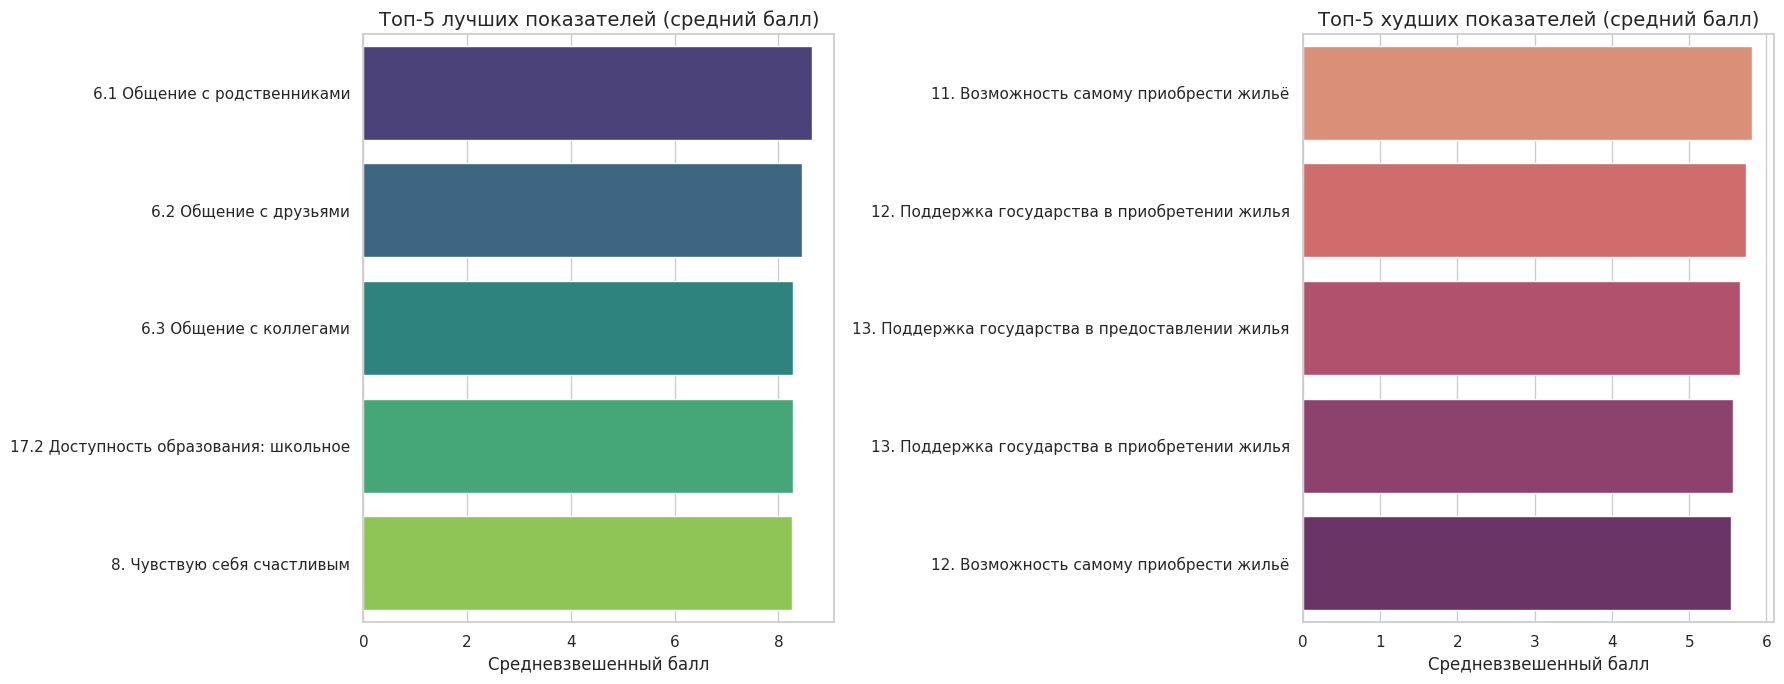

In [8]:
# 1. График: Топ-5 лучших и худших показателей по средневзвешенному баллу (общий итог)
# Берём общий итог по РК (строка «Всего») и усредняем по годам
df_overall = df[df['Местность'] == 'Всего'].groupby('Вопрос')['weighted_avg'].mean().reset_index()

top_5 = df_overall.nlargest(5, 'weighted_avg')
bottom_5 = df_overall.nsmallest(5, 'weighted_avg').sort_values('weighted_avg', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Топ-5 Лучших
sns.barplot(x='weighted_avg', y='Вопрос', data=top_5, ax=axes[0], palette='viridis', hue='Вопрос', legend=False)
axes[0].set_title('Топ-5 лучших показателей (средний балл)', fontsize=14)
axes[0].set_xlabel('Средневзвешенный балл')
axes[0].set_ylabel('')

# Топ-5 Худших
sns.barplot(x='weighted_avg', y='Вопрос', data=bottom_5, ax=axes[1], palette='flare', hue='Вопрос', legend=False)
axes[1].set_title('Топ-5 худших показателей (средний балл)', fontsize=14)
axes[1].set_xlabel('Средневзвешенный балл')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

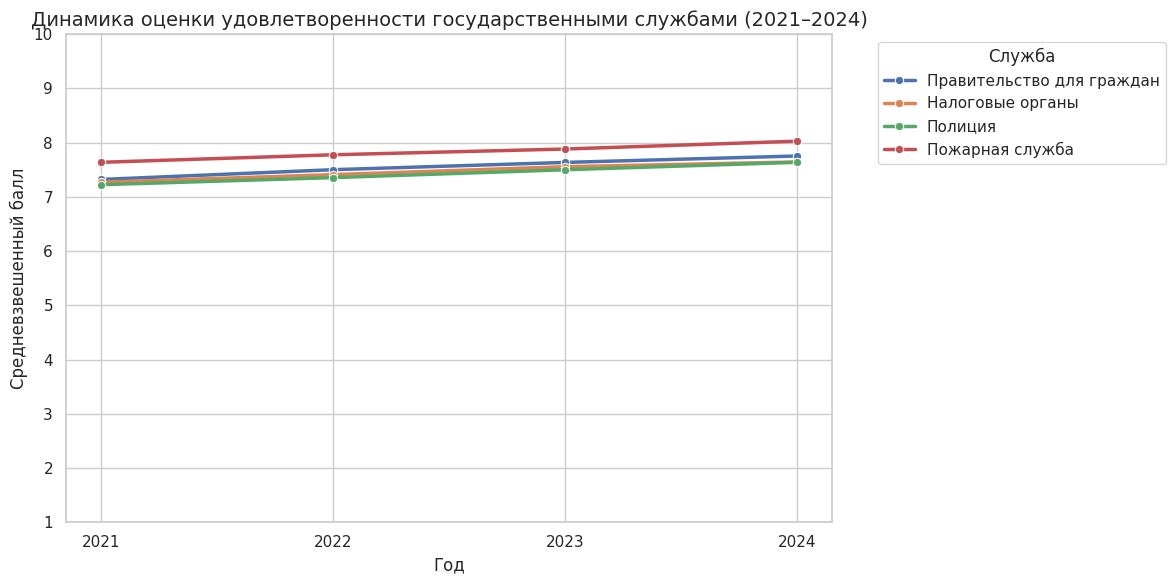

In [9]:
# 2. Линейный график по годам для выбранных служб
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Если таблица не в памяти — загружаем и пересчитываем средневзвешенный балл заново
try:
    if 'df' not in globals() or df is None or 'weighted_avg' not in df.columns:
        print("Переменная df не найдена в памяти. Подгружаем и рассчитываем средневзвешенный балл...")
        processed_path = "/content/drive/MyDrive/Datathon/d002_processed_output.csv"
        if os.path.exists(processed_path):
            df = pd.read_csv(processed_path, sep=';')
            score_cols = [col for col in df.columns if 'балл' in col.lower() and any(char.isdigit() for col_part in col.split() for char in col_part)]
            score_map = {col: [int(s) for s in col.split() if s.isdigit()][0] for col in score_cols if any(s.isdigit() for s in col.split())}
            weighted_sum = np.zeros(len(df))
            for col, val in score_map.items():
                weighted_sum += df[col].astype(float) * val
            df['weighted_avg'] = weighted_sum / 100.0
        else:
            raise FileNotFoundError(f"Файл не найден по пути: {processed_path}")
except Exception as e:
    print(f"Ошибка при подготовке данных: {e}")

# Нумерация вопросов по годам отличается, поэтому службы ищем по ключевым словам
target_map = {
    'налог': 'Налоговые органы',
    'пожар': 'Пожарная служба',
    'полиц': 'Полиция',
    'правительство для граждан': 'Правительство для граждан'
}

# Оставляем только итог по РК и размечаем службы
services_df = df[df['Местность'] == 'Всего'].copy()

def map_question_to_service(q):
    q_lower = q.lower()
    for key, standardized_name in target_map.items():
        if key in q_lower:
            return standardized_name
    return None

services_df['Служба'] = services_df['Вопрос'].apply(map_question_to_service)
services_df = services_df.dropna(subset=['Служба'])

plt.figure(figsize=(12, 6))
sns.lineplot(data=services_df, x='Год', y='weighted_avg', hue='Служба', marker='o', linewidth=2.5)
plt.title('Динамика оценки удовлетворенности государственными службами (2021–2024)', fontsize=14)
plt.xlabel('Год', fontsize=12)
plt.ylabel('Средневзвешенный балл', fontsize=12)
plt.xticks(df['Год'].unique())
plt.ylim(1, 10)
plt.legend(title='Служба', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [10]:
# Проверка полноты: какие вопросы анкеты относятся к госорганам (нумерация меняется между годами)
unique_questions = df['Вопрос'].unique()
print("=== Всего уникальных вопросов в датасете:", len(unique_questions), "===")

# Пример структуры анкеты
print("\nПример структуры первых 20 вопросов:")
for q in unique_questions[:20]:
    print(f" - {q}")

# Поиск вопросов о госорганах по корням слов
keywords = ['налог', 'пожар', 'полиц', 'граждан', 'орган', 'служб', '15.']
matching_questions = [
    q for q in unique_questions
    if any(kw in q.lower() for kw in keywords)
]

print("\n=== Найденные совпадения по ключевым словам госорганов:")
for mq in matching_questions:
    print(f" - {mq}")

=== Всего уникальных вопросов в датасете: 83 ===

Пример структуры первых 20 вопросов:
 - 1. Жизнью в целом
 - 2. Условиями жизни
 - 3. Состоянием здоровья
 - 4. Финансовым положением
 - 5. Профессиональными навыками
 - 6. Экономическим положением семьи
 - 7. Чувствую себя счастливым
 - 8.1 Безопасность от нападения
 - 8.2 Безопасность от кражи
 - 8.3 Безопасность от физ. насилия
 - 8.4 Безопасность от мошенничества
 - 8.5 Безопасность от коррупции
 - 8.6 Безопасность от дискриминации
 - 9. Качеством жилья
 - 10.1 Чистота территории у дома
 - 10.2 Чистота воздуха
 - 10.3 Качество питьевой воды
 - 11. Уровень внешнего шума
 - 12. Возможность самому приобрести жильё
 - 13. Поддержка государства в предоставлении жилья

=== Найденные совпадения по ключевым словам госорганов:
 - 15.1 Гос. здравоохранение: стоимость
 - 15.2 Гос. здравоохранение: качество
 - 15.3 Гос. здравоохранение: доступность
 - 19.1 Госкорпорация «Правительство для граждан»
 - 19.2 Налоговые органы
 - 19.3 Полиция
 - 19.

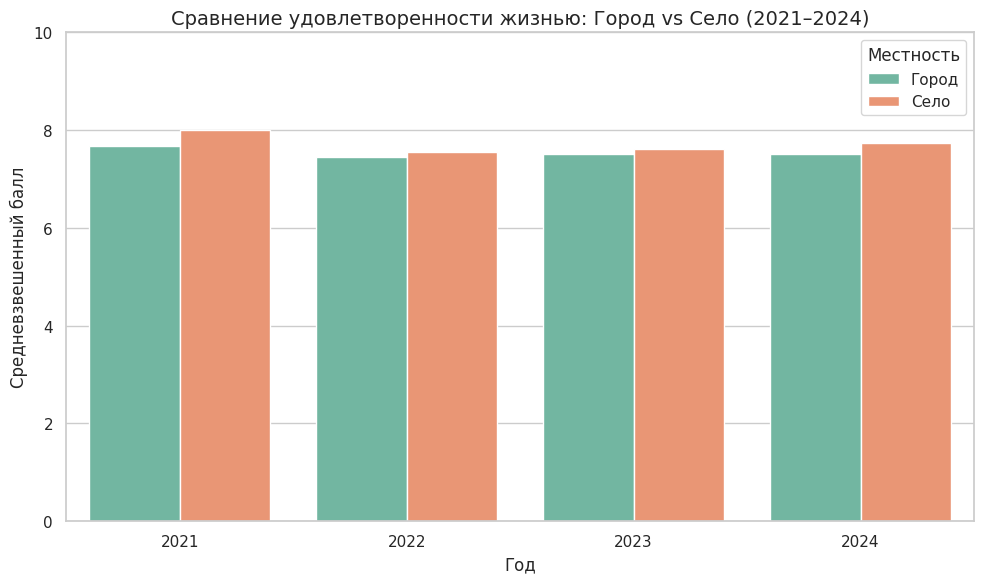

In [11]:
# 3. Удовлетворенность жизнью: Город vs Село (вертикальная гистограмма с группировкой)
# Выбираем вопрос про удовлетворенность жизнью
life_satisfaction_df = df[
    (df['Вопрос'].str.contains('жизнью в целом|удовлетворенность жизнью', case=False, na=False)) &
    (df['Местность'].isin(['Город', 'Село']))
]

plt.figure(figsize=(10, 6))
sns.barplot(data=life_satisfaction_df, x='Год', y='weighted_avg', hue='Местность', palette='Set2')
plt.title('Сравнение удовлетворенности жизнью: Город vs Село (2021–2024)', fontsize=14)
plt.xlabel('Год', fontsize=12)
plt.ylabel('Средневзвешенный балл', fontsize=12)
plt.ylim(0, 10)
plt.legend(title='Местность')
plt.tight_layout()
plt.show()

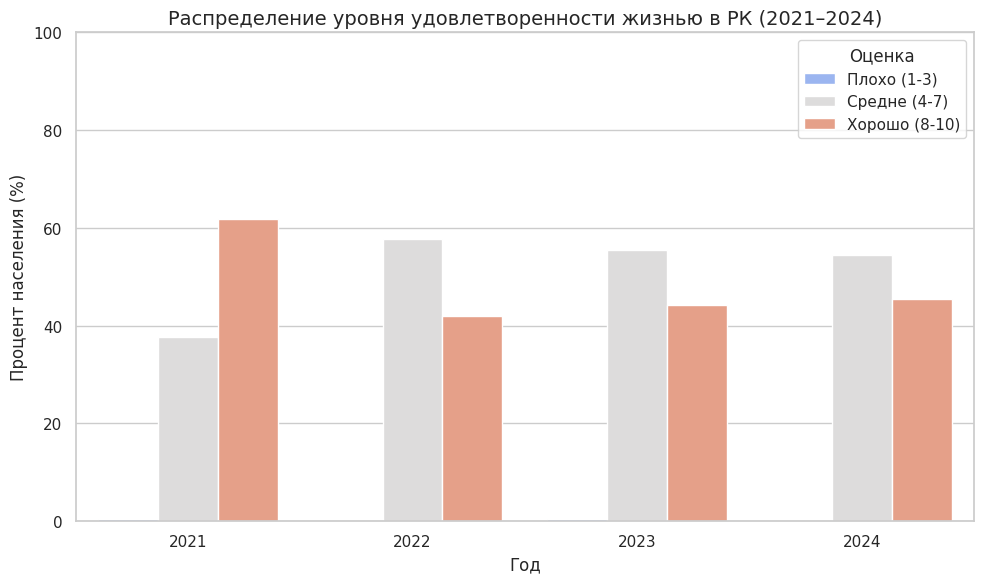

In [12]:
# 4. Процентное соотношение удовлетворенности жизнью в целом по Казахстану
# Плохо (1-3 балла), Средне (4-7 баллов), Хорошо (8-10 баллов)

# Фильтруем данные по удовлетворенности жизнью для всего Казахстана ('Всего')
life_overall_df = df[
    (df['Вопрос'].str.contains('жизнью в целом|удовлетворенность жизнью', case=False, na=False)) &
    (df['Местность'] == 'Всеgo' if 'Всеgo' in df['Местность'].values else df['Местность'] == 'Всего')
].copy()

# Оставляем только те колонки из score_cols, которые соответствуют именно баллам (исключаем технические)
actual_score_cols = [col for col in score_cols if 'балл' in col.lower()]

# Группируем колонки оценок, безопасно извлекая число
bad_cols = [col for col in actual_score_cols if score_map.get(col) in [1, 2, 3]]
medium_cols = [col for col in actual_score_cols if score_map.get(col) in [4, 5, 6, 7]]
good_cols = [col for col in actual_score_cols if score_map.get(col) in [8, 9, 10]]

# Считаем суммы процентов для каждой категории
life_overall_df['Плохо (1-3)'] = life_overall_df[bad_cols].astype(float).sum(axis=1)
life_overall_df['Средне (4-7)'] = life_overall_df[medium_cols].astype(float).sum(axis=1)
life_overall_df['Хорошо (8-10)'] = life_overall_df[good_cols].astype(float).sum(axis=1)

# Преобразуем структуру для визуализации через seaborn
plot_data = life_overall_df.melt(
    id_vars=['Год'],
    value_vars=['Плохо (1-3)', 'Средне (4-7)', 'Хорошо (8-10)'],
    var_name='Категория',
    value_name='Процент'
)

plt.figure(figsize=(10, 6))
sns.barplot(data=plot_data, x='Год', y='Процент', hue='Категория', palette='coolwarm')
plt.title('Распределение уровня удовлетворенности жизнью в РК (2021–2024)', fontsize=14)
plt.xlabel('Год', fontsize=12)
plt.ylabel('Процент населения (%)', fontsize=12)
plt.ylim(0, 100)
plt.legend(title='Оценка')
plt.tight_layout()
plt.show()

## СТРАТЕГИЧЕСКИЙ АНАЛИЗ И КЛЮЧЕВЫЕ АНАЛИТИЧЕСКИЕ ИНСАЙДЫ


---

###  1. Парадокс «Качество vs Доступность» в медицине и образовании
* **Инсайт:** Оценки физической доступности социальных услуг стабильно и существенно выше, чем оценки их качественного наполнения.
* **Детализация данных:** Респонденты демонстрируют высокий уровень удовлетворенности тем, что школы или поликлиники находятся поблизости (секция доступности). Однако при оценке квалификации медицинского персонала, технического оснащения, стоимости лекарств и реального качества обучения показатели резко просаживаются в желтую и оранжевую зоны.
* **Политический вывод (Policy):** Инфраструктурный охват и географическое покрытие со стороны государства решены успешно. Текущий приоритет реформ должен сместиться с «количественного расширения» на «качественное наполнение» и жесткий контроль стандартов госсервисов.

---

###  2. «Ножницы» финансового самочувствия и барьеры господдержки жилья
* **Инсайт:** В блоке базовых экономических показателей на протяжении всех 4 лет наблюдается хроническая просадка (преобладание критических желто-оранжевых и красных зон матрицы).
* **Детализация данных:** Минимальные показатели удовлетворенности в Казахстане стабильно удерживают три индикатора: «Возможность самостоятельно приобрести жилье», «Эффективность господдержки в приобретении жилья» и «Текущее финансовое положение». При этом общий уровень счастья и удовлетворенности жизнью в целом формально декларируется как высокий.
* **Политический вывод (Policy):** Жилищный тупик и невозможность формирования долгосрочных накоплений остаются главной «болевой точкой» общества и основным источником скрытого социального неблагополучия населения. Требуется радикальный пересмотр льготных ипотечных программ в сторону снижения первоначального взноса.

---

###  3. Цифровизация и экстренные службы — главный драйвер позитива
* **Инсайт:** Службы прямого взаимодействия гражданина и государства (ЦОН/«Правительство для граждан», Налоговые органы, Пожарная служба, Скорая помощь) демонстрируют устойчивый, растущий из года в год зеленый тренд.
* **Детализация данных:** За период 2021–2024 гг. доля положительных оценок («хорошо») в этих секциях показывает стабильный прирост. Данный позитивный тренд синхронно наблюдается как в крупных городах, так и в отдаленной сельской местности.
* **Политический вывод (Policy):** Стратегические реформы в сфере цифровизации госуслуг (E-Gov) и модернизации экстренных служб дали наиболее ощутимый, быстрый и верифицируемый результат в глазах населения. Этот опыт необходимо масштабировать на другие ведомства.

---

###  4. Социальный капитал как «амортизатор» институционального стресса
* **Инсайт:** Показатели доверия к государственным и экономическим институтам значительно ниже, чем показатели прочности межличностных связей внутри общества.
* **Детализация данных:** Блоки «Общение с родственниками / друзьями / коллегами» и «Уверенность в получении моральной поддержки в кризисной ситуации» на протяжении всего периода наблюдений окрашены в ярко-зеленый цвет (высокий % ответов на 8–10 баллов).
* **Политический вывод (Policy):** Высокий уровень социального капитала и прочные семейные/родственные связи в Казахстане выступают естественным «психологическим амортизатором». Граждане компенсируют недовольство экономическими барьерами (доход, жилье) за счет поддержки личного окружения. При этом государству важно не полагаться на этот фактор, а снижать системную уязвимость бюджетов.

---

###  5. Структурная специфика урбанизации (Диспропорции Город / Село)
* **Инсайт:** Сельские территории демонстрируют колоссальное лидерство по экологическим факторам и безопасности, но критически проигрывают городу в доступе к рыночным сервисам.
* **Детализация данных:**
  * *Преимущества села:* Абсолютное преобладание зеленых зон по показателям «Чистота воздуха», «Уровень внешнего шума» и «Личная безопасность от нападений/краж».
  * *Преимущества города:* Высокая удовлетворенность доступностью частной медицины, коммерческих услуг, скоростного интернета и разнообразием культурного досуга.
* **Политический вывод (Policy):** Диспропорция между городом и селом носит глубокий структурный характер. В городе выше качество материальной инфраструктуры, но значительно хуже экологическая и эмоциональная комфортность среды. Государственная политика должна быть дифференцированной: селу нужны рыночные услуги и инфраструктура, городу — жесткие экологические стандарты и снижение уровня шума.


## Анализ D004 — расходы и доходы домохозяйств
Модуль `d004 / kv_vopr0..kv_vopr12`: квартальные бюджеты семей за 16 кварталов (2021–2024).

In [13]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
from pathlib import Path
import textwrap

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Пути к исходным данным и к папке с результатами
folder = Path('/content/drive/MyDrive/Datathon/synthetic_microdata_2021-2024_20260921')
output_folder = Path('/content/drive/MyDrive/Datathon/results_d004')

assert folder.exists(), "Папка с данными не найдена: распакуйте архив в /content/data"

# Единое оформление таблиц в блокноте
def _fmt(v):
    if isinstance(v, float):
        return "" if pd.isna(v) else f"{v:,.1f}".replace(",", " ")
    return v

def show(df):
    if not isinstance(df, pd.DataFrame):
        display(df)
        return
    try:
        display(
            df.style
            .set_table_styles([
                {"selector": "th", "props": [("background-color", "#7155B5"),
                                              ("color", "white"),
                                              ("text-align", "center"),
                                              ("padding", "4px 8px")]},
                {"selector": "td", "props": [("border", "1px solid #ddd"),
                                              ("padding", "4px 8px")]},
            ])
            .format(_fmt)
        )
    except Exception:
        display(df)

In [15]:
# Папки с данными D004. Находим папки `d004` с данными и считаем CSV-файлы по годам.
d004_folders = sorted(p for p in folder.rglob("d004")
                      if p.is_dir() and "documentation" not in p.parts)

print("Найдено папок d004 с данными:", len(d004_folders))

for path in d004_folders:
    print("\nПапка:", path)

    for year in sorted(path.iterdir()):
        if year.is_dir():
            csv_files = list(year.rglob("*.csv"))
            print(f"{year.name}: {len(csv_files)} CSV-файлов")

Найдено папок d004 с данными: 1

Папка: /content/drive/MyDrive/Datathon/synthetic_microdata_2021-2024_20260921/d004
2021: 48 CSV-файлов
2022: 48 CSV-файлов
2023: 48 CSV-файлов
2024: 48 CSV-файлов


In [16]:
# Обзор таблиц одного квартала. Берём 1 квартал 2024 года и смотрим размеры каждой таблицы: строки, столбцы, число домохозяйств.
d004_path = d004_folders[0]
quarter_path = d004_path / "2024" / "1kv"

overview = []

for file in sorted(quarter_path.glob("*.csv")):
    table = pd.read_csv(file)

    overview.append({
        "Таблица": file.name,
        "Строк": len(table),
        "Столбцов": len(table.columns),
        "Домохозяйств": table["NOMER"].nunique()
    })

show(pd.DataFrame(overview))

,Таблица,Строк,Столбцов,Домохозяйств
0,kv_vopr0.csv,12000,6,12000
1,kv_vopr1.csv,269130,10,11958
2,kv_vopr10.csv,8107,12,5003
3,kv_vopr11.csv,24535,33,11913
4,kv_vopr12.csv,6882,12,4235
5,kv_vopr2.csv,65466,9,11958
6,kv_vopr3.csv,26191,8,11957
7,kv_vopr4.csv,2843,8,2381
8,kv_vopr5.csv,4511,8,3394
9,kv_vopr6.csv,44054,10,11645


In [17]:
# Участие в обследовании и проверка сумм. Коды участия `REZ` (1 — участвовали, 2 — отказались) и проверка сумм `STOIMK` в таблицах `kv_vopr1–7`: пропуски, отрицательные и нулевые значения.
participants = pd.read_csv(quarter_path / "kv_vopr0.csv")

print("Коды участия: 1 — участвовали, 2 — отказались")
print(participants["REZ"].value_counts(dropna=False))

checks = []

for number in range(1, 8):
    file = quarter_path / f"kv_vopr{number}.csv"
    table = pd.read_csv(file)
    amounts = pd.to_numeric(table["STOIMK"], errors="coerce")

    checks.append({
        "Таблица": file.name,
        "Строк": len(table),
        "Пропуски / нечисловые суммы": amounts.isna().sum(),
        "Отрицательные суммы": (amounts < 0).sum(),
        "Нулевые суммы": (amounts == 0).sum()
    })

show(pd.DataFrame(checks))

Коды участия: 1 — участвовали, 2 — отказались
REZ
1    11960
2       40
Name: count, dtype: int64


,Таблица,Строк,Пропуски / нечисловые суммы,Отрицательные суммы,Нулевые суммы
0,kv_vopr1.csv,269130,0,0,0
1,kv_vopr2.csv,65466,0,0,0
2,kv_vopr3.csv,26191,0,0,0
3,kv_vopr4.csv,2843,0,0,0
4,kv_vopr5.csv,4511,0,0,0
5,kv_vopr6.csv,44054,0,0,0
6,kv_vopr7.csv,16355,0,0,0


In [18]:
# Загрузка всех кварталов 2021–2024. Собираем в одну таблицу расходы (`kv_vopr1–7`) и данные об участии (`kv_vopr0`) за 16 кварталов. Это самая долгая ячейка.
expenses = []
participation = []
audit = []

for year in range(2021, 2025):
    for quarter in range(1, 5):
        path = d004_path / str(year) / f"{quarter}kv"

        people = pd.read_csv(path / "kv_vopr0.csv")
        people["year"] = year
        people["quarter"] = quarter
        participation.append(people)

        for number in range(1, 8):
            table = pd.read_csv(path / f"kv_vopr{number}.csv")
            table["STOIMK"] = pd.to_numeric(
                table["STOIMK"], errors="coerce"
            )

            table["year"] = year
            table["quarter"] = quarter
            table["section"] = number
            expenses.append(table)

            audit.append({
                "Год": year,
                "Строк расходов": len(table),
                "Пропуски сумм": table["STOIMK"].isna().sum(),
                "Отрицательные суммы": (table["STOIMK"] < 0).sum(),
                "Нулевые суммы": (table["STOIMK"] == 0).sum()
            })

expenses = pd.concat(expenses, ignore_index=True)
participation = pd.concat(participation, ignore_index=True)

print("Загружено таблиц расходов:", len(audit))
show(pd.DataFrame(audit).groupby("Год").sum())

Загружено таблиц расходов: 112


,Строк расходов,Пропуски сумм,Отрицательные суммы,Нулевые суммы
Год,,,,
2021,1687215,0,0,0
2022,1715510,0,0,0
2023,1725231,0,0,0
2024,1720367,0,0,0


In [19]:
# Первые строки таблицы расходов. Контрольный просмотр объединённой таблицы расходов.
show(
        expenses[["year", "quarter", "section", "NOMER", "STOIMK"]]
        .head(10)
)

,year,quarter,section,NOMER,STOIMK
0,2021,1,1,2021000001,6000
1,2021,1,1,2021000001,10000
2,2021,1,1,2021000001,2000
3,2021,1,1,2021000001,10000
4,2021,1,1,2021000001,8000
5,2021,1,1,2021000001,1500
6,2021,1,1,2021000001,36000
7,2021,1,1,2021000001,3600
8,2021,1,1,2021000001,18000
9,2021,1,1,2021000001,16900


In [20]:
# Оставляем только участников. Присоединяем код участия и оставляем расходы домохозяйств с `REZ = 1`.
keys = ["year", "quarter", "NOMER"]

expenses_checked = expenses.merge(
    participation[keys + ["REZ"]],
    on=keys,
    how="left",
    validate="many_to_one"
)

print("Количество записей расходов по коду участия:")
print(expenses_checked["REZ"].value_counts(dropna=False))

expenses_valid = expenses_checked[
    expenses_checked["REZ"] == 1
].copy()

print("\nЗаписей расходов участников:", len(expenses_valid))
print("Записей вне расчёта:",
      len(expenses_checked) - len(expenses_valid))

Количество записей расходов по коду участия:
REZ
1    6848323
Name: count, dtype: int64

Записей расходов участников: 6848323
Записей вне расчёта: 0


In [21]:
# Расходы по разделам и годам. Суммы записанных расходов по семи разделам, млн тенге.
section_names = {
    1: "Непродовольственные товары",
    2: "Жильё, коммунальные услуги и топливо",
    3: "Связь",
    4: "Образование",
    5: "Здравоохранение",
    6: "Прочие услуги и финансовые расходы",
    7: "Транспорт"
}

section_totals = (
    expenses_valid
    .groupby(["section", "year"])["STOIMK"]
    .sum()
    .unstack("year")
    .rename(index=section_names)
)

print("Суммы записанных расходов по разделам, млн тенге:")
show((section_totals / 1_000_000).round(2))

Суммы записанных расходов по разделам, млн тенге:


year,2021,2022,2023,2024
section,,,,
Непродовольственные товары,6 541.9,7 838.9,8 656.1,8 938.4
"Жильё, коммунальные услуги и топливо",1 859.1,2 043.7,2 245.3,2 512.2
Связь,1 026.5,1 160.5,1 321.4,1 479.0
Образование,341.0,498.1,627.2,656.7
Здравоохранение,395.2,439.6,540.5,540.1
Прочие услуги и финансовые расходы,1 740.4,2 097.5,2 548.5,2 837.1
Транспорт,586.5,733.8,834.9,915.0


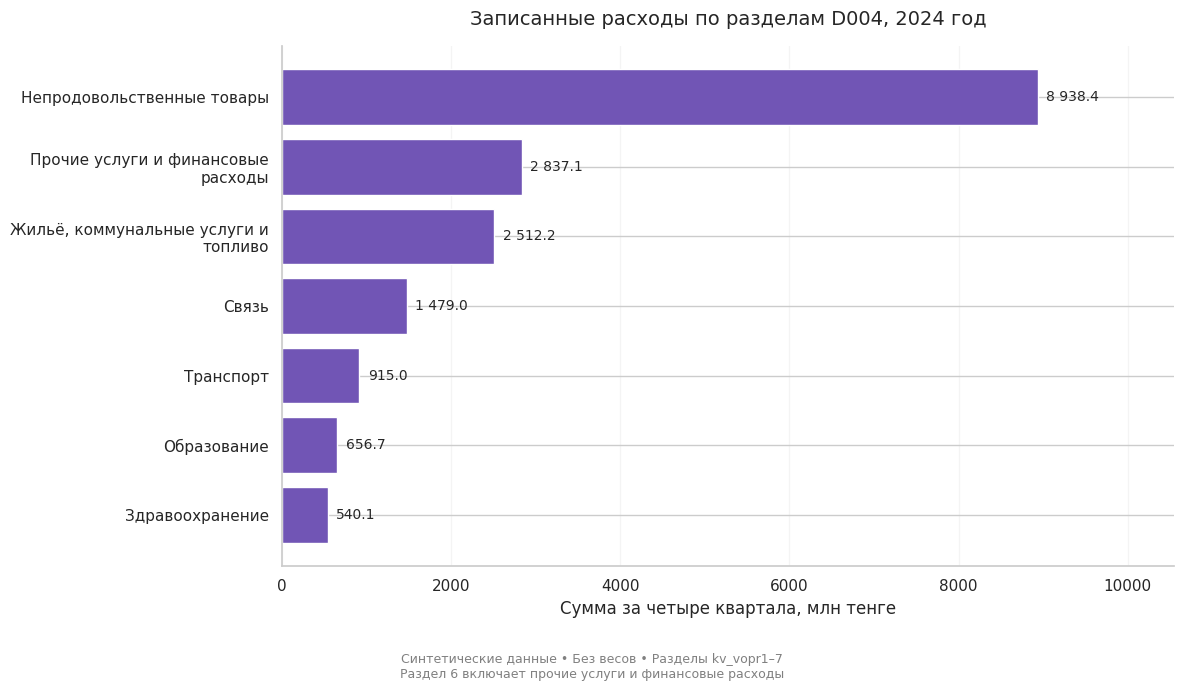

In [22]:
# График: расходы по разделам, 2024. Столбчатая диаграмма сумм по разделам за 2024 год.
values = (section_totals[2024] / 1_000_000).sort_values()
labels = [textwrap.fill(name, width=30) for name in values.index]

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(labels, values.values, color="#7155B5")

ax.bar_label(
    bars,
    labels=[f"{v:,.1f}".replace(",", " ") for v in values],
    padding=6,
    fontsize=10
)

ax.set_title("Записанные расходы по разделам D004, 2024 год",
             fontsize=14, pad=15)
ax.set_xlabel("Сумма за четыре квартала, млн тенге")
ax.set_xlim(0, values.max() * 1.18)
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.2)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.text(
    0.5, 0.02,
    "Синтетические данные • Без весов • Разделы kv_vopr1–7\n"
    "Раздел 6 включает прочие услуги и финансовые расходы",
    ha="center", fontsize=9, color="gray"
)

plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()

In [23]:
# Средние квартальные расходы на домохозяйство. Делим суммы на число участвовавших домохозяйств и усредняем четыре квартала каждого года.
# Количество участвовавших домохозяйств в каждом квартале
household_counts = (
    participation[participation["REZ"] == 1]
    .groupby(["year", "quarter"])["NOMER"]
    .nunique()
)

# Суммы по каждому разделу, году и кварталу
quarter_totals = (
    expenses_valid
    .groupby(["year", "quarter", "section"])["STOIMK"]
    .sum()
    .unstack("section")
)

# Делим суммы на число участников соответствующего квартала
quarter_means = quarter_totals.div(household_counts, axis=0)

# Среднее из четырёх квартальных показателей каждого года
year_means = (
    quarter_means.groupby(level="year")
    .mean()
    .rename(columns=section_names)
)

print("Средние записанные расходы за квартал")
print("на одно участвовавшее домохозяйство, тенге:")
show(year_means.round(0).T)

Средние записанные расходы за квартал
на одно участвовавшее домохозяйство, тенге:


year,2021,2022,2023,2024
section,,,,
Непродовольственные товары,138 720.0,165 670.0,182 984.0,189 273.0
"Жильё, коммунальные услуги и топливо",39 425.0,43 189.0,47 441.0,53 167.0
Связь,21 762.0,24 524.0,27 921.0,31 304.0
Образование,7 230.0,10 524.0,13 247.0,13 897.0
Здравоохранение,8 376.0,9 290.0,11 423.0,11 433.0
Прочие услуги и финансовые расходы,36 898.0,44 332.0,53 853.0,60 056.0
Транспорт,12 437.0,15 508.0,17 643.0,19 373.0


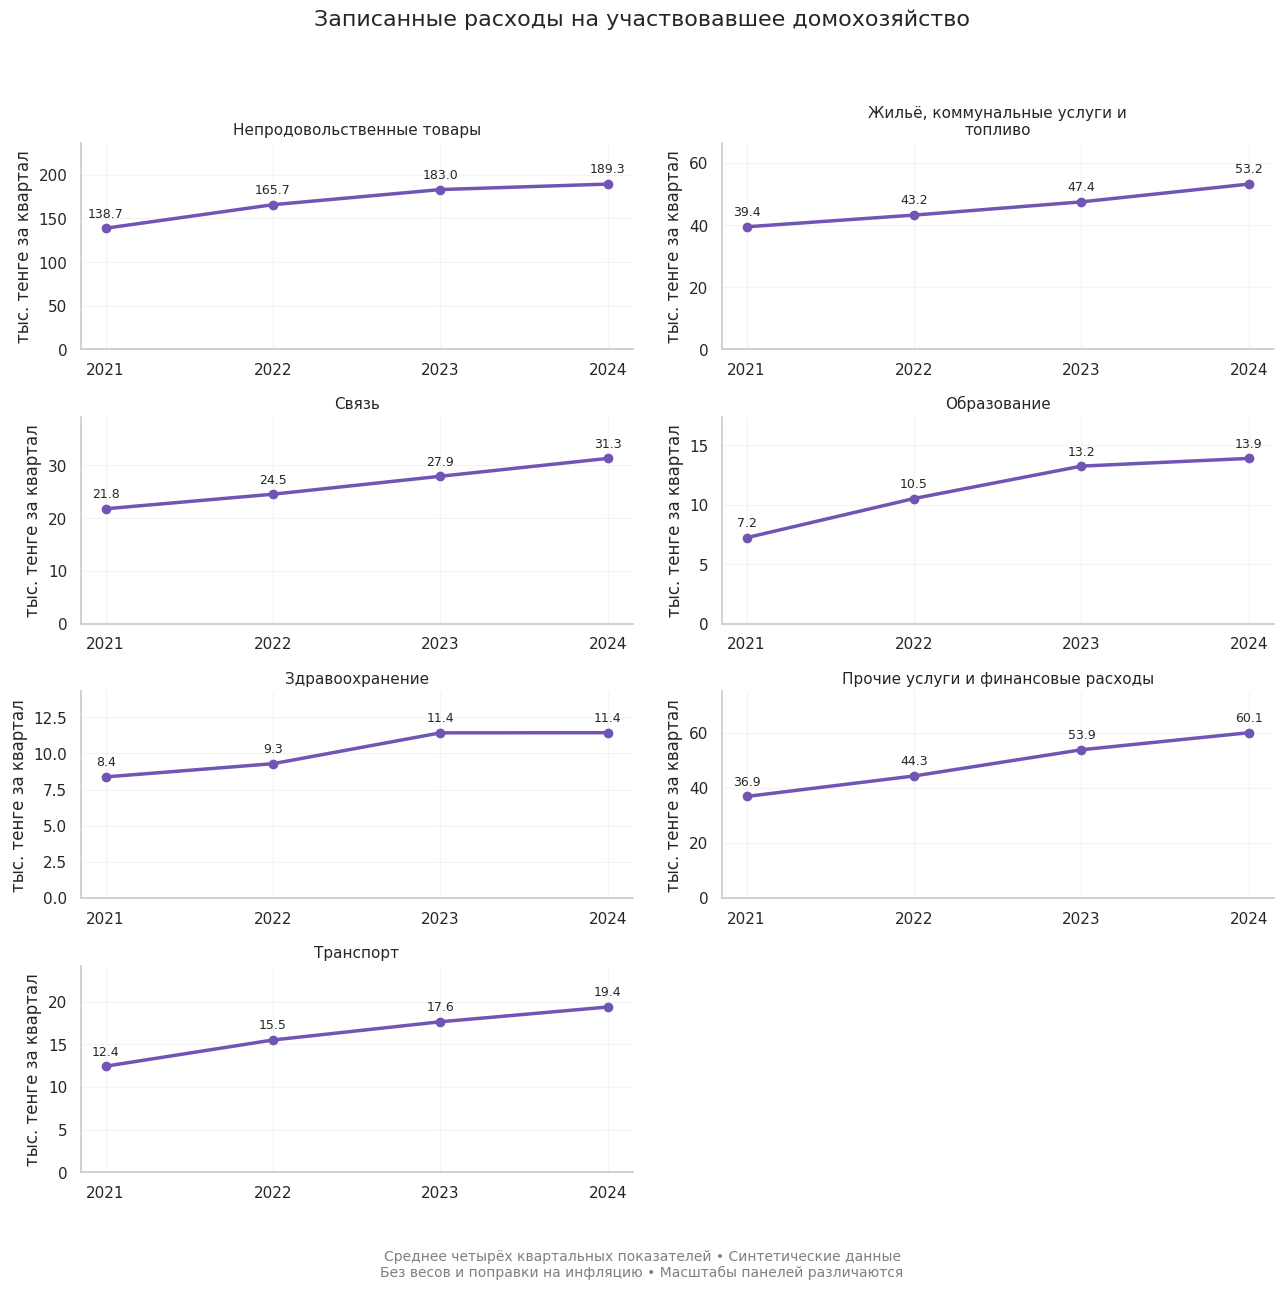

In [24]:
# График: динамика по разделам. Панели с динамикой средних расходов по каждому разделу, 2021–2024.
fig2, axes = plt.subplots(4, 2, figsize=(13, 13))
axes = axes.flatten()

for ax, name in zip(axes, year_means.columns):
    values = year_means[name] / 1000

    ax.plot(
        values.index, values.values,
        marker="o", linewidth=2.5, color="#7155B5"
    )

    for year, value in values.items():
        ax.annotate(
            f"{value:.1f}",
            (year, value),
            xytext=(0, 8),
            textcoords="offset points",
            ha="center", fontsize=9
        )

    ax.set_title(textwrap.fill(name, 35), fontsize=11)
    ax.set_xticks([2021, 2022, 2023, 2024])
    ax.set_ylabel("тыс. тенге за квартал")
    ax.set_ylim(0, values.max() * 1.25)
    ax.grid(alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[-1].axis("off")

fig2.suptitle(
    "Записанные расходы на участвовавшее домохозяйство",
    fontsize=16, y=0.99
)

fig2.text(
    0.5, 0.015,
    "Среднее четырёх квартальных показателей • Синтетические данные\n"
    "Без весов и поправки на инфляцию • Масштабы панелей различаются",
    ha="center", fontsize=10, color="gray"
)

plt.tight_layout(rect=[0, 0.06, 1, 0.96])
plt.show()

In [25]:
# Раздел 6: какие коды в него входят. Раздел 6 смешанный: смотрим сочетания кодов `KOD` и `NOMVOPR`.
section6 = expenses_valid[expenses_valid["section"] == 6]

print("Сочетания кодов в шестом разделе:")
show(
    section6.groupby(
        ["year", "KOD", "NOMVOPR"], dropna=False
    ).agg(
        Строк=("STOIMK", "size"),
        Сумма=("STOIMK", "sum")
    ).reset_index()
)

Сочетания кодов в шестом разделе:


,year,KOD,NOMVOPR,Строк,Сумма
0,2021,,60.0,9099,118120759
1,2021,,61.0,117539,999256629
2,2021,,62.0,27477,622991499
3,2022,,60.0,17955,256930091
4,2022,,61.0,120552,1131413907
5,2022,,62.0,28031,709189062
6,2023,,60.0,21993,362108743
7,2023,,61.0,127058,1408241700
8,2023,,62.0,27117,778192043
9,2024,,60.0,24915,438308105


In [26]:
# Раздел 6: детализация на три категории. Отдых и культура (60), индивидуальные и прочие услуги (61), прочие финансовые расходы (62).
detail_names = {
    60: "Отдых и культура",
    61: "Индивидуальные и прочие услуги",
    62: "Прочие финансовые расходы"
}

section6_totals = (
    section6.groupby(["NOMVOPR", "year"])["STOIMK"]
    .sum()
    .unstack("year")
    .rename(index=detail_names)
)

print("Детализация шестого раздела, млн тенге:")
show((section6_totals / 1_000_000).round(2))

Детализация шестого раздела, млн тенге:


year,2021,2022,2023,2024
NOMVOPR,,,,
Отдых и культура,118.1,256.9,362.1,438.3
Индивидуальные и прочие услуги,999.3,1 131.4,1 408.2,1 546.3
Прочие финансовые расходы,623.0,709.2,778.2,852.5


In [27]:
# Средние расходы по 9 категориям. Заменяем общий раздел 6 тремя подробными категориями и пересчитываем средние на домохозяйство.
# Суммы по трём категориям раздела 6 за каждый квартал
detail_quarter_totals = (
    section6.groupby(["year", "quarter", "NOMVOPR"])["STOIMK"]
    .sum()
    .unstack("NOMVOPR")
)

# Делим на число участвовавших домохозяйств
detail_quarter_means = detail_quarter_totals.div(
    household_counts, axis=0
)

# Среднее четырёх кварталов каждого года
detail_year_means = (
    detail_quarter_means.groupby(level="year")
    .mean()
    .rename(columns=detail_names)
)

# Заменяем общий раздел 6 тремя подробными категориями
final_year_means = pd.concat(
    [
        year_means.drop(columns=[section_names[6]]),
        detail_year_means
    ],
    axis=1
)

print("Средние квартальные расходы на участвовавшее домохозяйство, тенге")
print("Синтетические данные • Без весов и поправки на инфляцию")

show(final_year_means.T.round(0))

Средние квартальные расходы на участвовавшее домохозяйство, тенге
Синтетические данные • Без весов и поправки на инфляцию


year,2021,2022,2023,2024
Непродовольственные товары,138 720.0,165 670.0,182 984.0,189 273.0
"Жильё, коммунальные услуги и топливо",39 425.0,43 189.0,47 441.0,53 167.0
Связь,21 762.0,24 524.0,27 921.0,31 304.0
Образование,7 230.0,10 524.0,13 247.0,13 897.0
Здравоохранение,8 376.0,9 290.0,11 423.0,11 433.0
Транспорт,12 437.0,15 508.0,17 643.0,19 373.0
Отдых и культура,2 505.0,5 431.0,7 651.0,9 281.0
Индивидуальные и прочие услуги,21 184.0,23 910.0,29 761.0,32 739.0
Прочие финансовые расходы,13 209.0,14 991.0,16 442.0,18 036.0


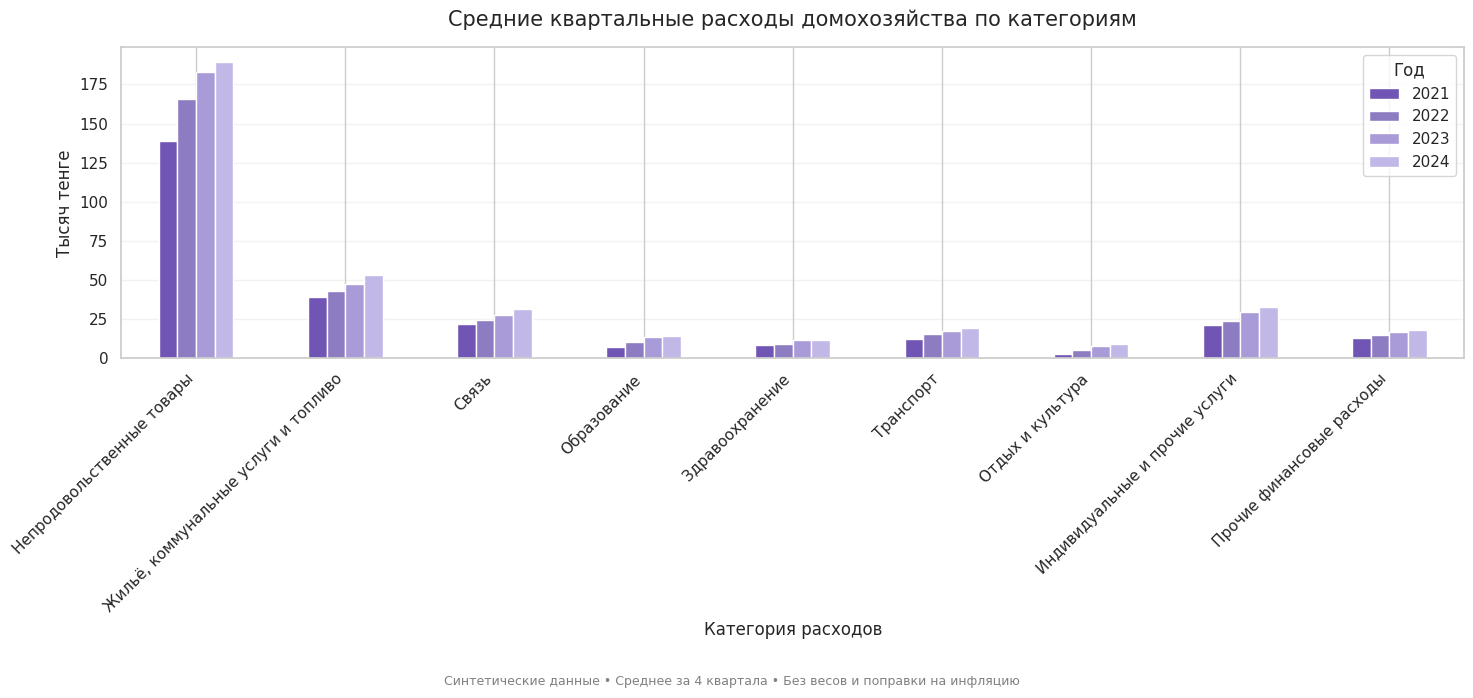

In [28]:
# График: расходы по 9 категориям. Категории по горизонтали, годы в легенде.
# Категории расходов по горизонтали, годы — в легенде

plot_data = final_year_means.T / 1000

ax = plot_data.plot(
    kind="bar",
    figsize=(15, 7),
    color=["#7155B5", "#8E7CC3", "#A99AD8", "#C2B8E8"],
    edgecolor="white"
)

ax.set_title(
    "Средние квартальные расходы домохозяйства по категориям",
    fontsize=15,
    pad=15
)
ax.set_xlabel("Категория расходов")
ax.set_ylabel("Тысяч тенге")
ax.set_xticklabels(plot_data.index, rotation=45, ha="right")
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Год")

plt.figtext(
    0.5, 0.01,
    "Синтетические данные • Среднее за 4 квартала • Без весов и поправки на инфляцию",
    ha="center",
    fontsize=9,
    color="gray"
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

In [29]:
# Рост расходов 2021 → 2024. Таблица изменений по категориям в тысячах тенге и в процентах.
# Выбираем строки за нужные годы
values_2021 = final_year_means.loc[2021]
values_2024 = final_year_means.loc[2024]

growth_table = pd.DataFrame({
    "2021, тыс. тг": values_2021 / 1000,
    "2024, тыс. тг": values_2024 / 1000,
    "Изменение, тыс. тг": (values_2024 - values_2021) / 1000,
    "Рост, %": (values_2024 / values_2021 - 1) * 100
})

show(
    growth_table.sort_values("Рост, %", ascending=False).round(1)
)

,"2021, тыс. тг","2024, тыс. тг","Изменение, тыс. тг","Рост, %"
Отдых и культура,2.5,9.3,6.8,270.5
Образование,7.2,13.9,6.7,92.2
Транспорт,12.4,19.4,6.9,55.8
Индивидуальные и прочие услуги,21.2,32.7,11.6,54.5
Связь,21.8,31.3,9.5,43.8
Прочие финансовые расходы,13.2,18.0,4.8,36.5
Здравоохранение,8.4,11.4,3.1,36.5
Непродовольственные товары,138.7,189.3,50.6,36.4
"Жильё, коммунальные услуги и топливо",39.4,53.2,13.7,34.9


In [30]:
# Проверка кодов расходов в разделе 6. Сколько разных кодов в каждой категории по годам и не переходят ли коды между категориями.
# Сколько разных кодов расходов входит в каждую категорию по годам
code_counts = (
    section6.groupby(["NOMVOPR", "year"])["KODNU"]
    .nunique()
    .unstack("year")
    .rename(index=detail_names)
)

print("Количество разных кодов расходов по категориям:")
show(code_counts)

# Проверяем, встречался ли один код в разных категориях
code_categories = section6.groupby("KODNU")["NOMVOPR"].nunique()
changed_codes = code_categories[code_categories > 1].index

print("Кодов, встречавшихся в разных категориях:", len(changed_codes))

if len(changed_codes) > 0:
    show(
        section6.loc[
            section6["KODNU"].isin(changed_codes),
            ["year", "KODNU", "NOMVOPR"]
        ]
        .drop_duplicates()
        .sort_values(["KODNU", "year", "NOMVOPR"])
        .head(30)
    )

Количество разных кодов расходов по категориям:


year,2021,2022,2023,2024
NOMVOPR,,,,
Отдых и культура,22,24,24,24
Индивидуальные и прочие услуги,38,38,38,38
Прочие финансовые расходы,14,14,14,14


Кодов, встречавшихся в разных категориях: 0


In [31]:
# Отдых и культура: расчёт по общим кодам. Пересчитываем категорию только по кодам, которые есть во все четыре года, чтобы рост не объяснялся появлением новых кодов.
# Коды отдыха и культуры, встречающиеся в каждом из четырёх лет
culture = section6[section6["NOMVOPR"] == 60]

years_per_code = culture.groupby("KODNU")["year"].nunique()
common_codes = years_per_code[years_per_code == 4].index

# Расчёт только по общим кодам
culture_common = culture[culture["KODNU"].isin(common_codes)]

common_quarter_totals = (
    culture_common.groupby(["year", "quarter"])["STOIMK"].sum()
)

common_year_means = (
    common_quarter_totals.div(household_counts)
    .groupby(level="year").mean()
)

comparison = pd.DataFrame({
    "Все коды, тенге": final_year_means["Отдых и культура"],
    "Общие коды, тенге": common_year_means
})

show(comparison.round(0))

growth_common = (
    common_year_means.loc[2024] / common_year_means.loc[2021] - 1
) * 100

print("Рост по общим кодам:", round(growth_common, 1), "%")

,"Все коды, тенге","Общие коды, тенге"
year,,
2021,2 505.0,2 505.0
2022,5 431.0,5 378.0
2023,7 651.0,7 583.0
2024,9 281.0,9 149.0


Рост по общим кодам: 265.3 %


In [32]:
# Столбцы таблиц. Какие столбцы есть в таблицах участия и расходов.
print("Столбцы таблицы участия:")
print(participation.columns.tolist())

print("\nСтолбцы таблиц расходов:")
print(expenses_valid.columns.tolist())

Столбцы таблицы участия:
['TE', 'K', 'REZ', 'KVARTAL', 'GOD', 'NOMER', 'year', 'quarter']

Столбцы таблиц расходов:
['TE', 'K', 'KODNU', 'CELPOK', 'STOIMK', 'KVARTAL', 'PRIZ', 'GOD', 'NOMER', 'year', 'quarter', 'section', 'NOMVOPR', 'TIME', 'KOD', 'NOMOTV', 'MESTPOK', 'REZ']


In [33]:
# Поиск упоминаний весов в руководстве. Проверяем, есть ли в руководстве к данным указание на веса. Строки со словом `font-` пропускаются: это CSS-оформление, а не упоминание весов.
# Ищем пояснения о весах в руководстве к данным
guide_files = [
    p for p in d004_path.parent.rglob("*")
    if p.is_file()
    and "data-guide" in p.name.lower()
    and p.suffix.lower() in [".rmd", ".md", ".txt", ""]
]

found = False

for path in guide_files:
    lines = path.read_text(encoding="utf-8", errors="replace").splitlines()

    for i, line in enumerate(lines):
        if any(word in line.lower() for word in [
            "weight", "весов", "взвеш", "веса", "вес "
        ]) and "font-" not in line.lower():
            found = True
            print(f"\nФайл: {path.name}, строка {i + 1}")
            print("\n".join(lines[max(0, i - 2):i + 3]))

if not found:
    print("Упоминаний весов в проверенных текстовых руководствах не найдено.")

print("\nПроверено файлов:", len(guide_files))

Упоминаний весов в проверенных текстовых руководствах не найдено.

Проверено файлов: 1


In [34]:
# Документация D004. Какие файлы документации лежат рядом с данными. Нужна папка `documentation` из архива.
docs_path = d004_path.parent / "documentation" / "d004"

print("Документация d004:")

if docs_path.exists():
    for path in sorted(docs_path.rglob("*")):
        if path.is_file() and path.suffix.lower() in [
            ".doc", ".docx", ".pdf", ".xls", ".xlsx", ".txt"
        ]:
            print(path.relative_to(docs_path))
else:
    print("Папка не найдена:", docs_path)

Документация d004:
2021/Структура D004.doc
2021/д004 форма рус.pdf
2021/коды/kv_vopr1 (непроды).xls
2021/коды/kv_vopr12_Заемные средства.xls
2021/коды/kv_vopr2(коммунальные).xls
2021/коды/kv_vopr3(связь).xls
2021/коды/kv_vopr4(образование).xls
2021/коды/kv_vopr5(здравоохранение).xls
2021/коды/kv_vopr6 (индивидуальные).xls
2021/коды/kv_vopr6 (отдых и культура).xls
2021/коды/kv_vopr6(проч_финансовые_расходы).xls
2021/коды/kv_vopr7(транспорт).xls
2021/коды/kv_vopr9_10 (производство -Раздел4).xls
2022/Структура D004.doc
2022/д004 форма рус.pdf
2022/коды/kv_vopr1 (непроды).xls
2022/коды/kv_vopr12_Заемные средства.xls
2022/коды/kv_vopr2(коммунальные).xls
2022/коды/kv_vopr3(связь).xls
2022/коды/kv_vopr4(образование).xls
2022/коды/kv_vopr5(здравоохранение).xls
2022/коды/kv_vopr6 (индивидуальные).xls
2022/коды/kv_vopr6 (отдых и культура).xls
2022/коды/kv_vopr6(проч_финансовые_расходы).xls
2022/коды/kv_vopr7(транспорт).xls
2022/коды/kv_vopr9_10 (производство -Раздел4).xls
2023/Структура D004.doc

In [35]:
# Цели покупки непродовольственных товаров. Записи и суммы по полю `CELPOK` в разделе 1.
# Проверяем цели покупки непродовольственных товаров
purchase_purpose = (
    expenses_valid[expenses_valid["section"] == 1]
    .groupby(["year", "CELPOK"], dropna=False)
    .agg(
        Записей=("STOIMK", "size"),
        Сумма_тенге=("STOIMK", "sum")
    )
    .reset_index()
)

show(purchase_purpose)

,year,CELPOK,Записей,Сумма_тенге
0,2021,1.0,1084790,6478890974
1,2021,2.0,7530,62142309
2,2021,9.0,124,890061
3,2022,1.0,1097743,7754173631
4,2022,2.0,6877,83885668
5,2022,9.0,119,836052
6,2023,1.0,1089642,8515081686
7,2023,2.0,9317,132475202
8,2023,9.0,627,8569812
9,2024,1.0,1085394,8824776183


In [36]:
# Доли целей покупки. Личное потребление, подарок, другое: доля в расходах по годам.
purpose_names = {
    1: "Личное потребление",
    2: "Подарок",
    9: "Другое"
}

purpose_summary = purchase_purpose.copy()

purpose_summary["Цель покупки"] = (
    purpose_summary["CELPOK"].map(purpose_names)
)

year_totals = (
    purpose_summary.groupby("year")["Сумма_тенге"].transform("sum")
)

purpose_summary["Доля расходов, %"] = (
    purpose_summary["Сумма_тенге"] / year_totals * 100
)

show(
    purpose_summary.pivot(
        index="Цель покупки",
        columns="year",
        values="Доля расходов, %"
    ).round(2)
)

year,2021,2022,2023,2024
Цель покупки,,,,
Другое,0.0,0.0,0.1,0.1
Личное потребление,99.0,98.9,98.4,98.7
Подарок,0.9,1.1,1.5,1.2


In [37]:
# Сохранение таблиц в CSV. Сохраняем итоговые таблицы в папку результатов.
output_folder.mkdir(parents=True, exist_ok=True)

final_year_means.T.to_csv(
    output_folder / "01_quarterly_expenses.csv",
    sep=";", decimal=",", encoding="utf-8-sig"
)

growth_table.to_csv(
    output_folder / "02_growth_2021_2024.csv",
    sep=";", decimal=",", encoding="utf-8-sig"
)

purpose_summary.to_csv(
    output_folder / "03_purchase_purposes.csv",
    sep=";", decimal=",", encoding="utf-8-sig",
    index=False
)

comparison.to_csv(
    output_folder / "04_culture_comparison.csv",
    sep=";", decimal=",", encoding="utf-8-sig"
)

print("Таблицы сохранены в:", output_folder)
for file in sorted(output_folder.glob("*.csv")):
    print(file.name)

Таблицы сохранены в: /content/drive/MyDrive/Datathon/results_d004
01_quarterly_expenses.csv
02_growth_2021_2024.csv
03_purchase_purposes.csv
04_culture_comparison.csv
06_descriptive_statistics.csv


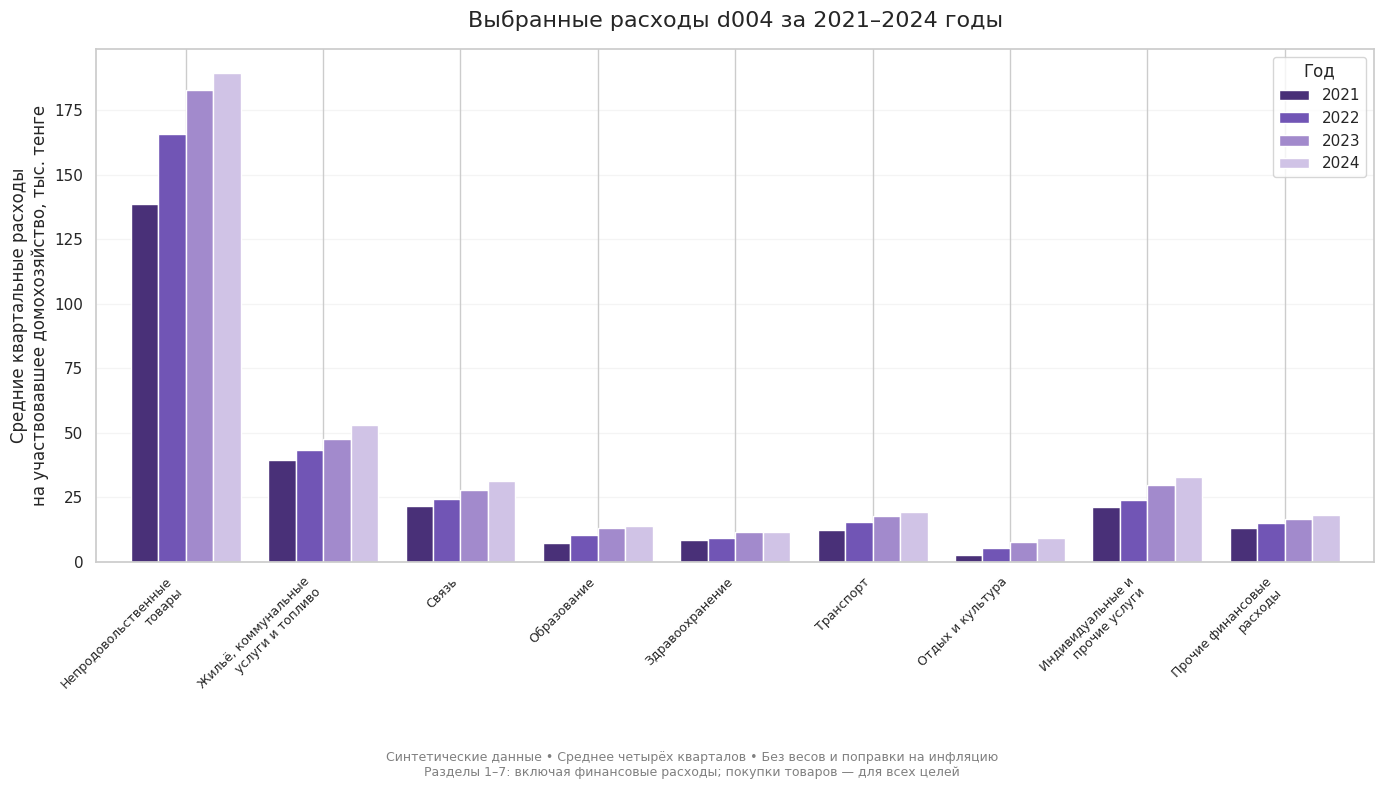

График сохранён: /content/drive/MyDrive/Datathon/results_d004/05_expenses_2021_2024.png


In [38]:
# Итоговый график и PNG. Расходы по категориям за 2021–2024, сохранение в PNG (300 dpi).
plot_data = final_year_means.T / 1000

fig_export, ax_export = plt.subplots(figsize=(14, 8))

plot_data.plot.bar(
    ax=ax_export,
    color=["#493078", "#7155B5", "#A28ACC", "#D0C3E6"],
    edgecolor="white",
    width=0.8
)

ax_export.set_title(
    "Выбранные расходы d004 за 2021–2024 годы",
    fontsize=16, pad=16
)
ax_export.set_ylabel(
    "Средние квартальные расходы\nна участвовавшее домохозяйство, тыс. тенге"
)
ax_export.set_xlabel("")
ax_export.set_xticklabels(
    [textwrap.fill(name, 19) for name in plot_data.index],
    rotation=45, ha="right", fontsize=9
)
ax_export.legend(title="Год")
ax_export.set_axisbelow(True)
ax_export.grid(axis="y", alpha=0.2)

fig_export.text(
    0.5, 0.02,
    "Синтетические данные • Среднее четырёх кварталов • Без весов и поправки на инфляцию\n"
    "Разделы 1–7: включая финансовые расходы; покупки товаров — для всех целей",
    ha="center", fontsize=9, color="gray"
)

fig_export.tight_layout(rect=[0, 0.09, 1, 1])

chart_path = output_folder / "05_expenses_2021_2024.png"
fig_export.savefig(chart_path, dpi=300, bbox_inches="tight")

plt.show()
print("График сохранён:", chart_path)

In [39]:
# Описательная статистика расходов. Среднее, медиана, мода, квартили и разброс по домохозяйствам-кварталам. Домохозяйства без записей расходов считаются как 0.
# Складываем выбранные расходы каждого домохозяйства за квартал
household_totals = (
    expenses_valid
    .groupby(["year", "quarter", "NOMER"])["STOIMK"]
    .sum()
    .rename("Расходы")
    .reset_index()
)

# Включаем всех участников, даже если записей расходов нет
household_stats_data = (
    participation.loc[
        participation["REZ"] == 1,
        ["year", "quarter", "NOMER"]
    ]
    .drop_duplicates()
    .merge(
        household_totals,
        on=["year", "quarter", "NOMER"],
        how="left",
        validate="one_to_one"
    )
)

missing_count = household_stats_data["Расходы"].isna().sum()
print("Домохозяйств-кварталов без записей расходов:", missing_count)

# Нет записей — ноль зарегистрированных расходов
household_stats_data["Расходы"] = (
    household_stats_data["Расходы"].fillna(0)
)

def mode_values(series):
    modes = series.mode()
    if len(modes) == series.nunique():
        return "Нет выделяющейся моды"
    return "; ".join(f"{value:,.0f}" for value in modes)

descriptive_stats = (
    household_stats_data.groupby("year")["Расходы"]
    .agg(
        Наблюдений="size",
        Среднее="mean",
        Медиана="median",
        Мода=mode_values,
        Минимум="min",
        Максимум="max",
        Стандартное_отклонение="std",
        Нижний_квартиль=lambda s: s.quantile(0.25),
        Верхний_квартиль=lambda s: s.quantile(0.75)
    )
)

print("\nОписательная статистика квартальных расходов, тенге")
print("Разделы 1–7 d004 • Синтетические данные • Без весов")
show(descriptive_stats.round(1).T)

descriptive_stats.to_csv(
    output_folder / "06_descriptive_statistics.csv",
    sep=";", decimal=",", encoding="utf-8-sig"
)

print("\nТаблица сохранена: 06_descriptive_statistics.csv")

Домохозяйств-кварталов без записей расходов: 5

Описательная статистика квартальных расходов, тенге
Разделы 1–7 d004 • Синтетические данные • Без весов


year,2021,2022,2023,2024
Наблюдений,47184,47331,47339,47255
Среднее,264 721.7,312 947.4,354 336.2,378 340.7
Медиана,222 605.0,265 255.0,296 470.0,321 124.0
Мода,"104,600; 114,580; 129,000; 130,470; 130,550; 139,420; 140,920; 158,980; 163,065; 163,310; 175,610; 175,645; 185,950; 188,665; 205,670; 207,700; 209,940; 214,190; 262,380; 284,050; 333,560","156,980","212,480; 213,685","186,750; 197,570; 214,140; 226,900; 229,250; 241,400; 333,610"
Минимум,17 163.0,0.0,0.0,4 380.0
Максимум,10 429 203.0,15 507 402.0,23 501 476.0,14 617 002.0
Стандартное_отклонение,234 396.9,287 181.4,371 212.7,335 445.9
Нижний_квартиль,151 720.0,180 192.0,203 202.5,223 797.5
Верхний_квартиль,323 568.5,384 735.0,430 980.0,460 741.0



Таблица сохранена: 06_descriptive_statistics.csv


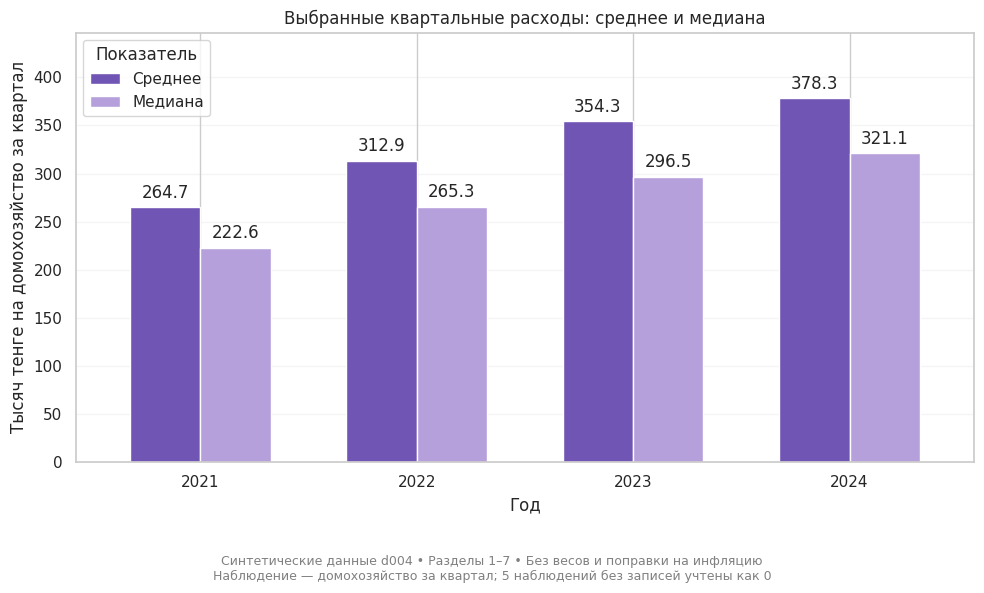

Сохранено: 07_mean_median.png


In [40]:
# График: среднее и медиана. Сравнение среднего и медианы по годам, сохранение в PNG.
data_chart = descriptive_stats[["Среднее", "Медиана"]] / 1000

fig_stats, ax_stats = plt.subplots(figsize=(10, 6))

data_chart.plot.bar(
    ax=ax_stats,
    color=["#7155B5", "#B5A0DB"],
    rot=0,
    width=0.65
)

for bars in ax_stats.containers:
    ax_stats.bar_label(bars, fmt="%.1f", padding=4)

ax_stats.set_title("Выбранные квартальные расходы: среднее и медиана")
ax_stats.set_xlabel("Год")
ax_stats.set_ylabel("Тысяч тенге на домохозяйство за квартал")
ax_stats.set_ylim(0, data_chart.max().max() * 1.18)
ax_stats.set_axisbelow(True)
ax_stats.grid(axis="y", alpha=0.2)
ax_stats.legend(title="Показатель")

fig_stats.text(
    0.5, 0.02,
    "Синтетические данные d004 • Разделы 1–7 • Без весов и поправки на инфляцию\n"
    "Наблюдение — домохозяйство за квартал; 5 наблюдений без записей учтены как 0",
    ha="center", fontsize=9, color="gray"
)

fig_stats.tight_layout(rect=[0, 0.10, 1, 1])
fig_stats.savefig(
    output_folder / "07_mean_median.png",
    dpi=300, bbox_inches="tight"
)

plt.show()
print("Сохранено: 07_mean_median.png")

## ВЫВОДЫ ПО АНАЛИЗУ D004

---

### 1. Расходы домохозяйств растут быстрее, чем доходы нижних групп успевают их покрывать
* **Инсайт:** Средние квартальные расходы домохозяйства (разделы 1–7, без продовольствия) выросли с 264,7 тыс. тг в 2021 г. до 378,3 тыс. тг в 2024 г. (+43 %); медиана — с 222,6 до 321,1 тыс. тг (+44 %).
* **Детализация данных:** Среднее стабильно выше медианы (в 2024 г. — 378 против 321 тыс. тг при стандартном отклонении 335 тыс. тг): распределение расходов сильно скошено вправо, небольшая группа семей с очень высокими тратами «тянет» среднее вверх. Анализ построен на 16 кварталах и 6,85 млн записей расходов; пропусков, отрицательных и нулевых сумм в данных нет.
* **Политический вывод (Policy):** Для оценки реальной нагрузки на бюджет семьи опираться нужно на медиану и децильный разрез, а не на среднее — иначе масштаб проблемы нижних групп занижается.

---

### 2. Структура расходов: доминирует потребление товаров, быстрее всего растут услуги
* **Инсайт:** Крупнейшая статья — непродовольственные товары (189,3 тыс. тг за квартал в 2024 г.), затем жильё и коммунальные услуги (53,2), прочие услуги (32,7) и связь (31,3).
* **Детализация данных:** Наибольший рост за 2021–2024 гг. показали отдых и культура (+270 %, но с очень низкой базы: 2,5 → 9,3 тыс. тг), образование (+92 %) и транспорт (+56 %). Рост отдыха и культуры не объясняется появлением новых кодов расходов: по кодам, присутствующим во все четыре года, он составляет +265 %. Самые медленные темпы у жилья и коммунальных услуг (+35 %) и непродовольственных товаров (+36 %). Свыше 98 % закупок непродовольственных товаров — личное потребление.
* **Политический вывод (Policy):** Платные образовательные и транспортные услуги дорожают для семей быстрее базовых статей. Это зона для точечной поддержки (образовательные гранты, транспортные льготы) в первую очередь для малообеспеченных домохозяйств.

---

### 3. Ограничения данных
* **Инсайт:** В D004 нет продовольственных расходов, а суммы приведены без весов и без поправки на инфляцию.
* **Политический вывод (Policy):** Рост расходов частично отражает цены, а не объём потребления, а доля семей с дефицитом бюджета в проверке H1 является оценкой снизу — реальная нагрузка выше.

## Анализ D006 — жилищные условия и инфраструктура
Модуль `d006 / rio.csv`: тип и площадь жилья, коммунальные удобства, состав домохозяйства, география выборки.

In [41]:
%load_ext rpy2.ipython

The rpy2.ipython extension is already loaded. To reload it, use:
  %reload_ext rpy2.ipython


In [42]:
%%R
options(bitmapType = "cairo")
if (!requireNamespace("tidyverse", quietly = TRUE)) {
  install.packages("tidyverse", repos = "https://cloud.r-project.org")
}
suppressPackageStartupMessages(library(tidyverse))
DATA_DIR <- "/content/drive/MyDrive/Datathon/synthetic_microdata_2021-2024_20260921"

In [43]:
%%R
files <- list.files(DATA_DIR, pattern = "^rio\\.csv$", recursive = TRUE,
                    full.names = TRUE, ignore.case = TRUE)
files <- files[grepl("d006", files, ignore.case = TRUE)]
cat("Найдено файлов rio.csv:", length(files), "\n")
print(files)
stopifnot(length(files) > 0)

read_one <- function(f) {
  d <- read_csv(f, col_types = cols(.default = col_character()), show_col_types = FALSE)
  if (!("Year" %in% names(d))) {
    yr <- as.integer(str_match(f, "/(20[0-9]{2})/")[, 2])
    if (is.na(yr)) stop("Не удалось определить год по пути: ", f)
    d$Year <- yr
  }
  d
}

rio_all <- map_dfr(files, read_one)
rio_all <- suppressMessages(type_convert(rio_all))
# Год как категория: так он работает и на осях, и в fill/color
rio_all$Year <- factor(rio_all$Year)
cat("rio_all:", nrow(rio_all), "строк,", ncol(rio_all), "столбцов\n")
print(count(rio_all, Year))

Найдено файлов rio.csv: 1 
[1] "/content/drive/MyDrive/Datathon/synthetic_microdata_2021-2024_20260921/d006/2021/rio.csv"
rio_all: 11636 строк, 248 столбцов
# A tibble: 1 × 2
  Year      n
  <fct> <int>
1 2021  11636


`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


In addition: Warning message:
Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
This warning is displayed once per session.
Call `lifecycle::last_lifecycle_warnings()` to see where this warning was
generated. 


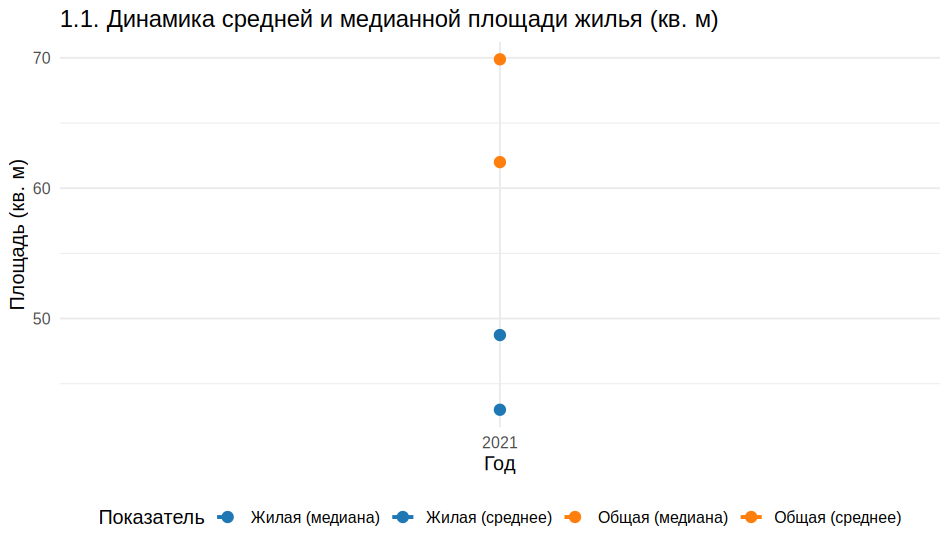

In [44]:
%%R -w 950 -h 550 -u px -r 110
# График 1.1. Динамика средней и медианной площади жилья (2021–2024 гг.). Средняя и медианная общая и жилая площадь по годам.
area_stats <- rio_all %>%
  filter(!is.na(OB_PL) & !is.na(J_PL) & OB_PL > 0 & J_PL > 0) %>%
  group_by(Year) %>%
  summarise(
    `Общая (среднее)`   = mean(OB_PL, na.rm = TRUE),
    `Общая (медиана)`   = median(OB_PL, na.rm = TRUE),
    `Жилая (среднее)`   = mean(J_PL, na.rm = TRUE),
    `Жилая (медиана)`   = median(J_PL, na.rm = TRUE)
  ) %>%
  pivot_longer(-Year, names_to = "Показатель", values_to = "Площадь")
p <- ggplot(area_stats, aes(x = Year, y = Площадь, color = Показатель, group = Показатель, linetype = Показатель)) +
  geom_line(size = 1.2) +
  geom_point(size = 3) +
  scale_linetype_manual(values = c("dashed", "solid", "dashed", "solid")) +
  scale_color_manual(values = c("#1f77b4", "#1f77b4", "#ff7f0e", "#ff7f0e")) +
  labs(
    title = "1.1. Динамика средней и медианной площади жилья (кв. м)",
    x = "Год",
    y = "Площадь (кв. м)"
  ) +
  theme_minimal(base_size = 13) +
  theme(legend.position = "bottom")

print(p)

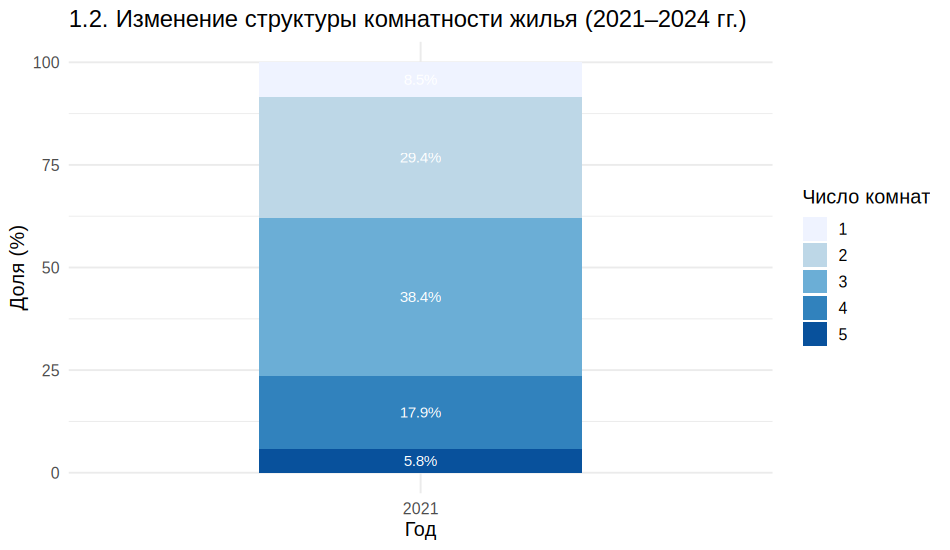

In [45]:
%%R -w 950 -h 550 -u px -r 110
# График 1.2. Изменение структуры комнатности жилья в % (2021–2024 гг.). Доля жилья с 1–5 комнатами по годам.
rooms_stat <- rio_all %>%
  filter(KOL_K %in% 1:5) %>%
  count(Year, KOL_K) %>%
  group_by(Year) %>%
  mutate(Percent = n / sum(n) * 100)
p <- ggplot(rooms_stat, aes(x = Year, y = Percent, fill = factor(KOL_K))) +
  geom_bar(stat = "identity", position = "stack", width = 0.55) +
  geom_text(aes(label = paste0(round(Percent, 1), "%")),
            position = position_stack(vjust = 0.5), size = 3.5, color = "white") +
  scale_fill_brewer(palette = "Blues", name = "Число комнат") +
  labs(
    title = "1.2. Изменение структуры комнатности жилья (2021–2024 гг.)",
    x = "Год",
    y = "Доля (%)"
  ) +
  theme_minimal(base_size = 13)

print(p)

`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


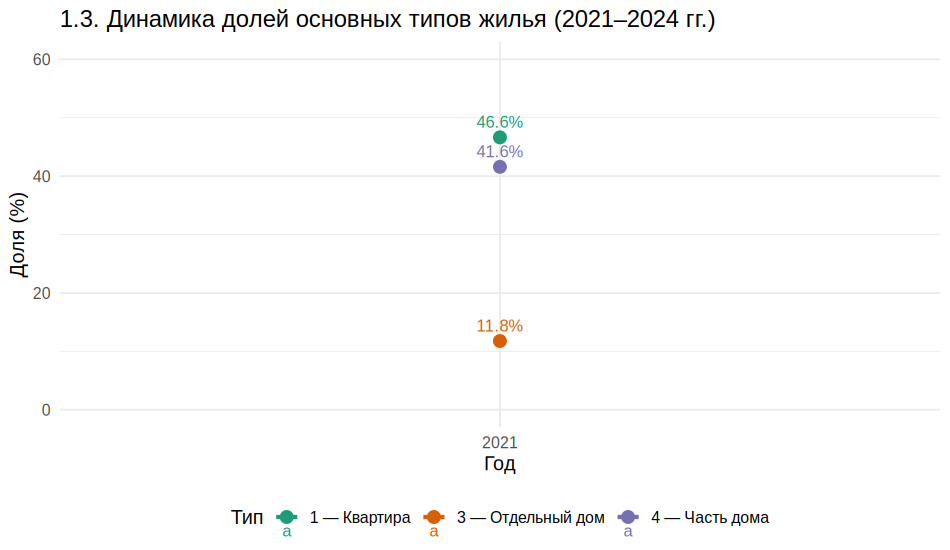

In [46]:
%%R -w 950 -h 550 -u px -r 110
# График 1.3. Динамика долей основных типов жилья (2021–2024 гг.). Доли квартир, отдельных домов и частей дома.
tip_stat <- rio_all %>%
  filter(TIP_J %in% c(1, 3, 4)) %>%
  mutate(Тип = case_when(
    TIP_J == 1 ~ "1 — Квартира",
    TIP_J == 3 ~ "3 — Отдельный дом",
    TIP_J == 4 ~ "4 — Часть дома"
  )) %>%
  count(Year, Тип) %>%
  group_by(Year) %>%
  mutate(Percent = n / sum(n) * 100)
p <- ggplot(tip_stat, aes(x = Year, y = Percent, color = Тип, group = Тип)) +
  geom_line(size = 1.3) +
  geom_point(size = 3.5) +
  geom_text(aes(label = paste0(round(Percent, 1), "%")), vjust = -0.8, size = 3.8) +
  scale_color_brewer(palette = "Dark2") +
  labs(
    title = "1.3. Динамика долей основных типов жилья (2021–2024 гг.)",
    x = "Год",
    y = "Доля (%)"
  ) +
  coord_cartesian(ylim = c(0, 60)) +
  theme_minimal(base_size = 13) +
  theme(legend.position = "bottom")

print(p)

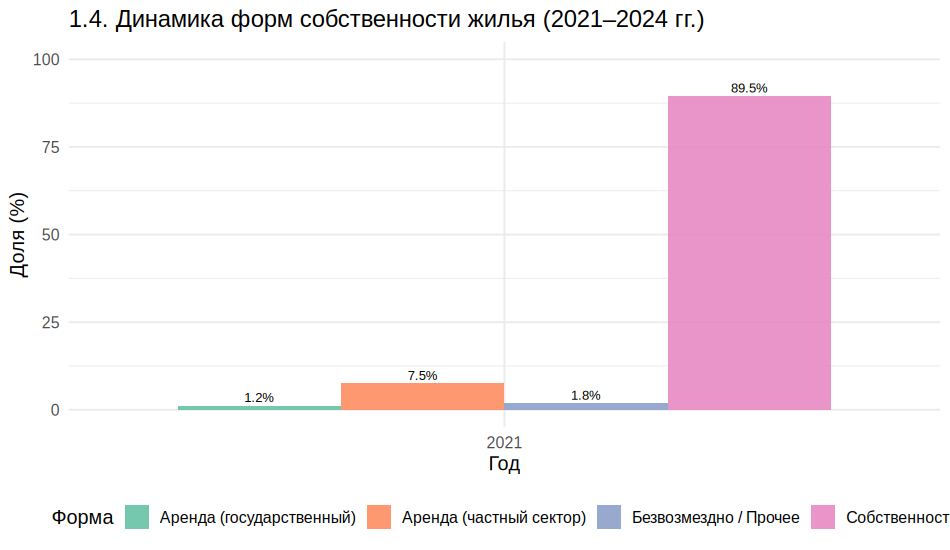

In [47]:
%%R -w 950 -h 550 -u px -r 110
# График 1.4. Динамика форм собственности жилья (2021–2024 гг.). Доли собственности, аренды и безвозмездного пользования.
vlad_stat <- rio_all %>%
  filter(VLAD1 %in% 1:4) %>%
  mutate(Форма = case_when(
    VLAD1 == 1 ~ "Собственность",
    VLAD1 == 2 ~ "Аренда (частный сектор)",
    VLAD1 == 3 ~ "Аренда (государственный)",
    VLAD1 == 4 ~ "Безвозмездно / Прочее"
  )) %>%
  count(Year, Форма) %>%
  group_by(Year) %>%
  mutate(Percent = n / sum(n) * 100)
p <- ggplot(vlad_stat, aes(x = Year, y = Percent, fill = Форма)) +
  geom_bar(stat = "identity", position = "dodge", alpha = 0.9) +
  geom_text(aes(label = paste0(round(Percent, 1), "%")),
            position = position_dodge(width = 0.9), vjust = -0.4, size = 3) +
  scale_fill_brewer(palette = "Set2") +
  labs(
    title = "1.4. Динамика форм собственности жилья (2021–2024 гг.)",
    x = "Год",
    y = "Доля (%)"
  ) +
  coord_cartesian(ylim = c(0, 100)) +
  theme_minimal(base_size = 13) +
  theme(legend.position = "bottom")

print(p)

`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


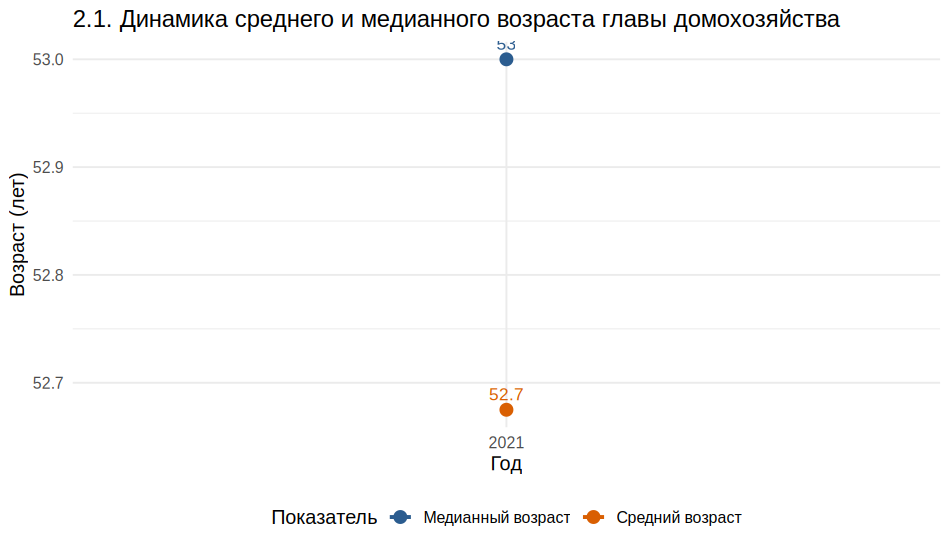

In [48]:
%%R -w 950 -h 550 -u px -r 110
# График 2.1. Динамика среднего возраста главы домохозяйства (2021–2024 гг.). Средний и медианный возраст первого члена домохозяйства (`VOZ1`).
age_trend <- rio_all %>%
  mutate(VOZ1 = as.numeric(VOZ1)) %>%
  filter(!is.na(VOZ1) & VOZ1 > 0 & VOZ1 < 100) %>%
  group_by(Year) %>%
  summarise(
    `Средний возраст`  = mean(VOZ1, na.rm = TRUE),
    `Медианный возраст` = median(VOZ1, na.rm = TRUE)
  ) %>%
  pivot_longer(-Year, names_to = "Показатель", values_to = "Возраст")
p <- ggplot(age_trend, aes(x = Year, y = Возраст, color = Показатель, group = Показатель)) +
  geom_line(size = 1.2) +
  geom_point(size = 3.5) +
  geom_text(aes(label = round(Возраст, 1)), vjust = -0.8, size = 4, show.legend = FALSE) +
  scale_color_manual(values = c("#2b5c8f", "#d95f02")) +
  labs(
    title = "2.1. Динамика среднего и медианного возраста главы домохозяйства",
    x = "Год",
    y = "Возраст (лет)"
  ) +
  theme_minimal(base_size = 13) +
  theme(legend.position = "bottom")

print(p)

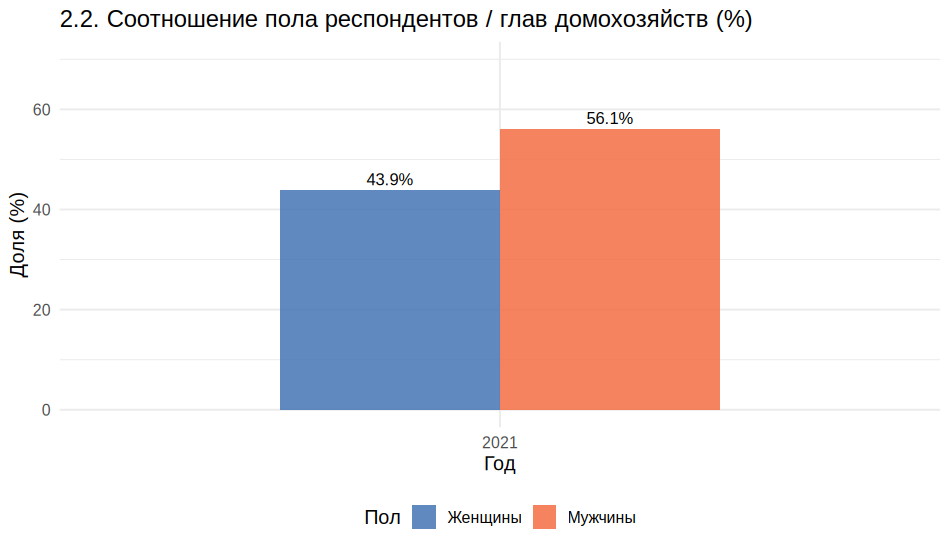

In [49]:
%%R -w 950 -h 550 -u px -r 110
# График 2.2. Распределение по полу главы домохозяйства в % (2021–2024 гг.). Доли мужчин и женщин среди первых членов домохозяйств (`POL1`).
gender_stat <- rio_all %>%
  mutate(POL1 = as.numeric(POL1)) %>%
  filter(POL1 %in% c(1, 2)) %>%
  mutate(Пол = ifelse(POL1 == 1, "Мужчины", "Женщины")) %>%
  count(Year, Пол) %>%
  group_by(Year) %>%
  mutate(Percent = n / sum(n) * 100)
p <- ggplot(gender_stat, aes(x = Year, y = Percent, fill = Пол)) +
  geom_bar(stat = "identity", position = "dodge", alpha = 0.85, width = 0.6) +
  geom_text(aes(label = paste0(round(Percent, 1), "%")),
            position = position_dodge(width = 0.6), vjust = -0.4, size = 3.8) +
  scale_fill_manual(values = c("#4575b4", "#f46d43")) +
  labs(
    title = "2.2. Соотношение пола респондентов / глав домохозяйств (%)",
    x = "Год",
    y = "Доля (%)"
  ) +
  coord_cartesian(ylim = c(0, 70)) +
  theme_minimal(base_size = 13) +
  theme(legend.position = "bottom")

print(p)

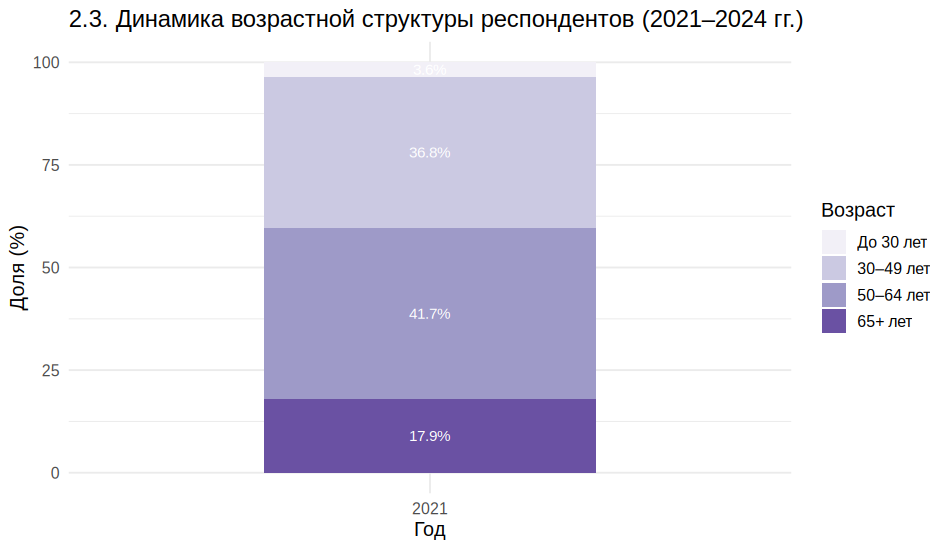

In [50]:
%%R -w 950 -h 550 -u px -r 110
# График 2.3. Возрастная структура глав домохозяйств по категориям (%). Распределение первых членов домохозяйств по возрастным группам.
age_groups <- rio_all %>%
  mutate(VOZ1 = as.numeric(VOZ1)) %>%
  filter(!is.na(VOZ1) & VOZ1 > 0) %>%
  mutate(Возрастная_группа = case_when(
    VOZ1 < 30 ~ "До 30 лет",
    VOZ1 >= 30 & VOZ1 <= 49 ~ "30–49 лет",
    VOZ1 >= 50 & VOZ1 <= 64 ~ "50–64 лет",
    VOZ1 >= 65 ~ "65+ лет"
  )) %>%
  mutate(Возрастная_группа = factor(Возрастная_группа, levels = c("До 30 лет", "30–49 лет", "50–64 лет", "65+ лет"))) %>%
  count(Year, Возрастная_группа) %>%
  group_by(Year) %>%
  mutate(Percent = n / sum(n) * 100)
p <- ggplot(age_groups, aes(x = Year, y = Percent, fill = Возрастная_группа)) +
  geom_bar(stat = "identity", position = "stack", width = 0.55) +
  geom_text(aes(label = paste0(round(Percent, 1), "%")),
            position = position_stack(vjust = 0.5), size = 3.5, color = "white") +
  scale_fill_brewer(palette = "Purples", name = "Возраст") +
  labs(
    title = "2.3. Динамика возрастной структуры респондентов (2021–2024 гг.)",
    x = "Год",
    y = "Доля (%)"
  ) +
  theme_minimal(base_size = 13)

print(p)

`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


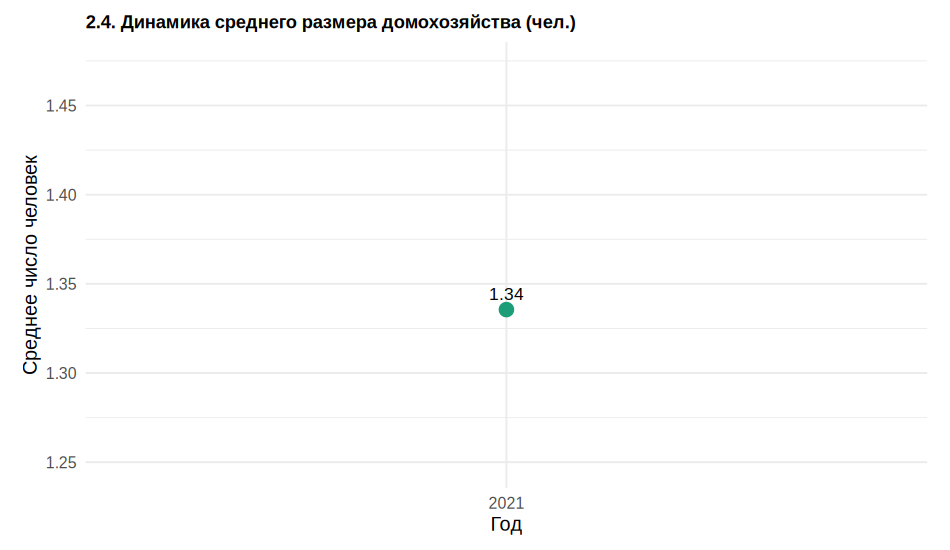

In [51]:
%%R -w 950 -h 550 -u px -r 110
# График 2.4. Среднее число членов домохозяйства по годам. Средний размер домохозяйства по годам.
hh_size_stat <- rio_all %>%
  mutate(across(starts_with("VOZ"), as.character)) %>%
  rowwise() %>%
  mutate(
    hh_size = sum(!is.na(c_across(starts_with("VOZ"))) &
                    c_across(starts_with("VOZ")) != "" &
                    c_across(starts_with("VOZ")) != "0")
  ) %>%
  ungroup() %>%
  filter(hh_size > 0) %>%
  group_by(Year) %>%
  summarise(
    `Средний размер домохозяйства` = mean(hh_size, na.rm = TRUE)
  )
p <- ggplot(hh_size_stat, aes(x = Year, y = `Средний размер домохозяйства`, group = 1)) +
  geom_line(color = "#1b9e77", size = 1.3) +
  geom_point(color = "#1b9e77", size = 4) +
  geom_text(aes(label = round(`Средний размер домохозяйства`, 2)), vjust = -0.8, size = 4) +
  scale_y_continuous(expand = expansion(mult = c(0.1, 0.15))) +
  labs(
    title = "2.4. Динамика среднего размера домохозяйства (чел.)",
    x = "Год",
    y = "Среднее число человек"
  ) +
  theme_minimal(base_size = 13) +
  theme(
    plot.title = element_text(size = 12, face = "bold"),
    plot.margin = margin(10, 15, 10, 15)
  )

print(p)

`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


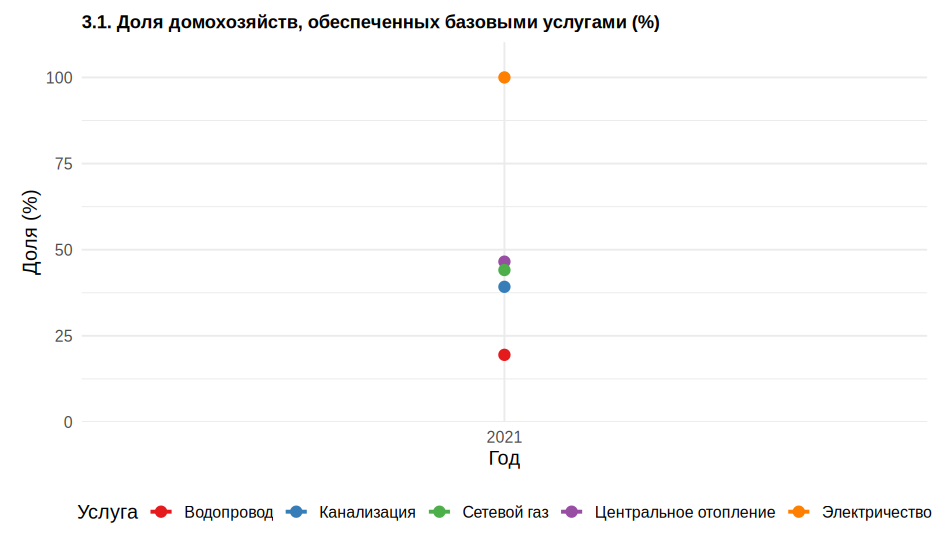

In [52]:
%%R -w 950 -h 550 -u px -r 110
# График 3.1. Охват жилья ключевыми коммунальными услугами (2021–2024 гг.). Доля жилья с водопроводом, канализацией, газом и другими сетями.
services_stat <- rio_all %>%
  mutate(across(c(U1, U2, U3, U4, U5), as.numeric)) %>%
  group_by(Year) %>%
  summarise(
    `Электричество`         = mean(U1 == 1, na.rm = TRUE) * 100,
    `Водопровод`            = mean(U2 == 1, na.rm = TRUE) * 100,
    `Центральное отопление` = mean(U3 == 1, na.rm = TRUE) * 100,
    `Канализация`           = mean(U4 == 1, na.rm = TRUE) * 100,
    `Сетевой газ`           = mean(U5 == 1, na.rm = TRUE) * 100
  ) %>%
  pivot_longer(-Year, names_to = "Услуга", values_to = "Процент")
p <- ggplot(services_stat, aes(x = Year, y = Процент, color = Услуга, group = Услуга)) +
  geom_line(size = 1.2) +
  geom_point(size = 3) +
  scale_color_brewer(palette = "Set1") +
  scale_y_continuous(limits = c(0, 105), expand = expansion(mult = c(0, 0.05))) +
  labs(
    title = "3.1. Доля домохозяйств, обеспеченных базовыми услугами (%)",
    x = "Год",
    y = "Доля (%)"
  ) +
  theme_minimal(base_size = 13) +
  theme(
    legend.position = "bottom",
    plot.title = element_text(size = 12, face = "bold"),
    plot.margin = margin(10, 15, 10, 15)
  )

print(p)

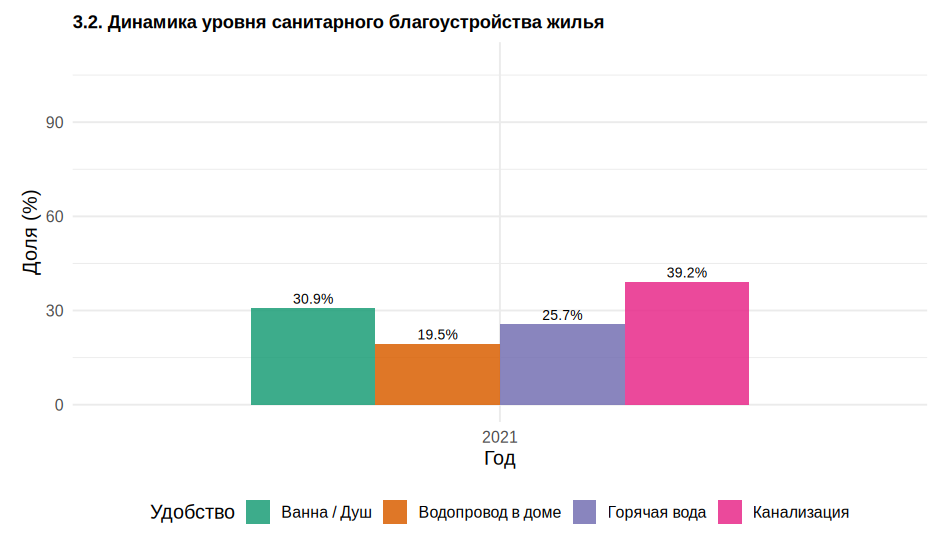

In [53]:
%%R -w 950 -h 550 -u px -r 110
# График 3.2. Доступность санитарно-гигиенических удобств (%). Доля жилья с санитарно-гигиеническими удобствами.
sanitation_stat <- rio_all %>%
  mutate(across(c(U2, U4, U6, U8), as.numeric)) %>%
  group_by(Year) %>%
  summarise(
    `Водопровод в доме` = mean(U2 == 1, na.rm = TRUE) * 100,
    `Канализация`       = mean(U4 == 1, na.rm = TRUE) * 100,
    `Ванна / Душ`       = mean(U6 == 1, na.rm = TRUE) * 100,
    `Горячая вода`      = mean(U8 == 1, na.rm = TRUE) * 100
  ) %>%
  pivot_longer(-Year, names_to = "Удобство", values_to = "Процент")
p <- ggplot(sanitation_stat, aes(x = Year, y = Процент, fill = Удобство)) +
  geom_bar(stat = "identity", position = "dodge", alpha = 0.85, width = 0.7) +
  geom_text(aes(label = paste0(round(Процент, 1), "%")),
            position = position_dodge(width = 0.7), vjust = -0.4, size = 3.2) +
  scale_fill_brewer(palette = "Dark2") +
  scale_y_continuous(limits = c(0, 110)) +
  labs(
    title = "3.2. Динамика уровня санитарного благоустройства жилья",
    x = "Год",
    y = "Доля (%)"
  ) +
  theme_minimal(base_size = 13) +
  theme(
    legend.position = "bottom",
    plot.title = element_text(size = 12, face = "bold"),
    plot.margin = margin(10, 15, 10, 15)
  )

print(p)

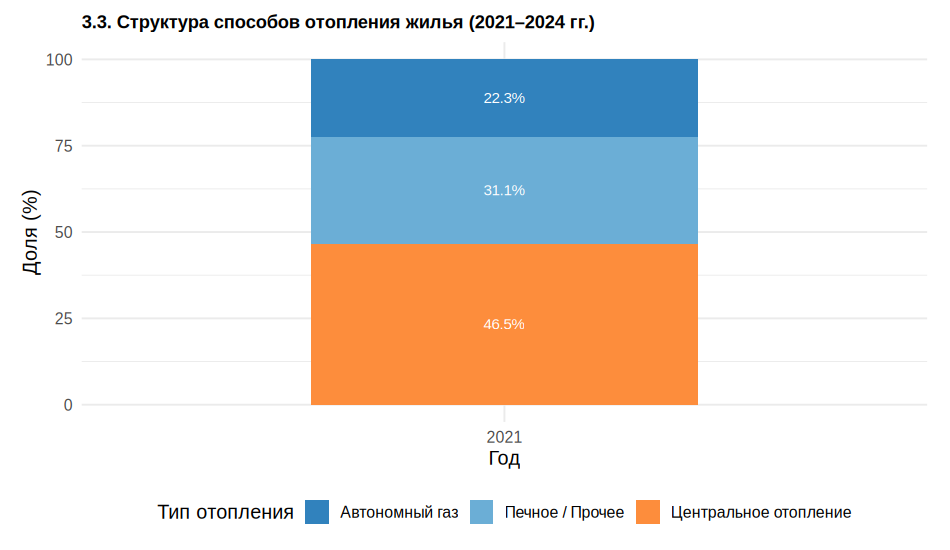

In [54]:
%%R -w 950 -h 550 -u px -r 110
# График 3.3. Структура источников отопления жилья (%). Структура источников отопления.
heating_stat <- rio_all %>%
  mutate(U3 = as.numeric(U3), U5 = as.numeric(U5)) %>%
  mutate(Тип_отопления = case_when(
    U3 == 1 ~ "Центральное отопление",
    U3 == 2 & U5 == 1 ~ "Автономный газ",
    TRUE ~ "Печное / Прочее"
  )) %>%
  count(Year, Тип_отопления) %>%
  group_by(Year) %>%
  mutate(Percent = n / sum(n) * 100)
p <- ggplot(heating_stat, aes(x = Year, y = Percent, fill = Тип_отопления)) +
  geom_bar(stat = "identity", position = "stack", width = 0.55) +
  geom_text(aes(label = paste0(round(Percent, 1), "%")),
            position = position_stack(vjust = 0.5), size = 3.5, color = "white") +
  scale_fill_manual(values = c("#3182bd", "#6baed6", "#fd8d3c"), name = "Тип отопления") +
  labs(
    title = "3.3. Структура способов отопления жилья (2021–2024 гг.)",
    x = "Год",
    y = "Доля (%)"
  ) +
  theme_minimal(base_size = 13) +
  theme(
    legend.position = "bottom",
    plot.title = element_text(size = 12, face = "bold"),
    plot.margin = margin(10, 15, 10, 15)
  )

print(p)

`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


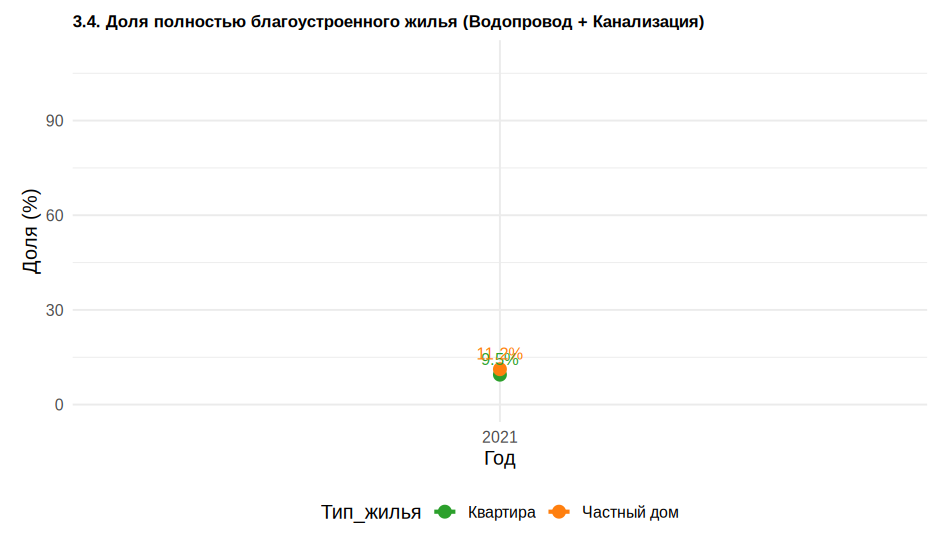

In [55]:
%%R -w 950 -h 550 -u px -r 110
# График 3.4. Сравнение благоустройства по типам жилья (Квартиры vs Дома). Доля благоустроенного жилья: квартиры и дома.
type_blag_stat <- rio_all %>%
  mutate(
    TIP_J = as.numeric(TIP_J),
    U2 = as.numeric(U2),
    U4 = as.numeric(U4)
  ) %>%
  filter(TIP_J %in% c(1, 3)) %>%
  mutate(
    Тип_жилья = ifelse(TIP_J == 1, "Квартира", "Частный дом")
  ) %>%
  group_by(Year, Тип_жилья) %>%
  summarise(
    Благоустроено = mean(U2 == 1 & U4 == 1, na.rm = TRUE) * 100,
    .groups = "drop"
  )
p <- ggplot(type_blag_stat, aes(x = Year, y = Благоустроено, color = Тип_жилья, group = Тип_жилья)) +
  geom_line(size = 1.3) +
  geom_point(size = 3.5) +
  geom_text(aes(label = paste0(round(Благоустроено, 1), "%")), vjust = -0.8, size = 3.8, show.legend = FALSE) +
  scale_color_manual(values = c("#2ca02c", "#ff7f0e")) +
  scale_y_continuous(limits = c(0, 110)) +
  labs(
    title = "3.4. Доля полностью благоустроенного жилья (Водопровод + Канализация)",
    x = "Год",
    y = "Доля (%)"
  ) +
  theme_minimal(base_size = 13) +
  theme(
    legend.position = "bottom",
    plot.title = element_text(size = 11, face = "bold"),
    plot.margin = margin(10, 15, 10, 15)
  )

print(p)

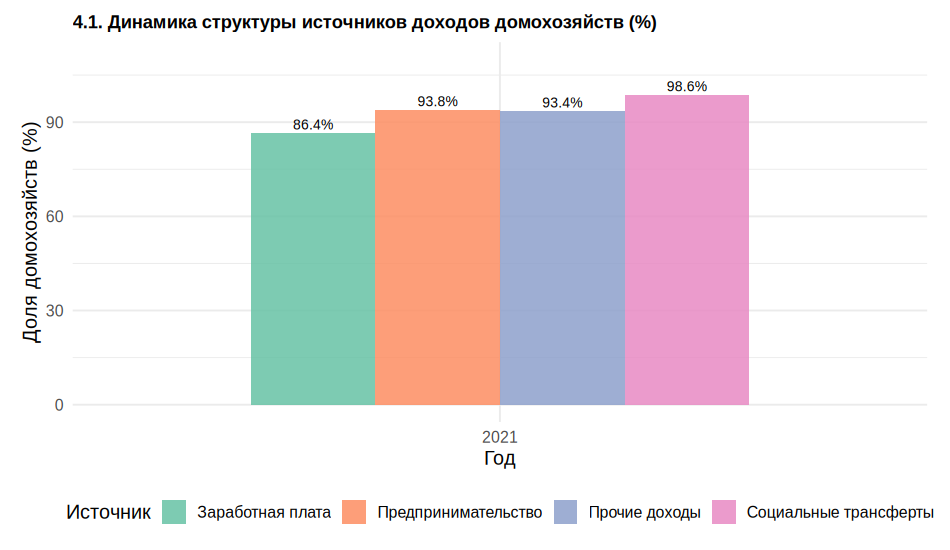

In [56]:
%%R -w 950 -h 550 -u px -r 110
# График 4.1. Структура источников доходов домохозяйств (%). Структура источников дохода домохозяйств.
income_stat <- rio_all %>%
  mutate(
    TDP1 = as.numeric(TDP1),
    TDP3 = as.numeric(TDP3),
    TDP5 = as.numeric(TDP5),
    TDP7 = as.numeric(TDP7)
  ) %>%
  group_by(Year) %>%
  summarise(
    `Заработная плата`        = mean(TDP1 == 1, na.rm = TRUE) * 100,
    `Предпринимательство`    = mean(TDP3 == 1, na.rm = TRUE) * 100,
    `Социальные трансферты`  = mean(TDP5 == 1, na.rm = TRUE) * 100,
    `Прочие доходы`          = mean(TDP7 == 1, na.rm = TRUE) * 100
  ) %>%
  pivot_longer(-Year, names_to = "Источник", values_to = "Процент")
p <- ggplot(income_stat, aes(x = Year, y = Процент, fill = Источник)) +
  geom_bar(stat = "identity", position = "dodge", alpha = 0.85, width = 0.7) +
  geom_text(aes(label = paste0(round(Процент, 1), "%")),
            position = position_dodge(width = 0.7), vjust = -0.4, size = 3.2) +
  scale_fill_brewer(palette = "Set2") +
  scale_y_continuous(limits = c(0, 110)) +
  labs(
    title = "4.1. Динамика структуры источников доходов домохозяйств (%)",
    x = "Год",
    y = "Доля домохозяйств (%)"
  ) +
  theme_minimal(base_size = 13) +
  theme(
    legend.position = "bottom",
    plot.title = element_text(size = 12, face = "bold"),
    plot.margin = margin(10, 15, 10, 15)
  )

print(p)

`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


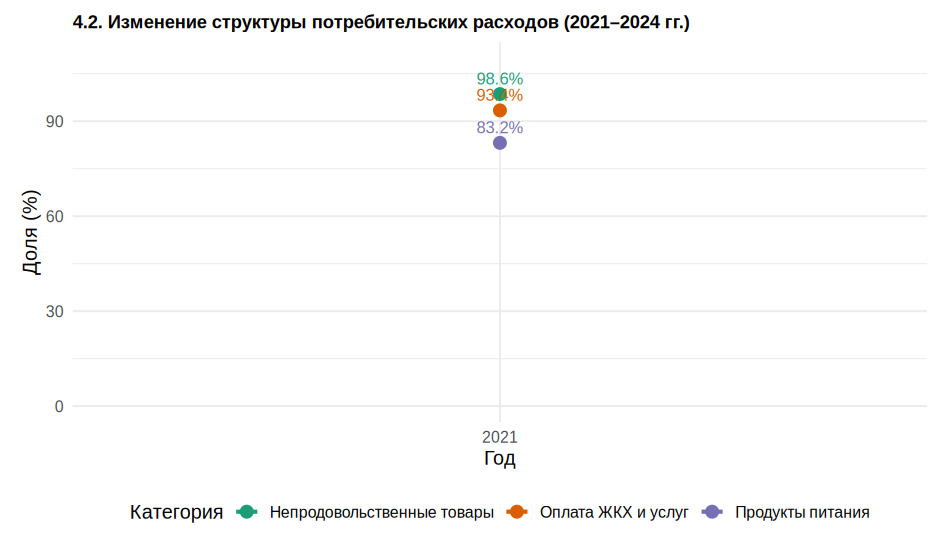

In [57]:
%%R -w 950 -h 550 -u px -r 110
# График 4.2. Соотношение ключевых групп потребительских расходов (%). Соотношение групп потребительских расходов.
expenditure_stat <- rio_all %>%
  mutate(across(starts_with("TDP"), as.numeric)) %>%
  group_by(Year) %>%
  summarise(
    `Продукты питания` = mean(TDP1 == 1 & (is.na(TDP3) | TDP3 != 1), na.rm = TRUE) * 100,
    `Оплата ЖКХ и услуг` = mean(TDP7 == 1, na.rm = TRUE) * 100,
    `Непродовольственные товары` = mean(TDP5 == 1, na.rm = TRUE) * 100
  ) %>%
  pivot_longer(-Year, names_to = "Категория", values_to = "Доля")
p <- ggplot(expenditure_stat, aes(x = Year, y = Доля, color = Категория, group = Категория)) +
  geom_line(size = 1.3) +
  geom_point(size = 3.5) +
  geom_text(aes(label = paste0(round(Доля, 1), "%")), vjust = -0.8, size = 3.8, show.legend = FALSE) +
  scale_color_brewer(palette = "Dark2") +
  scale_y_continuous(limits = c(0, 100), expand = expansion(mult = c(0.05, 0.15))) +
  labs(
    title = "4.2. Изменение структуры потребительских расходов (2021–2024 гг.)",
    x = "Год",
    y = "Доля (%)"
  ) +
  theme_minimal(base_size = 13) +
  theme(
    legend.position = "bottom",
    plot.title = element_text(size = 12, face = "bold"),
    plot.margin = margin(10, 15, 10, 15)
  )

print(p)

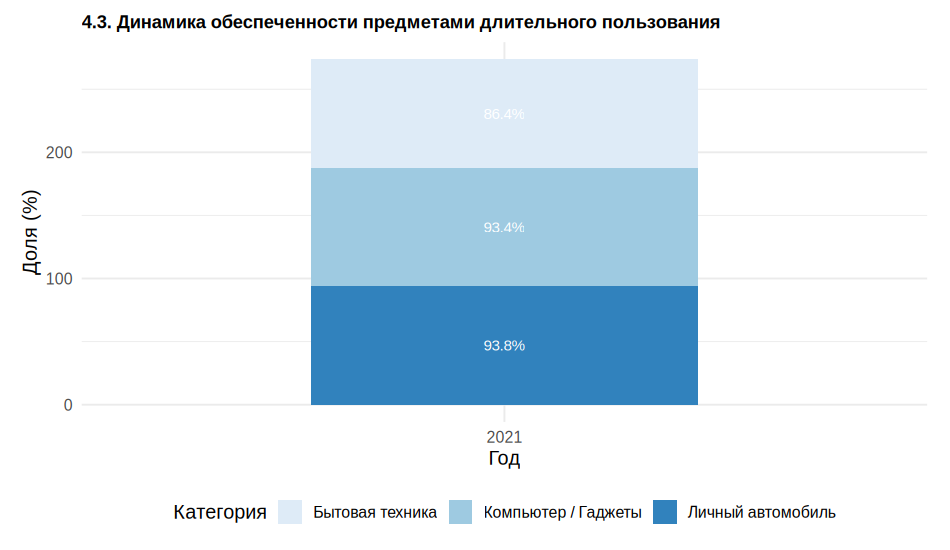

In [58]:
%%R -w 950 -h 550 -u px -r 110
# График 4.3. Оценка обеспеченности предметами длительного пользования. Обеспеченность предметами длительного пользования.
durables_stat <- rio_all %>%
  mutate(across(starts_with("TDP"), as.numeric)) %>%
  group_by(Year) %>%
  summarise(
    `Бытовая техника`   = mean(TDP1 == 1, na.rm = TRUE) * 100,
    `Личный автомобиль` = mean(TDP3 == 1, na.rm = TRUE) * 100,
    `Компьютер / Гаджеты` = mean(TDP7 == 1, na.rm = TRUE) * 100
  ) %>%
  pivot_longer(-Year, names_to = "Категория", values_to = "Процент")
p <- ggplot(durables_stat, aes(x = Year, y = Процент, fill = Категория)) +
  geom_bar(stat = "identity", position = "stack", width = 0.55) +
  geom_text(aes(label = paste0(round(Процент, 1), "%")),
            position = position_stack(vjust = 0.5), size = 3.5, color = "white") +
  scale_fill_brewer(palette = "Blues", name = "Категория") +
  labs(
    title = "4.3. Динамика обеспеченности предметами длительного пользования",
    x = "Год",
    y = "Доля (%)"
  ) +
  theme_minimal(base_size = 13) +
  theme(
    legend.position = "bottom",
    plot.title = element_text(size = 12, face = "bold"),
    plot.margin = margin(10, 15, 10, 15)
  )

print(p)

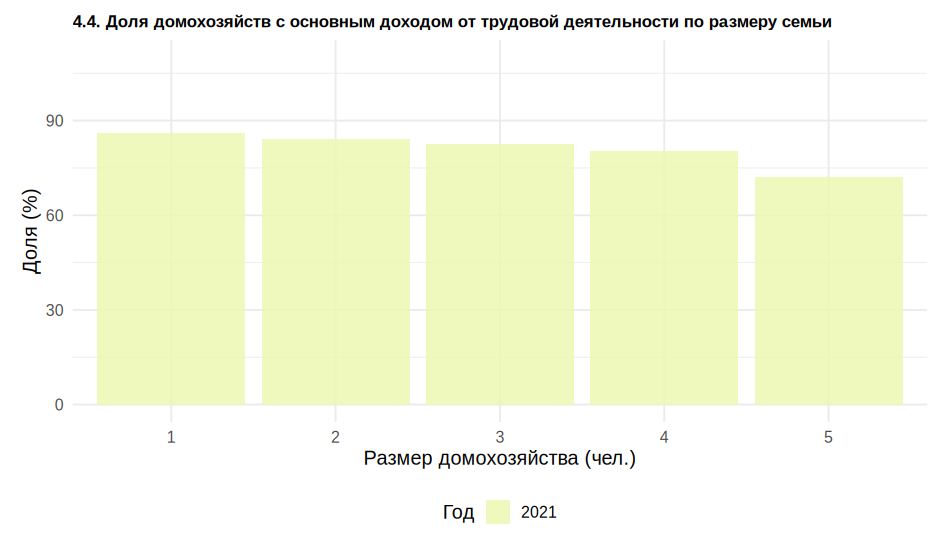

In [59]:
%%R -w 950 -h 550 -u px -r 110
# График 4.4. Зависимость обеспеченности от размера домохозяйства. Доля домохозяйств с доходом по размеру домохозяйства.
size_income_stat <- rio_all %>%
  mutate(across(starts_with("VOZ"), as.character)) %>%
  rowwise() %>%
  mutate(
    hh_size = sum(!is.na(c_across(starts_with("VOZ"))) &
                    c_across(starts_with("VOZ")) != "" &
                    c_across(starts_with("VOZ")) != "0")
  ) %>%
  ungroup() %>%
  filter(hh_size > 0 & hh_size <= 6) %>%
  group_by(Year, hh_size) %>%
  summarise(
    Доля_с_доходом = mean(as.numeric(TDP1) == 1, na.rm = TRUE) * 100,
    .groups = "drop"
  )
p <- ggplot(size_income_stat, aes(x = factor(hh_size), y = Доля_с_доходом, fill = Year)) +
  geom_bar(stat = "identity", position = "dodge", alpha = 0.85) +
  scale_fill_brewer(palette = "YlGnBu", name = "Год") +
  scale_y_continuous(limits = c(0, 110)) +
  labs(
    title = "4.4. Доля домохозяйств с основным доходом от трудовой деятельности по размеру семьи",
    x = "Размер домохозяйства (чел.)",
    y = "Доля (%)"
  ) +
  theme_minimal(base_size = 13) +
  theme(
    legend.position = "bottom",
    plot.title = element_text(size = 11, face = "bold"),
    plot.margin = margin(10, 15, 10, 15)
  )

print(p)

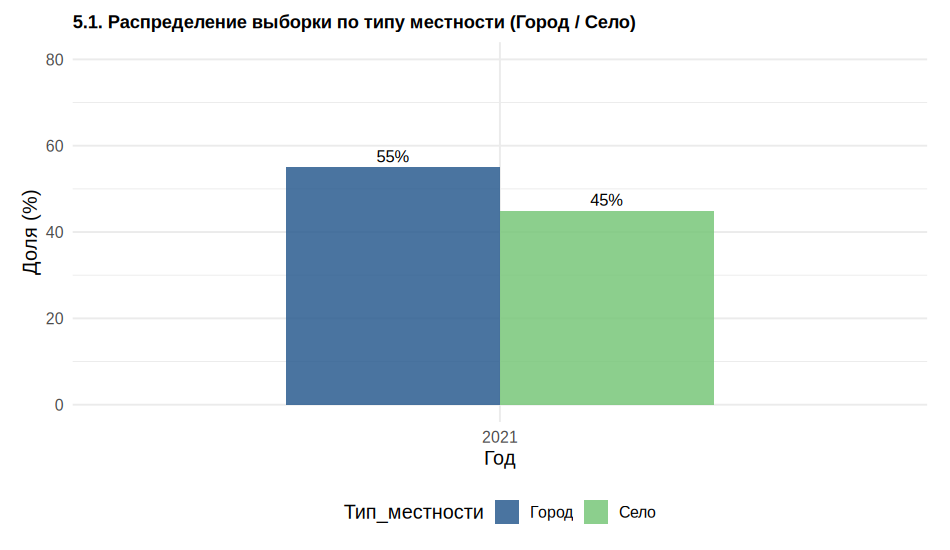

In [60]:
%%R -w 950 -h 550 -u px -r 110
# График 5.1. Динамика соотношения городского и сельского населения (%). Соотношение городского и сельского населения.
type_area_stat <- rio_all %>%
  mutate(K = as.numeric(K)) %>%
  filter(K %in% c(1, 2)) %>%
  mutate(Тип_местности = ifelse(K == 1, "Город", "Село")) %>%
  count(Year, Тип_местности) %>%
  group_by(Year) %>%
  mutate(Percent = n / sum(n) * 100)
p <- ggplot(type_area_stat, aes(x = Year, y = Percent, fill = Тип_местности)) +
  geom_bar(stat = "identity", position = "dodge", alpha = 0.85, width = 0.6) +
  geom_text(aes(label = paste0(round(Percent, 1), "%")),
            position = position_dodge(width = 0.6), vjust = -0.4, size = 3.8) +
  scale_fill_manual(values = c("#2b5c8f", "#78c679")) +
  scale_y_continuous(limits = c(0, 80)) +
  labs(
    title = "5.1. Распределение выборки по типу местности (Город / Село)",
    x = "Год",
    y = "Доля (%)"
  ) +
  theme_minimal(base_size = 13) +
  theme(
    legend.position = "bottom",
    plot.title = element_text(size = 12, face = "bold"),
    plot.margin = margin(10, 15, 10, 15)
  )

print(p)

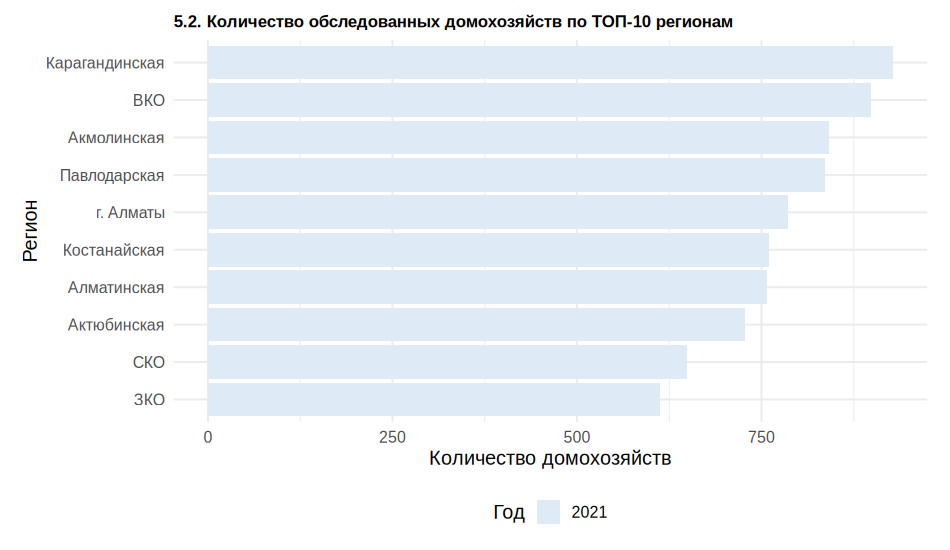

In [61]:
%%R -w 950 -h 550 -u px -r 110
# График 5.2. Распределение объема выборки по регионам (Top-10 TE). Объём выборки по десяти крупнейшим территориям (`TE`).
region_stat <- rio_all %>%
  mutate(TE = as.numeric(TE)) %>%
  mutate(Регион = case_when(
    TE == 10 ~ "Абайская",
    TE == 11 ~ "Акмолинская",
    TE == 15 ~ "Актюбинская",
    TE == 19 ~ "Алматинская",
    TE == 23 ~ "Атырауская",
    TE == 27 ~ "ЗКО",
    TE == 31 ~ "Жамбылская",
    TE == 33 ~ "Жетысуская",
    TE == 35 ~ "Карагандинская",
    TE == 39 ~ "Костанайская",
    TE == 43 ~ "Кызылординская",
    TE == 47 ~ "Мангистауская",
    TE == 55 ~ "Павлодарская",
    TE == 59 ~ "СКО",
    TE == 61 ~ "Туркестанская",
    TE == 62 ~ "Улытауская",
    TE == 63 ~ "ВКО",
    TE == 71 ~ "г. Астана",
    TE == 75 ~ "г. Алматы",
    TE == 79 ~ "г. Шымкент",
    TRUE ~ paste("Код", TE)
  )) %>%
  filter(!is.na(Регион)) %>%
  count(Регион, Year)
# Оставляем 10 регионов с наибольшим объёмом выборки
top_regs <- region_stat %>%
  group_by(Регион) %>%
  summarise(total = sum(n)) %>%
  top_n(10, total) %>%
  pull(Регион)
p <- ggplot(region_stat %>% filter(Регион %in% top_regs), aes(x = reorder(Регион, n), y = n, fill = Year)) +
  geom_bar(stat = "identity", position = "dodge") +
  coord_flip() +
  scale_fill_brewer(palette = "Blues", name = "Год") +
  labs(
    title = "5.2. Количество обследованных домохозяйств по ТОП-10 регионам",
    x = "Регион",
    y = "Количество домохозяйств"
  ) +
  theme_minimal(base_size = 13) +
  theme(
    legend.position = "bottom",
    plot.title = element_text(size = 11, face = "bold"),
    plot.margin = margin(10, 15, 10, 15)
  )

print(p)

`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


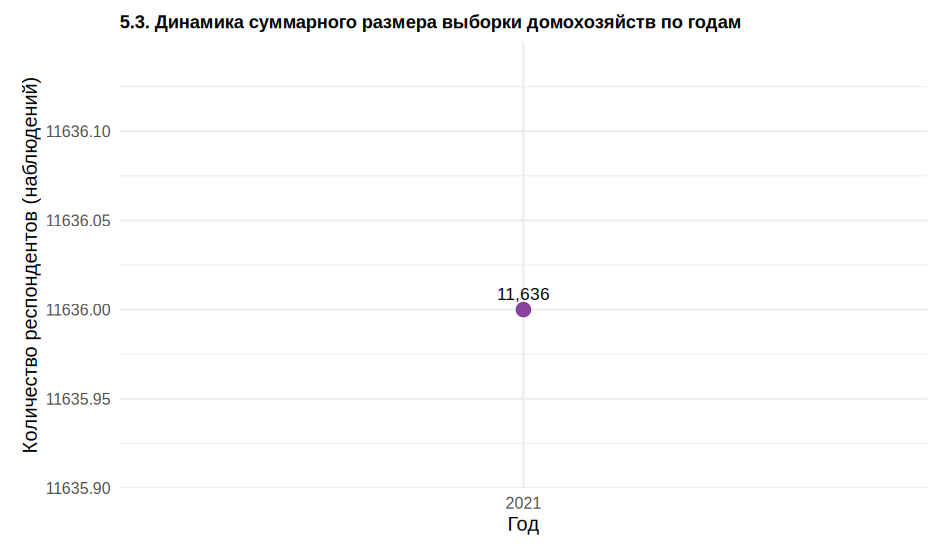

In [62]:
%%R -w 950 -h 550 -u px -r 110
# График 5.3. Общая динамика объема выборки по годам (2021–2024 гг.). Общий объём выборки по годам.
sample_size_stat <- rio_all %>%
  count(Year)
p <- ggplot(sample_size_stat, aes(x = Year, y = n, group = 1)) +
  geom_line(color = "#88419d", size = 1.3) +
  geom_point(color = "#88419d", size = 4) +
  geom_text(aes(label = scales::comma(n)), vjust = -0.8, size = 4) +
  scale_y_continuous(expand = expansion(mult = c(0.1, 0.15))) +
  labs(
    title = "5.3. Динамика суммарного размера выборки домохозяйств по годам",
    x = "Год",
    y = "Количество респондентов (наблюдений)"
  ) +
  theme_minimal(base_size = 13) +
  theme(
    plot.title = element_text(size = 12, face = "bold"),
    plot.margin = margin(10, 15, 10, 15)
  )

print(p)

`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


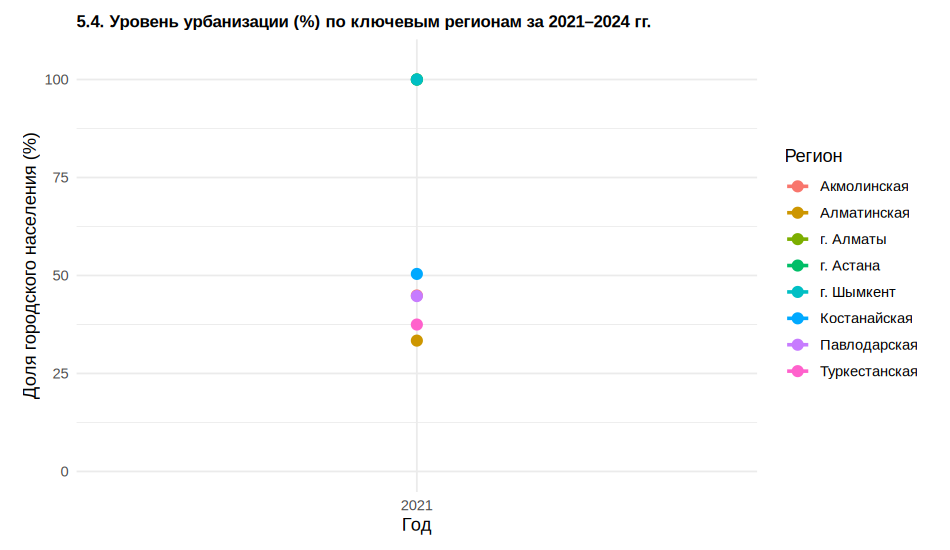

In [63]:
%%R -w 950 -h 550 -u px -r 110
# График 5.4. Доля городского населения в разрезе ключевых регионов (%). Доля городского населения по ключевым регионам.
urban_region_stat <- rio_all %>%
  mutate(
    TE = as.numeric(TE),
    K = as.numeric(K)
  ) %>%
  filter(K %in% c(1, 2)) %>%
  mutate(Регион = case_when(
    TE == 71 ~ "г. Астана",
    TE == 75 ~ "г. Алматы",
    TE == 79 ~ "г. Шымкент",
    TE == 55 ~ "Павлодарская",
    TE == 39 ~ "Костанайская",
    TE == 11 ~ "Акмолинская",
    TE == 19 ~ "Алматинская",
    TE == 61 ~ "Туркестанская",
    TRUE ~ paste("Код", TE)
  )) %>%
  filter(TE %in% c(71, 75, 79, 55, 39, 11, 19, 61)) %>% # Выбираем ключевые регионы
  group_by(Регион, Year) %>%
  summarise(
    Urban_Share = mean(K == 1, na.rm = TRUE) * 100,
    .groups = "drop"
  )
p <- ggplot(urban_region_stat, aes(x = Year, y = Urban_Share, color = Регион, group = Регион)) +
  geom_line(size = 1.1) +
  geom_point(size = 3) +
  scale_y_continuous(limits = c(0, 105)) +
  labs(
    title = "5.4. Уровень урбанизации (%) по ключевым регионам за 2021–2024 гг.",
    x = "Год",
    y = "Доля городского населения (%)",
    color = "Регион"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    legend.position = "right",
    plot.title = element_text(size = 11, face = "bold"),
    plot.margin = margin(10, 15, 10, 15)
  )

print(p)

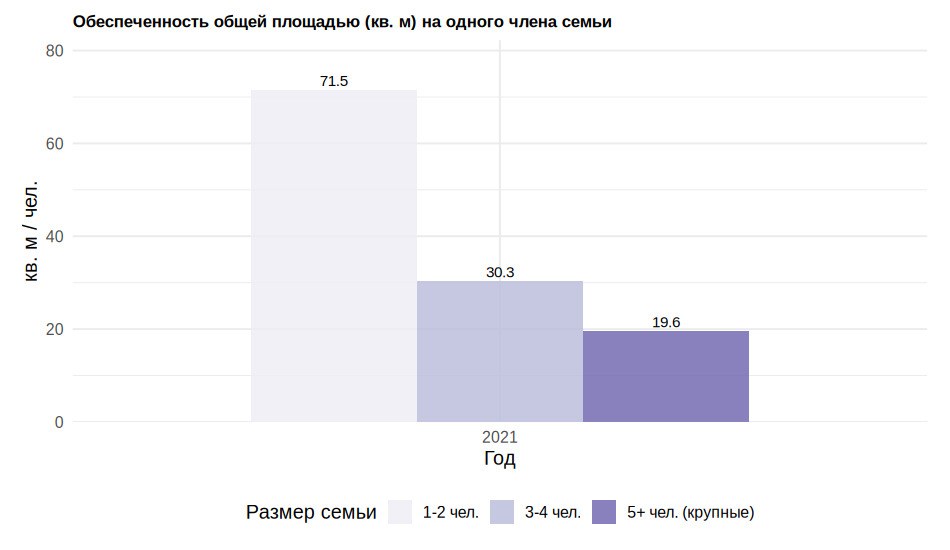

In [64]:
%%R -w 950 -h 550 -u px -r 110
# График 5.5. Обеспеченность жилой площадью на 1 человека по размеру семьи. Общая площадь на одного члена семьи по группам домохозяйств.
area_per_capita_stat <- rio_all %>%
  mutate(
    OB_PL = as.numeric(OB_PL),
    J_PL = as.numeric(J_PL)
  ) %>%
  mutate(across(starts_with("VOZ"), as.character)) %>%
  rowwise() %>%
  mutate(
    hh_size = sum(!is.na(c_across(starts_with("VOZ"))) &
                    c_across(starts_with("VOZ")) != "" &
                    c_across(starts_with("VOZ")) != "0")
  ) %>%
  ungroup() %>%
  filter(hh_size > 0 & OB_PL > 0 & OB_PL < 500) %>%
  mutate(
    Группа_семьи = case_when(
      hh_size %in% 1:2 ~ "1-2 чел.",
      hh_size %in% 3:4 ~ "3-4 чел.",
      hh_size >= 5     ~ "5+ чел. (крупные)"
    ),
    OB_PL_capita = OB_PL / hh_size
  ) %>%
  group_by(Year, Группа_семьи) %>%
  summarise(
    Средняя_площадь_на_чел = mean(OB_PL_capita, na.rm = TRUE),
    .groups = "drop"
  )
p <- ggplot(area_per_capita_stat, aes(x = Year, y = Средняя_площадь_на_чел, fill = Группа_семьи)) +
  geom_bar(stat = "identity", position = "dodge", alpha = 0.85, width = 0.7) +
  geom_text(aes(label = round(Средняя_площадь_на_чел, 1)),
            position = position_dodge(width = 0.7), vjust = -0.4, size = 3.5) +
  scale_fill_brewer(palette = "Purples", name = "Размер семьи") +
  scale_y_continuous(expand = expansion(mult = c(0, 0.15))) +
  labs(
    title = "Обеспеченность общей площадью (кв. м) на одного члена семьи",
    x = "Год",
    y = "кв. м / чел."
  ) +
  theme_minimal(base_size = 13) +
  theme(
    legend.position = "bottom",
    plot.title = element_text(size = 11, face = "bold"),
    plot.margin = margin(10, 15, 10, 15)
  )

print(p)

`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


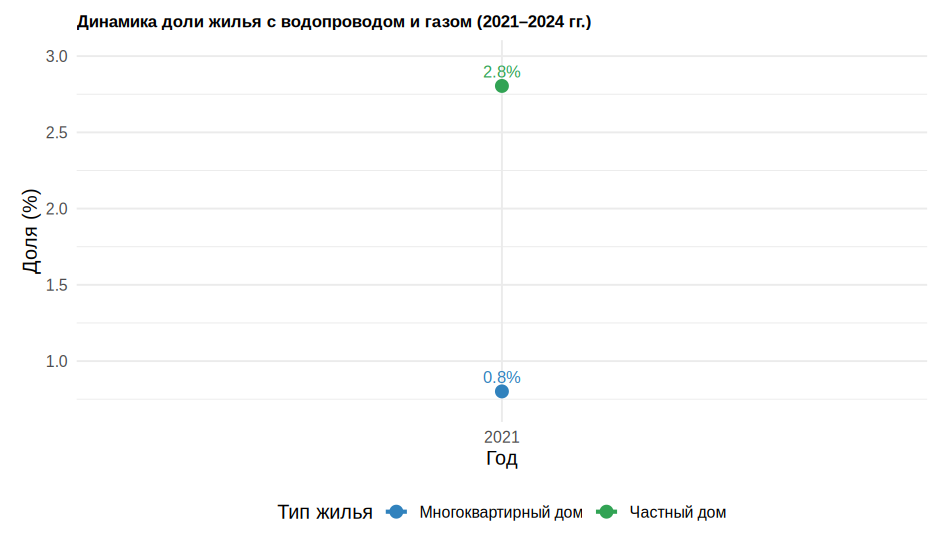

In [65]:
%%R -w 950 -h 550 -u px -r 110
# График 5.6. Эволюция благоустройства за 2021–2024 гг. (Частный сектор vs Квартиры). Динамика доли жилья с водопроводом и газом в частном секторе и в квартирах.
evolution_stat <- rio_all %>%
  mutate(
    TIP_J = as.numeric(TIP_J),
    U2 = as.numeric(U2),
    U5 = as.numeric(U5)
  ) %>%
  filter(TIP_J %in% c(1, 3)) %>%
  mutate(
    Тип_жилья = ifelse(TIP_J == 1, "Многоквартирный дом", "Частный дом"),
    Оснащено = ifelse(U2 == 1 & U5 == 1, 1, 0)
  ) %>%
  group_by(Year, Тип_жилья) %>%
  summarise(
    Доля = mean(Оснащено, na.rm = TRUE) * 100,
    .groups = "drop"
  )
p <- ggplot(evolution_stat, aes(x = Year, y = Доля, color = Тип_жилья, group = Тип_жилья)) +
  geom_line(size = 1.3) +
  geom_point(size = 3.5) +
  geom_text(aes(label = paste0(round(Доля, 1), "%")), vjust = -0.7, size = 3.8, show.legend = FALSE) +
  scale_color_manual(values = c("#3182bd", "#31a354")) +
  scale_y_continuous(expand = expansion(mult = c(0.1, 0.15))) +
  labs(
    title = "Динамика доли жилья с водопроводом и газом (2021–2024 гг.)",
    x = "Год",
    y = "Доля (%)",
    color = "Тип жилья"
  ) +
  theme_minimal(base_size = 13) +
  theme(
    legend.position = "bottom",
    plot.title = element_text(size = 11, face = "bold"),
    plot.margin = margin(10, 15, 10, 15)
  )

print(p)

## ВЫВОДЫ ПО АНАЛИЗУ D006

> Блок D006 построен на файле за 2021 год (в обработку попал один файл `rio.csv`, 11 636 домохозяйств), поэтому выводы описывают срез, а не динамику.

---

### 1. Жильё: преобладает собственность, но качество и обеспеченность площадью неравномерны
* **Инсайт:** 89,5 % домохозяйств проживают в собственном жилье, частная аренда — 7,5 %. Тип жилья: квартиры — 46,6 %, часть дома — 41,6 %, отдельный дом — 11,8 %; чаще всего встречаются 3-комнатные (38,4 %) и 2-комнатные (29,4 %) жилища.
* **Детализация данных:** Площадь на человека резко падает с ростом семьи: 71,5 кв. м в семьях из 1–2 человек, 30,3 — из 3–4 и 19,6 — из 5 и более человек.
* **Политический вывод (Policy):** Проблема жилья в Казахстане — не в доле собственников, а в доступности достаточной площади для больших семей. Меры стоит ориентировать на семьи с 3+ членами.

---

### 2. Коммунальная инфраструктура: электрификация полная, остальные сети — частичные
* **Инсайт:** Электричеством обеспечено практически 100 % жилья, тогда как центральное отопление есть у 46,5 %, сетевой газ — у 44 %, канализация — у 39 %, водопровод — у 19,5 %. Печное и прочее отопление используют 31,1 % домохозяйств.
* **Политический вывод (Policy):** Приоритет инфраструктурных программ — водоснабжение и канализация: именно по ним охват самый низкий.

---

### 3. Демографический и географический профиль выборки
* **Инсайт:** 55 % выборки — городские домохозяйства, 45 % — сельские. Средний возраст главы домохозяйства — 52,7 года, 17,9 % — люди 65+, 43,9 % — женщины.
* **Политический вывод (Policy):** Значительная доля домохозяйств возглавляется людьми старшего возраста: меры жилищной и коммунальной поддержки должны учитывать пожилых.

## Анализ D008 — демографический состав и занятость
Модуль `d008 / kontr_k.csv`: образование, статус занятости и семейное положение членов домохозяйств.

In [66]:
with open('/content/drive/MyDrive/Datathon/D008.sql', 'r', encoding='utf-8') as f:
    sql_d008 = f.read()

print("Размер файла D008.sql:", len(sql_d008), "символов")
print("=== Первые 1500 символов ===")
print(sql_d008[:1500])

Размер файла D008.sql: 3669 символов
=== Первые 1500 символов ===
WITH unpivoted_demography AS (
    -- 1. Читаем все года, приводим коды к числам и разворачиваем колонки в строки за один проход
    UNPIVOT (
        SELECT 
            regexp_extract(filename, '.*\\([0-9]{4})\\', 1) AS yr,
            K::INTEGER AS local_k,
            rodstvo::INTEGER AS rodstvo,
            pol::INTEGER AS pol,
            sem_pol::INTEGER AS sem_pol,
            urov::INTEGER AS urov,
            status::INTEGER AS status
        FROM read_csv('/content/drive/MyDrive/Datathon/synthetic_microdata_2021-2024_20260921/d008/**/*.csv', union_by_name=true, filename=true, ignore_errors=true)
    )
    ON rodstvo, pol, sem_pol, urov, status
    INTO NAME group_name VALUE kod
),
translated_data AS (
    -- 2. Переводим коды вопросов и ответов на человеческий язык по вашему справочнику
    SELECT 
        yr, local_k, kod,
        CASE group_name
            WHEN 'rodstvo' THEN '1. Отношение к главе хозяйства

In [67]:
import duckdb

# Адаптируем извлечение года из пути файла к формату путей Linux
sql_d008_fixed = sql_d008.replace("regexp_extract(filename, '.*\\\\([0-9]{4})\\\\', 1)", "regexp_extract(filename, '.*/([0-9]{4})/', 1)")

try:
    result = duckdb.query(sql_d008_fixed).limit(10).df()
    display(result)
except Exception as e:
    print("Ошибка при выполнении запроса:", e)
    print("Попробуем вывести оригинальный SQL, чтобы точнее понять структуру автозамены:")
    print(sql_d008)

,Год,Местность,Категория,Вариант ответа,Человек (абс.),Процент (%)
0,2021,Город,1. Отношение к главе хозяйства,глава домашнего хозяйства,6698,29.7
1,2021,Город,1. Отношение к главе хозяйства,"муж, жена",4073,18.0
2,2021,Город,1. Отношение к главе хозяйства,"сын, дочь",8343,36.9
3,2021,Город,1. Отношение к главе хозяйства,"отец, мать",756,3.3
4,2021,Город,1. Отношение к главе хозяйства,"брат, сестра",273,1.2
5,2021,Город,1. Отношение к главе хозяйства,"дедушка, бабушка",41,0.2
6,2021,Город,1. Отношение к главе хозяйства,"внук, внучка",1408,6.2
7,2021,Город,1. Отношение к главе хозяйства,другая степень родства,927,4.1
8,2021,Город,1. Отношение к главе хозяйства,не родственник,67,0.3
9,2021,Город,2. Пол,мужской,10225,45.3


In [68]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Полная таблица D008: образование, занятость, семейное положение, родство
df_full = duckdb.query(sql_d008_fixed).df()

# Категории и типы местности — для последующей фильтрации
print("Доступные категории:")
print(df_full['Категория'].unique())
print("\nДоступные типы местности:")
print(df_full['Местность'].unique())
print("\nПример данных:")
display(df_full.head(10))

Доступные категории:
['1. Отношение к главе хозяйства' '2. Пол' '3. Семейное положение'
 '4. Уровень образования' '5. Статус деятельности']

Доступные типы местности:
['Город' 'Село']

Пример данных:


,Год,Местность,Категория,Вариант ответа,Человек (абс.),Процент (%)
0,2021,Город,1. Отношение к главе хозяйства,глава домашнего хозяйства,6698,29.7
1,2021,Город,1. Отношение к главе хозяйства,"муж, жена",4073,18.0
2,2021,Город,1. Отношение к главе хозяйства,"сын, дочь",8343,36.9
3,2021,Город,1. Отношение к главе хозяйства,"отец, мать",756,3.3
4,2021,Город,1. Отношение к главе хозяйства,"брат, сестра",273,1.2
5,2021,Город,1. Отношение к главе хозяйства,"дедушка, бабушка",41,0.2
6,2021,Город,1. Отношение к главе хозяйства,"внук, внучка",1408,6.2
7,2021,Город,1. Отношение к главе хозяйства,другая степень родства,927,4.1
8,2021,Город,1. Отношение к главе хозяйства,не родственник,67,0.3
9,2021,Город,2. Пол,мужской,10225,45.3


In [69]:
# Варианты ответов по каждой категории —
# нужны для точной фильтрации групп на графиках
for cat in df_full['Категория'].unique():
    print(f"=== {cat} ===")
    print(df_full[df_full['Категория'] == cat]['Вариант ответа'].unique())
    print()

=== 1. Отношение к главе хозяйства ===
['глава домашнего хозяйства' 'муж, жена' 'сын, дочь' 'отец, мать'
 'брат, сестра' 'дедушка, бабушка' 'внук, внучка' 'другая степень родства'
 'не родственник']

=== 2. Пол ===
['мужской' 'женский']

=== 3. Семейное положение ===
['никогда не состоял(а) в браке' 'состоит в браке' 'вдовец, вдова'
 'разведен(а)']

=== 4. Уровень образования ===
['дошкольное' 'начальное' 'основное среднее' 'среднее (общее, ТиПО)'
 'высшее' 'послевузовское' 'никакого уровня']

=== 5. Статус деятельности ===
['работает по найму' 'работает не по найму' 'безработный (ищет работу)'
 'пенсионер' 'учащийся, студент' 'домашнее хозяйство, уход за детьми'
 'нетрудоспособный' 'не работает и не ищет (др. причины)']



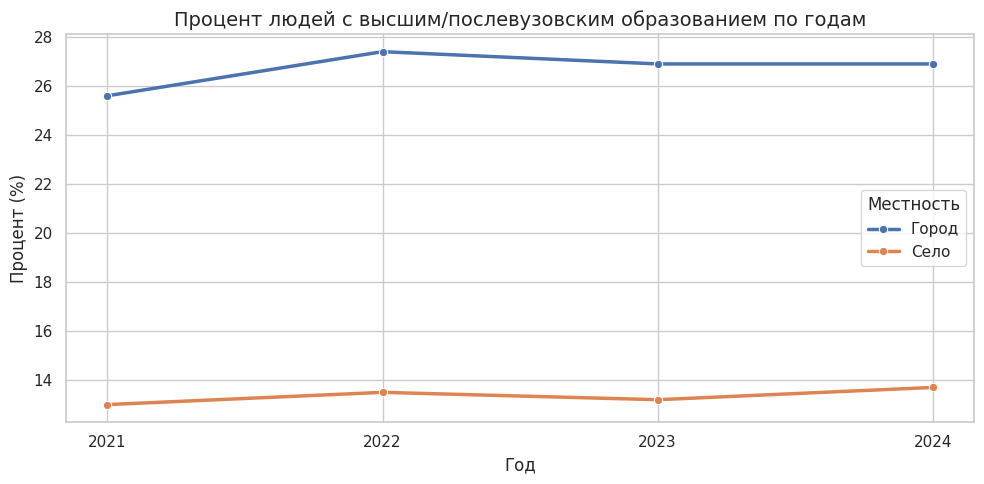

In [70]:
import numpy as np

# Стиль графиков
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)


# 1. Динамика доли людей с высшим и послевузовским образованием
edu_filter = df_full['Вариант ответа'].str.contains('высшее|послевузовское|postgraduate|higher|университет|магистр|бакалавр', case=False, na=False)
df_edu = df_full[(df_full['Категория'].str.contains('образования', case=False)) & edu_filter]

# Суммируем долю по годам и типу местности
df_edu_grouped = df_edu.groupby(['Год', 'Местность'])['Процент (%)'].sum().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(data=df_edu_grouped, x='Год', y='Процент (%)', hue='Местность', marker='o', linewidth=2.5)
plt.title('Процент людей с высшим/послевузовским образованием по годам', fontsize=14)
plt.ylabel('Процент (%)')
plt.xlabel('Год')
plt.tight_layout()
plt.show()

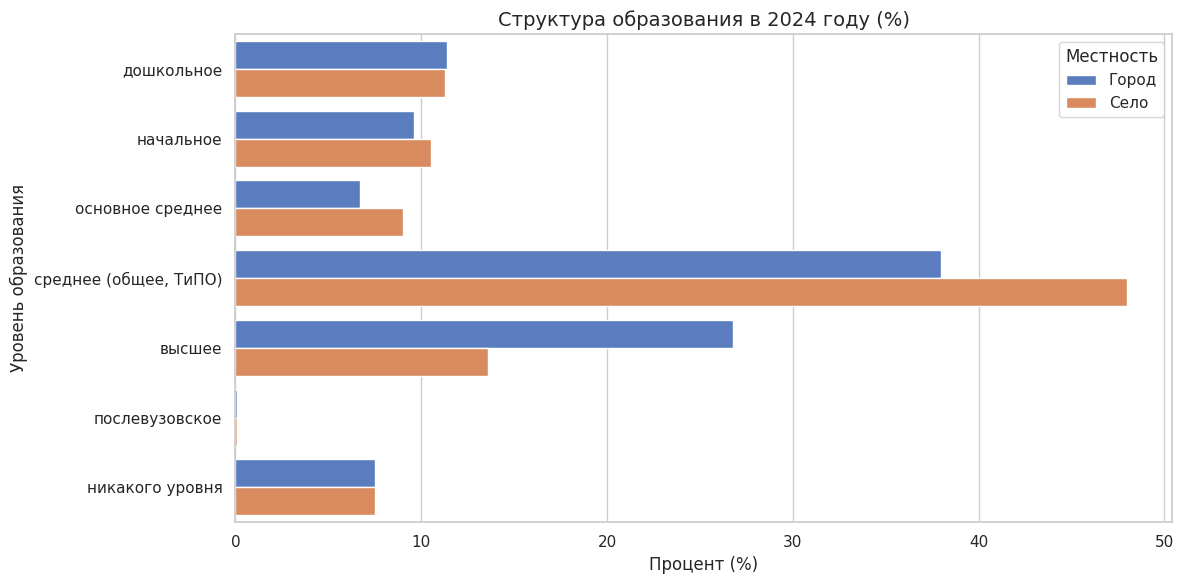

In [71]:
# 2. Горизонтальная гистограмма: структура образования в 2024 году в процентах
df_edu_2024 = df_full[(df_full['Категория'].str.contains('образования', case=False)) & (df_full['Год'] == '2024')]

plt.figure(figsize=(12, 6))
sns.barplot(data=df_edu_2024, x='Процент (%)', y='Вариант ответа', hue='Местность', palette='muted')
plt.title('Структура образования в 2024 году (%)', fontsize=14)
plt.xlabel('Процент (%)')
plt.ylabel('Уровень образования')
plt.tight_layout()
plt.show()

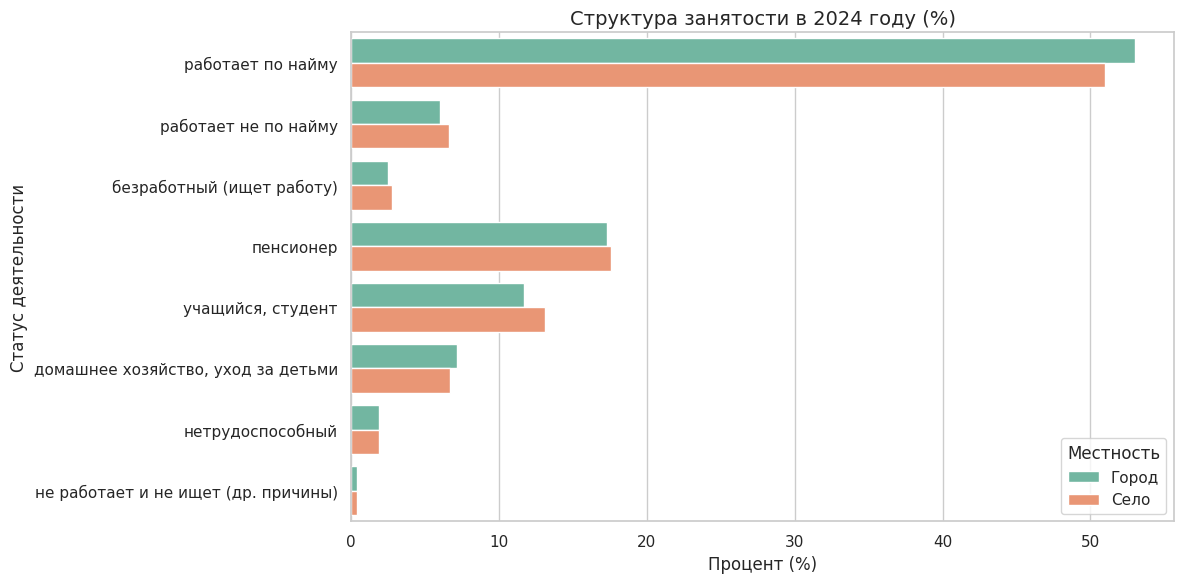

In [72]:
# 3. Горизонтальная гистограмма: структура занятости в 2024 году в процентах
df_status_2024 = df_full[(df_full['Категория'].str.contains('деятельности|статус', case=False)) & (df_full['Год'] == '2024')]

plt.figure(figsize=(12, 6))
sns.barplot(data=df_status_2024, x='Процент (%)', y='Вариант ответа', hue='Местность', palette='Set2')
plt.title('Структура занятости в 2024 году (%)', fontsize=14)
plt.xlabel('Процент (%)')
plt.ylabel('Статус деятельности')
plt.tight_layout()
plt.show()

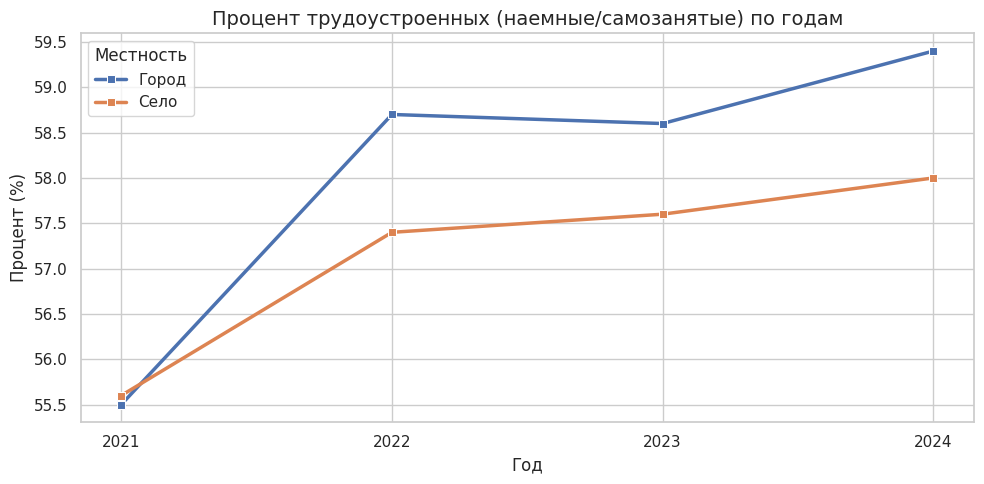

In [73]:
# 4. Линейный график по годам: % трудоустроенных людей (наемные рабочие или самозанятые)
# Занятые: работающие по найму и не по найму
work_filter = df_full['Вариант ответа'].str.contains('наемн|самозаня|работа|занят', case=False, na=False)
df_work = df_full[(df_full['Категория'].str.contains('деятельности|статус', case=False)) & work_filter]

df_work_grouped = df_work.groupby(['Год', 'Местность'])['Процент (%)'].sum().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(data=df_work_grouped, x='Год', y='Процент (%)', hue='Местность', marker='s', linewidth=2.5)
plt.title('Процент трудоустроенных (наемные/самозанятые) по годам', fontsize=14)
plt.ylabel('Процент (%)')
plt.xlabel('Год')
plt.tight_layout()
plt.show()

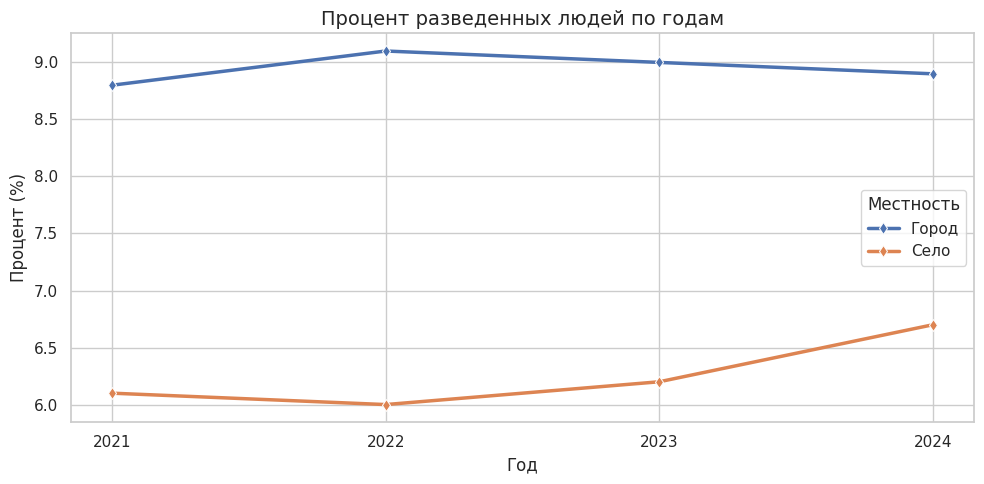

In [74]:
# 5. Линейный график по годам: % разведенных людей
# Доля разведённых в категории «Семейное положение»
divorce_filter = df_full['Вариант ответа'].str.contains('разведен|расторг', case=False, na=False)
df_divorce = df_full[(df_full['Категория'].str.contains('семейное', case=False)) & divorce_filter]

df_divorce_grouped = df_divorce.groupby(['Год', 'Местность'])['Процент (%)'].sum().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(data=df_divorce_grouped, x='Год', y='Процент (%)', hue='Местность', marker='d', linewidth=2.5)
plt.title('Процент разведенных людей по годам', fontsize=14)
plt.ylabel('Процент (%)')
plt.xlabel('Год')
plt.tight_layout()
plt.show()

## ВЫВОДЫ ПО АНАЛИЗУ D008

> Показатели рассчитаны по всем членам домохозяйств (включая детей), поэтому доли с дошкольным и начальным образованием отражают возрастной состав, а не «недообразованность».

---

### 1. Образовательный разрыв между городом и селом
* **Инсайт:** Доля людей с высшим и послевузовским образованием в городе стабильно вдвое выше, чем на селе: около 27 % против 13–14 % во все годы 2021–2024.
* **Детализация данных:** Структура образования в 2024 г.: на селе преобладает среднее общее и ТиПО (около 48 % против 38 % в городе), высшее — около 13 % против 27 %.
* **Политический вывод (Policy):** Разрыв не сокращается за четыре года. Для села нужны программы доступа к высшему образованию (целевые гранты, дистанционные форматы) и привязка образования к местному рынку труда.

---

### 2. Занятость растёт, структура остаётся устойчивой
* **Инсайт:** Доля занятых (по найму и не по найму) выросла с 55,5 % в 2021 г. до 59,4 % в городе и 58,0 % на селе в 2024 г.; основной скачок пришёлся на 2021–2022 гг.
* **Детализация данных:** В 2024 г. по найму работают около 53 % городских и 51 % сельских жителей, пенсионеры составляют около 17 %, безработные — менее 3 %. Различия между городом и селом по занятости небольшие (1–1,5 п.п.).
* **Политический вывод (Policy):** Главная проблема не в уровне занятости, а в её качестве и доходах — это подтверждается разделом H1: даже при занятости нижний дециль дохода остаётся наиболее уязвимым.

---

### 3. Семейное положение: рост доли разведённых на селе
* **Инсайт:** Доля разведённых в городе стабильна (около 8,8–9,1 %), на селе выросла с 6,1 % до 6,7 % за 2021–2024 гг.
* **Политический вывод (Policy):** Сельские домохозяйства постепенно сближаются с городскими по демографическому профилю; это стоит учитывать при планировании мер поддержки неполных семей.

## ЭТАП 2: ФОРМИРОВАНИЕ РАБОЧИХ ГИПОТЕЗ

На основе первичного анализа данных исследовательская группа команды **InsightX** сформулировала три фундаментальные гипотезы. Они легли в основу нашего исследования и разработки рекомендаций для государственной политики.

---

###  Гипотеза H1 — Финансовая устойчивость
Чем ниже уровень дохода домохозяйства, тем выше вероятность превышения текущих расходов над текущими доходами (формирование хронического финансового дефицита).

---

###  Гипотеза H2 — Структура и условия домохозяйства
Финансовая уязвимость выше у домохозяйств с определёнными социально-демографическими характеристиками (размер, состав семьи) и менее благоприятными условиями проживания.

---

###  Гипотеза H3 — Финансовая уязвимость и качество жизни
Домохозяйства с более высокой финансовой уязвимостью имеют более низкие субъективные оценки качества жизни.


## Проверка H1

In [75]:
# Проверяем, что данные D004 (расходы участников) уже загружены в память
missing = [n for n in ("d004_path", "expenses_valid", "show") if n not in globals()]
assert not missing, f"Сначала выполните блокнот D004 (настройка и шаги 1–6). Не найдено: {missing}"

import pandas as pd
pd.set_option("display.max_columns", None)   # показывать все 33 столбца таблицы доходов

In [76]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [77]:
# Проверяем таблицу доходов D004
# Проверяем таблицу доходов D004
income_path = d004_path / "2024" / "1kv" / "kv_vopr11.csv"

income = pd.read_csv(income_path)

print("Размер таблицы:", income.shape)
print("\nСтолбцы:")
print(income.columns.tolist())

print("\nПервые 5 строк:")
show(income.head())

Размер таблицы: (24535, 33)

Столбцы:
['TE', 'K', 'NOMP', 'VOZ', 'POL', 'NOMVOPR', 'NOMVNEW', 'GR1', 'GR2', 'GR3', 'GR4', 'GR5', 'GR6', 'GR7', 'GR8', 'GR9', 'GR10', 'GR11', 'GR12', 'GR13', 'GR14', 'GR15', 'GR16', 'GR17', 'GR18', 'GR19', 'GR20', 'GR21', 'GR22', 'GR23', 'KVARTAL', 'GOD', 'NOMER']

Первые 5 строк:


,TE,K,NOMP,VOZ,POL,NOMVOPR,NOMVNEW,GR1,GR2,GR3,GR4,GR5,GR6,GR7,GR8,GR9,GR10,GR11,GR12,GR13,GR14,GR15,GR16,GR17,GR18,GR19,GR20,GR21,GR22,GR23,KVARTAL,GOD,NOMER
0,43,1,1,45,1,111,300,480000,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,2024,2024000001
1,43,1,2,64,2,111,300,0,0,0,496000,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,2024,2024000001
2,31,2,1,44,2,111,300,375000,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,11696,0,1,2024,2024000002
3,31,2,2,60,2,111,300,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,757363,0,0,0,0,0,10900,26000,1,2024,2024000002
4,75,1,1,44,1,111,300,450000,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,14768,0,1,2024,2024000003


In [78]:
# Проверяем, какие показатели дохода реально заполнены
# Проверяем, какие показатели дохода реально заполнены
gr_columns = [col for col in income.columns if col.startswith("GR")]

income_check = pd.DataFrame({
    "Столбец": gr_columns,
    "Ненулевых значений": [
        (pd.to_numeric(income[col], errors="coerce").fillna(0) != 0).sum()
        for col in gr_columns
    ],
    "Сумма": [
        pd.to_numeric(income[col], errors="coerce").fillna(0).sum()
        for col in gr_columns
    ]
})

show(income_check)

,Столбец,Ненулевых значений,Сумма
0,GR1,15239,8428928586
1,GR2,2348,1031909325
2,GR3,532,110523908
3,GR4,5451,2042532708
4,GR5,647,77681127
5,GR6,31,5529794
6,GR7,29,1009303
7,GR8,1282,262118357
8,GR9,1219,269130383
9,GR10,278,44243730


In [79]:
# Показываем только столбцы с доходами и идентификаторы
# Показываем только столбцы с доходами и идентификаторы
income_view = income[
    ["NOMER", "NOMP", "GOD", "KVARTAL"] + gr_columns
].copy()

show(income_view.head(10).T)

,0,1,2,3,4,5,6,7,8,9
NOMER,2024000001,2024000001,2024000002,2024000002,2024000003,2024000003,2024000004,2024000005,2024000005,2024000006
NOMP,1,2,1,2,1,2,1,1,2,1
GOD,2024,2024,2024,2024,2024,2024,2024,2024,2024,2024
KVARTAL,1,1,1,1,1,1,1,1,1,1
GR1,480000,0,375000,0,450000,0,243000,0,255000,1020000
GR2,0,0,0,0,0,0,0,0,0,0
GR3,0,0,0,0,0,0,0,0,0,0
GR4,0,496000,0,0,0,488613,0,390000,0,0
GR5,0,0,0,0,0,0,0,0,0,0
GR6,0,0,0,0,0,0,0,0,0,0


In [80]:
# Суммарный доход домохозяйства за квартал
# Суммарный доход домохозяйства за квартал

# Все показатели дохода GR1–GR23
gr_columns = [col for col in income.columns if col.startswith("GR")]

# Приводим доходы к числам
for col in gr_columns:
    income[col] = pd.to_numeric(income[col], errors="coerce").fillna(0)

# Сначала считаем общий доход каждого человека
income["total_income_person"] = income[gr_columns].sum(axis=1)

# Затем суммируем доходы всех членов каждого домохозяйства
income_household = (
    income
    .groupby(["NOMER", "GOD", "KVARTAL"])["total_income_person"]
    .sum()
    .reset_index()
)

income_household = income_household.rename(
    columns={"total_income_person": "income"}
)

print("Домохозяйств-кварталов с рассчитанным доходом:",
      len(income_household))

show(income_household.head(10))

Домохозяйств-кварталов с рассчитанным доходом: 11913


,NOMER,GOD,KVARTAL,income
0,2024000001,2024,1,976000
1,2024000002,2024,1,1180959
2,2024000003,2024,1,968149
3,2024000004,2024,1,243000
4,2024000005,2024,1,669735
5,2024000006,2024,1,2571900
6,2024000007,2024,1,785000
7,2024000008,2024,1,1500000
8,2024000010,2024,1,865960
9,2024000011,2024,1,450000


In [81]:
# Загружаем доходы за все кварталы 2021–2024
# Загружаем доходы за все кварталы 2021–2024

income_all = []

for year in range(2021, 2025):
    for quarter in range(1, 5):
        path = d004_path / str(year) / f"{quarter}kv" / "kv_vopr11.csv"

        table = pd.read_csv(path)

        # Все показатели дохода
        gr_columns = [col for col in table.columns if col.startswith("GR")]

        # Переводим доходы в числа
        for col in gr_columns:
            table[col] = pd.to_numeric(
                table[col], errors="coerce"
            ).fillna(0)

        # Общий доход человека
        table["total_income_person"] = table[gr_columns].sum(axis=1)

        table["year"] = year
        table["quarter"] = quarter

        income_all.append(
            table[[
                "NOMER",
                "NOMP",
                "year",
                "quarter",
                "total_income_person"
            ]]
        )

# Объединяем все кварталы
income_all = pd.concat(income_all, ignore_index=True)

# Суммируем доходы всех членов семьи
income_household_all = (
    income_all
    .groupby(["NOMER", "year", "quarter"])["total_income_person"]
    .sum()
    .reset_index()
    .rename(columns={
        "total_income_person": "income"
    })
)

print(
    "Домохозяйств-кварталов с доходом:",
    len(income_household_all)
)

show(income_household_all.head(10))

Домохозяйств-кварталов с доходом: 188122


,NOMER,year,quarter,income
0,2021000001,2021,1,712742
1,2021000001,2021,2,671206
2,2021000001,2021,3,609241
3,2021000001,2021,4,574241
4,2021000002,2021,1,1090400
5,2021000002,2021,2,887700
6,2021000002,2021,3,1345000
7,2021000002,2021,4,1379641
8,2021000003,2021,1,390000
9,2021000003,2021,2,639200


In [82]:
# Суммируем все расходы домохозяйства за каждый квартал
# Суммируем все расходы домохозяйства за каждый квартал

expenses_household = (
    expenses_valid
    .groupby(["NOMER", "year", "quarter"])["STOIMK"]
    .sum()
    .reset_index()
    .rename(columns={
        "STOIMK": "expenses"
    })
)

print(
    "Домохозяйств-кварталов с расходами:",
    len(expenses_household)
)

show(expenses_household.head(10))

Домохозяйств-кварталов с расходами: 189104


,NOMER,year,quarter,expenses
0,2021000001,2021,1,350602
1,2021000001,2021,2,191974
2,2021000001,2021,3,286713
3,2021000001,2021,4,454494
4,2021000002,2021,1,159368
5,2021000002,2021,2,114715
6,2021000002,2021,3,83966
7,2021000002,2021,4,339350
8,2021000003,2021,1,169195
9,2021000003,2021,2,150278


In [83]:
# Объединяем доходы и расходы домохозяйств
# Объединяем доходы и расходы домохозяйств

financial = income_household_all.merge(
    expenses_household,
    on=["NOMER", "year", "quarter"],
    how="inner",
    validate="one_to_one"
)

# Финансовый результат
financial["balance"] = financial["income"] - financial["expenses"]

# Есть ли финансовый дефицит?
financial["deficit"] = financial["expenses"] > financial["income"]

print("Совпавших домохозяйств-кварталов:", len(financial))
print(
    "Домохозяйств-кварталов с дефицитом:",
    financial["deficit"].sum()
)

print(
    "Доля домохозяйств-кварталов с дефицитом:",
    round(financial["deficit"].mean() * 100, 2),
    "%"
)

show(
    financial[
        ["NOMER", "year", "quarter", "income", "expenses", "balance", "deficit"]
    ].head(10)
)

Совпавших домохозяйств-кварталов: 188117
Домохозяйств-кварталов с дефицитом: 18018
Доля домохозяйств-кварталов с дефицитом: 9.58 %


,NOMER,year,quarter,income,expenses,balance,deficit
0,2021000001,2021,1,712742,350602,362140,False
1,2021000001,2021,2,671206,191974,479232,False
2,2021000001,2021,3,609241,286713,322528,False
3,2021000001,2021,4,574241,454494,119747,False
4,2021000002,2021,1,1090400,159368,931032,False
5,2021000002,2021,2,887700,114715,772985,False
6,2021000002,2021,3,1345000,83966,1261034,False
7,2021000002,2021,4,1379641,339350,1040291,False
8,2021000003,2021,1,390000,169195,220805,False
9,2021000003,2021,2,639200,150278,488922,False


In [84]:
# Проверяем распределение дохода перед формированием групп
# Проверяем распределение дохода перед формированием групп

print("Всего наблюдений:", len(financial))
print("Пропуски дохода:", financial["income"].isna().sum())
print("Нулевой доход:", (financial["income"] == 0).sum())
print("Отрицательный доход:", (financial["income"] < 0).sum())

print("\nКвантили дохода:")
show(
    financial["income"].quantile(
        [0, 0.1, 0.25, 0.5, 0.75, 0.9, 1]
    ).round(0)
)

Всего наблюдений: 188117
Пропуски дохода: 0
Нулевой доход: 233
Отрицательный доход: 0

Квантили дохода:


,income
0.00,0.0
0.10,304291.0
0.25,495000.0
0.50,791730.0
0.75,1197000.0
0.90,1680930.0
1.00,36836544.0


In [85]:
# H1 — делим домохозяйства на 10 групп по уровню дохода
# H1 — делим домохозяйства на 10 групп по уровню дохода

financial["income_decile"] = pd.qcut(
    financial["income"],
    10,
    labels=False,
    duplicates="drop"
) + 1

# Таблица по децилям дохода
h1_deciles = (
    financial
    .groupby("income_decile")
    .agg(
        Домохозяйств=("NOMER", "size"),
        Средний_доход=("income", "mean"),
        Медианный_доход=("income", "median"),
        Дефицитных=("deficit", "sum"),
        Доля_дефицита=("deficit", "mean")
    )
    .reset_index()
)

h1_deciles["Доля_дефицита"] = (
    h1_deciles["Доля_дефицита"] * 100
)

print("Результат H1 по децилям дохода:")
show(h1_deciles.round(1))

Результат H1 по децилям дохода:


,income_decile,Домохозяйств,Средний_доход,Медианный_доход,Дефицитных,Доля_дефицита
0,1,18818,222 191.9,240 000.0,9253,49.2
1,2,18824,372 194.9,372 129.0,3910,20.8
2,3,18797,496 393.0,495 000.0,2058,10.9
3,4,18819,611 082.3,610 930.0,1190,6.3
4,5,18801,730 713.5,731 200.0,689,3.7
5,6,18811,858 885.1,857 696.0,418,2.2
6,7,18819,1 008 786.7,1 007 961.0,238,1.3
7,8,18804,1 198 357.7,1 197 000.5,145,0.8
8,9,18813,1 480 329.7,1 470 000.0,56,0.3
9,10,18811,2 226 185.4,2 039 680.0,61,0.3


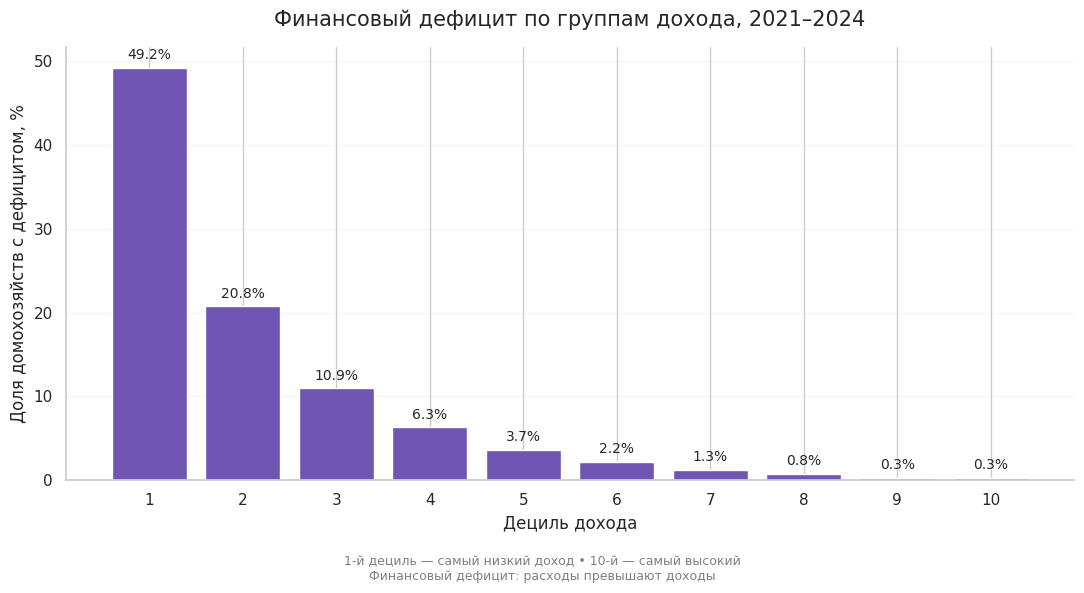

In [86]:
# График 1 — доля домохозяйств с финансовым дефицитом по децилям дохода
# График 1 — доля домохозяйств с финансовым дефицитом
# по децилям дохода

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    h1_deciles["income_decile"],
    h1_deciles["Доля_дефицита"],
    color="#7155B5",
    edgecolor="white"
)

# Подписываем значения над столбцами
ax.bar_label(
    bars,
    labels=[f"{v:.1f}%" for v in h1_deciles["Доля_дефицита"]],
    padding=4,
    fontsize=10
)

ax.set_title(
    "Финансовый дефицит по группам дохода, 2021–2024",
    fontsize=15,
    pad=15
)

ax.set_xlabel("Дециль дохода")
ax.set_ylabel("Доля домохозяйств с дефицитом, %")

ax.set_xticks(range(1, 11))

ax.grid(
    axis="y",
    alpha=0.2
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.text(
    0.5,
    0.02,
    "1-й дециль — самый низкий доход • 10-й — самый высокий\n"
    "Финансовый дефицит: расходы превышают доходы",
    ha="center",
    fontsize=9,
    color="gray"
)

plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

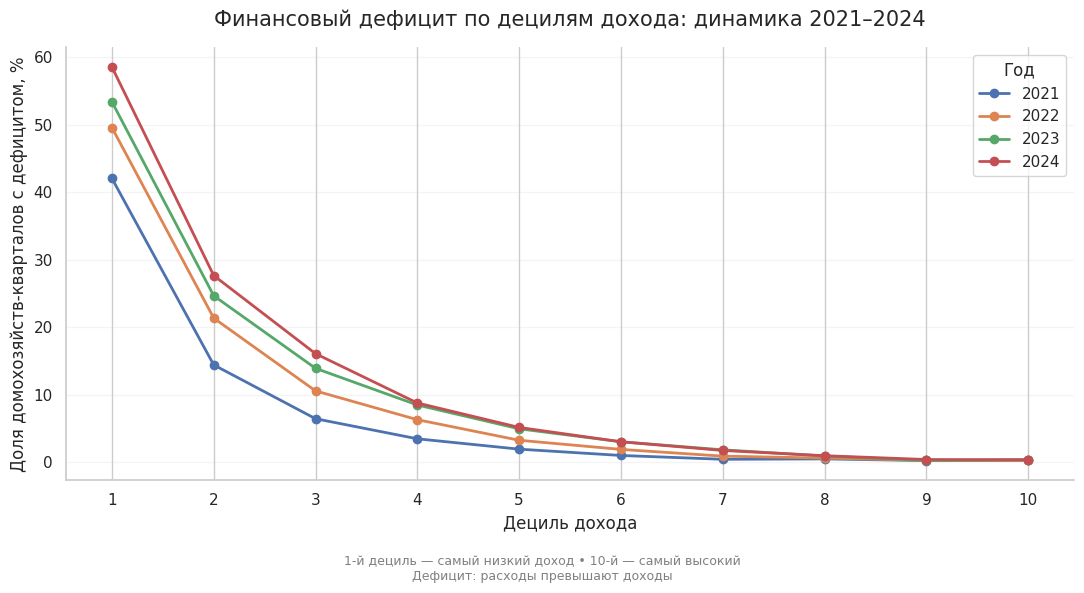

In [87]:
# График 2 — проверка H1 по годам
# График 2 — проверка H1 по годам

h1_by_year = (
    financial
    .groupby(["year", "income_decile"])["deficit"]
    .mean()
    .mul(100)
    .reset_index()
)

fig, ax = plt.subplots(figsize=(11, 6))

for year in sorted(h1_by_year["year"].unique()):
    data = h1_by_year[h1_by_year["year"] == year]

    ax.plot(
        data["income_decile"],
        data["deficit"],
        marker="o",
        linewidth=2,
        label=str(year)
    )

ax.set_title(
    "Финансовый дефицит по децилям дохода: динамика 2021–2024",
    fontsize=15,
    pad=15
)

ax.set_xlabel("Дециль дохода")
ax.set_ylabel("Доля домохозяйств-кварталов с дефицитом, %")

ax.set_xticks(range(1, 11))

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(title="Год")

fig.text(
    0.5,
    0.02,
    "1-й дециль — самый низкий доход • 10-й — самый высокий\n"
    "Дефицит: расходы превышают доходы",
    ha="center",
    fontsize=9,
    color="gray"
)

plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

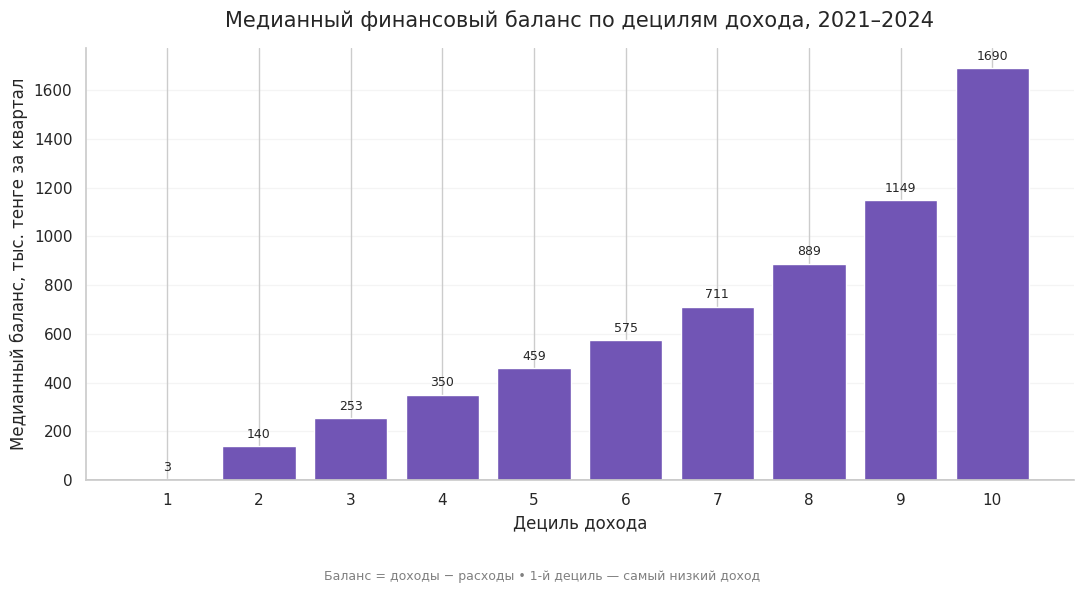

In [88]:
# График 3 — медианный финансовый баланс по децилям дохода
# График 3 — медианный финансовый баланс по децилям дохода

h1_balance = (
    financial
    .groupby("income_decile")["balance"]
    .median()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    h1_balance["income_decile"],
    h1_balance["balance"] / 1000,
    color="#7155B5"
)

ax.axhline(
    0,
    color="black",
    linewidth=1
)

ax.bar_label(
    bars,
    labels=[
        f"{v:.0f}"
        for v in h1_balance["balance"] / 1000
    ],
    padding=4,
    fontsize=9
)

ax.set_title(
    "Медианный финансовый баланс по децилям дохода, 2021–2024",
    fontsize=15,
    pad=15
)

ax.set_xlabel("Дециль дохода")
ax.set_ylabel("Медианный баланс, тыс. тенге за квартал")

ax.set_xticks(range(1, 11))

ax.grid(
    axis="y",
    alpha=0.2
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.text(
    0.5,
    0.02,
    "Баланс = доходы − расходы • 1-й дециль — самый низкий доход",
    ha="center",
    fontsize=9,
    color="gray"
)

plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

In [89]:
# Итоговая сводка H1
# Итоговая сводка H1

h1_summary = pd.DataFrame({
    "Показатель": [
        "Доля дефицита, 1-й дециль",
        "Доля дефицита, 10-й дециль",
        "Разрыв между 1-м и 10-м децилем"
    ],
    "Значение": [
        h1_deciles.loc[h1_deciles["income_decile"] == 1, "Доля_дефицита"].iloc[0],
        h1_deciles.loc[h1_deciles["income_decile"] == 10, "Доля_дефицита"].iloc[0],
        (
            h1_deciles.loc[h1_deciles["income_decile"] == 1, "Доля_дефицита"].iloc[0]
            -
            h1_deciles.loc[h1_deciles["income_decile"] == 10, "Доля_дефицита"].iloc[0]
        )
    ],
    "Единица": ["%", "%", "п.п."]
})

show(h1_summary.round(1))

,Показатель,Значение,Единица
0,"Доля дефицита, 1-й дециль",49.2,%
1,"Доля дефицита, 10-й дециль",0.3,%
2,Разрыв между 1-м и 10-м децилем,48.8,п.п.


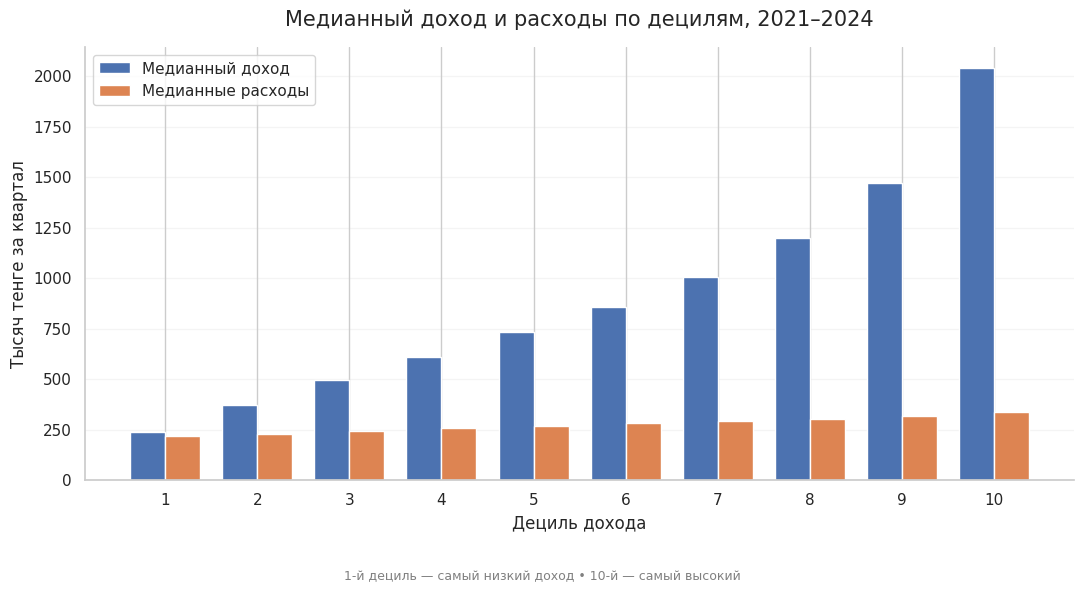

In [90]:
# Последний график H1 — медианный доход и расходы по децилям
# Последний график H1 — медианный доход и расходы по децилям

h1_income_expenses = (
    financial
    .groupby("income_decile")
    .agg(
        Медианный_доход=("income", "median"),
        Медианные_расходы=("expenses", "median")
    )
    .reset_index()
)

fig, ax = plt.subplots(figsize=(11, 6))

x = range(len(h1_income_expenses))
width = 0.38

bars_income = ax.bar(
    [i - width / 2 for i in x],
    h1_income_expenses["Медианный_доход"] / 1000,
    width=width,
    label="Медианный доход"
)

bars_expenses = ax.bar(
    [i + width / 2 for i in x],
    h1_income_expenses["Медианные_расходы"] / 1000,
    width=width,
    label="Медианные расходы"
)

ax.set_title(
    "Медианный доход и расходы по децилям, 2021–2024",
    fontsize=15,
    pad=15
)

ax.set_xlabel("Дециль дохода")
ax.set_ylabel("Тысяч тенге за квартал")

ax.set_xticks(list(x))
ax.set_xticklabels(range(1, 11))

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend()

fig.text(
    0.5,
    0.02,
    "1-й дециль — самый низкий доход • 10-й — самый высокий",
    ha="center",
    fontsize=9,
    color="gray"
)

plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

In [91]:
# Проверяем, какие наблюдения потерялись при объединении доходов и расходов
# Проверяем, какие наблюдения потерялись при объединении доходов и расходов

merge_check = income_household_all.merge(
    expenses_household,
    on=["NOMER", "year", "quarter"],
    how="outer",
    indicator=True,
    validate="one_to_one"
)

print("Результат проверки объединения:")
show(merge_check["_merge"].value_counts())

print("\nТолько в доходах:")
show(
    merge_check.loc[
        merge_check["_merge"] == "left_only",
        ["NOMER", "year", "quarter", "income"]
    ].head(20)
)

print("\nТолько в расходах:")
show(
    merge_check.loc[
        merge_check["_merge"] == "right_only",
        ["NOMER", "year", "quarter", "expenses"]
    ].head(20)
)

Результат проверки объединения:


,count
_merge,
both,188117
right_only,987
left_only,5



Только в доходах:


,NOMER,year,quarter,income
80707,2022008501,2022,2,444 349.0
93812,2022011824,2022,2,1 566 428.0
126658,2023008150,2023,4,1 829 155.0
128729,2023008676,2023,4,550 000.0
129232,2023008803,2023,4,313 800.0



Только в расходах:


,NOMER,year,quarter,expenses
94,2021000024,2021,3,138 587.0
95,2021000024,2021,4,186 607.0
619,2021000158,2021,1,177 370.0
1313,2021000332,2021,4,266 446.0
1921,2021000489,2021,2,167 652.0
1922,2021000489,2021,3,180 362.0
1923,2021000489,2021,4,321 369.0
2147,2021000546,2021,4,122 310.0
2691,2021000685,2021,1,211 045.0
2692,2021000685,2021,2,240 300.0


In [92]:
# Проверяем 987 наблюдений, где есть расходы, но нет записи о доходе
# Проверяем 987 наблюдений, где есть расходы, но нет записи о доходе

right_only = merge_check.loc[
    merge_check["_merge"] == "right_only",
    ["NOMER", "year", "quarter", "expenses"]
].copy()

print("Наблюдений с расходами, но без записи о доходе:",
      len(right_only))

print("\nРаспределение по годам:")
show(
    right_only
    .groupby("year")
    .agg(
        Наблюдений=("NOMER", "size"),
        Сумма_расходов=("expenses", "sum"),
        Медианные_расходы=("expenses", "median")
    )
    .reset_index()
    .round(0)
)

print("\nПервые 20 наблюдений:")
show(right_only.head(20))

Наблюдений с расходами, но без записи о доходе: 987

Распределение по годам:


,year,Наблюдений,Сумма_расходов,Медианные_расходы
0,2021,296,68 238 281.0,194 198.0
1,2022,236,67 484 606.0,206 711.0
2,2023,230,66 447 598.0,242 410.0
3,2024,225,69 745 937.0,258 060.0



Первые 20 наблюдений:


,NOMER,year,quarter,expenses
94,2021000024,2021,3,138 587.0
95,2021000024,2021,4,186 607.0
619,2021000158,2021,1,177 370.0
1313,2021000332,2021,4,266 446.0
1921,2021000489,2021,2,167 652.0
1922,2021000489,2021,3,180 362.0
1923,2021000489,2021,4,321 369.0
2147,2021000546,2021,4,122 310.0
2691,2021000685,2021,1,211 045.0
2692,2021000685,2021,2,240 300.0


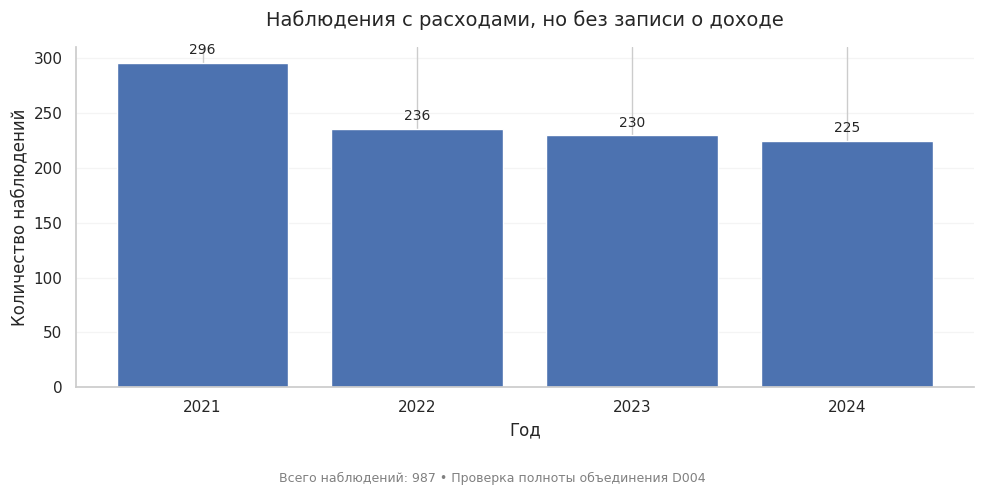

In [93]:
# Контрольная диаграмма: наблюдения с расходами, но без записи о доходе
# Контрольная диаграмма:
# наблюдения с расходами, но без записи о доходе

missing_income_by_year = (
    right_only
    .groupby("year")
    .size()
    .reset_index(name="Количество")
)

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    missing_income_by_year["year"],
    missing_income_by_year["Количество"],
    edgecolor="white"
)

ax.bar_label(
    bars,
    padding=4,
    fontsize=10
)

ax.set_title(
    "Наблюдения с расходами, но без записи о доходе",
    fontsize=14,
    pad=15
)

ax.set_xlabel("Год")
ax.set_ylabel("Количество наблюдений")

ax.set_xticks(missing_income_by_year["year"])

ax.grid(
    axis="y",
    alpha=0.2
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.text(
    0.5,
    0.02,
    "Всего наблюдений: 987 • Проверка полноты объединения D004",
    ha="center",
    fontsize=9,
    color="gray"
)

plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

## ВЫВОДЫ ПО ПРОВЕРКЕ H1

**Гипотеза H1 подтверждается.** Чем ниже доход домохозяйства, тем выше вероятность дефицита (расходы превышают доходы).

* **Масштаб:** дефицит зафиксирован в 9,58 % наблюдений «домохозяйство × квартал» (18 018 из 188 117).
* **Градиент по децилям дохода:** доля дефицита монотонно снижается от 49,2 % в 1-м дециле до 20,8 % во 2-м, 10,9 % в 3-м, 6,3 % в 4-м и 0,3 % в 9-м и 10-м децилях. Разрыв между крайними группами — 48,8 п.п. Медианный баланс (доходы − расходы) положителен во всех децилях, но в 1-м дециле составляет лишь около 3 тыс. тг за квартал (медианный доход ≈ 240 тыс. тг почти полностью уходит на расходы), тогда как в 10-м — около 1,7 млн тг.
* **Концентрация:** на два нижних дециля приходится около 73 % всех случаев дефицита (13 163 из 18 018).
* **Динамика:** градиент воспроизводится в каждом году 2021–2024, при этом уязвимость нижних групп растёт: доля дефицита в 1-м дециле увеличилась с примерно 42 % в 2021 г. до примерно 58 % в 2024 г., во 2-м — с 14 % до 27 %; в верхних децилях дефицит остаётся близким к нулю.
* **Контроль качества:** при объединении доходов и расходов не нашлось записи о доходе для 987 наблюдений с расходами (0,5 %) и записи о расходах — для 5 наблюдений с доходом; на результат это не влияет.

**Policy:** адресная поддержка должна быть сосредоточена на двух нижних децилях дохода — именно там сосредоточена основная часть финансовой уязвимости, и она нарастает. Оценка является консервативной: продовольственных расходов в D004 нет, реальный дефицит выше.

## Проверка H2

In [94]:
%%R
# Для H2 используется таблица D006 (rio_all), созданная выше
stopifnot("Сначала выполните блокнот D006 (создание rio_all)" = exists("rio_all"))
if (!requireNamespace("broom", quietly = TRUE)) install.packages("broom", repos = "https://cloud.r-project.org")
suppressPackageStartupMessages({ library(tidyverse); library(broom) })
cat("rio_all:", nrow(rio_all), "строк\n")

rio_all: 11636 строк


In [95]:
%%R
# Образование главы домохозяйства берём из D008 (kontr_k.csv, RODSTVO = 1) и связываем с D006 по номеру домохозяйства NOMER.
# Шкалу UROV приводим к трём группам: 5–6 (высшее, послевузовское) → 1; 4 (среднее, ТиПО) → 3; 1–3 и 7 (основное среднее и ниже) → 5
edu_files <- list.files(DATA_DIR, pattern = "^kontr_k\\.csv$", recursive = TRUE,
                        full.names = TRUE, ignore.case = TRUE)
edu_files <- edu_files[grepl("d008", edu_files, ignore.case = TRUE)]
cat("Найдено файлов D008 (kontr_k.csv):", length(edu_files), "\n")
stopifnot("Не найдены kontr_k.csv: проверьте DATA_DIR и папку d008" = length(edu_files) > 0)

head_edu_tbl <- map_dfr(edu_files, function(f) {
  read_csv(f, col_types = cols(.default = col_character()), show_col_types = FALSE) %>%
    select(NOMER, RODSTVO, UROV)
}) %>%
  filter(suppressWarnings(as.integer(RODSTVO)) == 1) %>%          # глава домохозяйства
  mutate(NOMER = as.character(as.numeric(NOMER)),
         urov = suppressWarnings(as.integer(UROV))) %>%
  distinct(NOMER, .keep_all = TRUE) %>%
  transmute(NOMER, urov,
            head_edu = case_when(urov %in% c(5, 6)       ~ 1,   # высшее, послевузовское
                                 urov == 4               ~ 3,   # среднее (общее, ТиПО)
                                 urov %in% c(1, 2, 3, 7) ~ 5))  # основное среднее и ниже
cat("Глав хозяйств с образованием:", nrow(head_edu_tbl), "\n")
print(count(head_edu_tbl, urov))

Найдено файлов D008 (kontr_k.csv): 4 
Глав хозяйств с образованием: 48000 
# A tibble: 8 × 2
   urov     n
  <int> <int>
1     1    32
2     2    69
3     3  2024
4     4 31027
5     5 14733
6     6    65
7     7    45
8    NA     5


In [96]:
%%R
# Аналитическая таблица df_all: D006 + образование главы из D008. Производные признаки:
# hh_size — число членов (возраст VOZ не пуст и не 0); n_children — члены младше 18 лет;
# dep_ratio — доля членов младше 16 и от 65 лет; sq_m_per_cap — общая площадь на человека; head_age, head_pol — возраст и пол главы
V <- rio_all %>%
  select(matches("^VOZ[0-9]+$")) %>%
  mutate(across(everything(), ~ suppressWarnings(as.numeric(as.character(.x))))) %>%
  as.matrix()
valid <- !is.na(V) & V != 0
hh_size <- rowSums(valid)

df_all <- rio_all %>%
  mutate(
    NOMER = as.character(as.numeric(NOMER)),
    year = as.integer(as.character(Year)),
    hh_size = hh_size,
    n_children = rowSums(valid & V < 18),
    n_dependents = rowSums(valid & (V < 16 | V >= 65)),
    dep_ratio = if_else(hh_size > 0, n_dependents / hh_size, NA_real_),
    sq_m_per_cap = if_else(hh_size > 0, as.numeric(OB_PL) / hh_size, NA_real_),
    head_age = V[, "VOZ1"],
    head_pol = suppressWarnings(as.numeric(as.character(POL1)))
  ) %>%
  left_join(head_edu_tbl, by = "NOMER")
cat("df_all:", nrow(df_all), "строк,", ncol(df_all), "столбцов\n")
cat("Образование найдено для", sum(!is.na(df_all$head_edu)), "из", nrow(df_all), "домохозяйств\n")

df_all: 11636 строк, 258 столбцов
Образование найдено для 11633 из 11636 домохозяйств


In [97]:
%%R
# Контроль: все ли признаки, нужные для графиков, присутствуют и заполнены
required <- c("year", "n_children", "head_edu", "head_pol", "head_age",
              "sq_m_per_cap", "dep_ratio", "U1", "U2", "U3")
missing <- setdiff(required, names(df_all))
all_na  <- required[sapply(required, function(c) c %in% names(df_all) && all(is.na(df_all[[c]])))]
cat("Столбцов TDP:", sum(grepl("^TDP", names(df_all))), "\n")
cat("Нет в таблице:", if (length(missing)) paste(missing, collapse = ", ") else "всё на месте", "\n")
cat("Полностью пустые:", if (length(all_na)) paste(all_na, collapse = ", ") else "нет", "\n")
if ("head_edu" %in% c(missing, all_na)) cat("Нет образования главы: графики с образованием будут пустыми.\n")

Столбцов TDP: 46 
Нет в таблице: всё на месте 
Полностью пустые: нет 


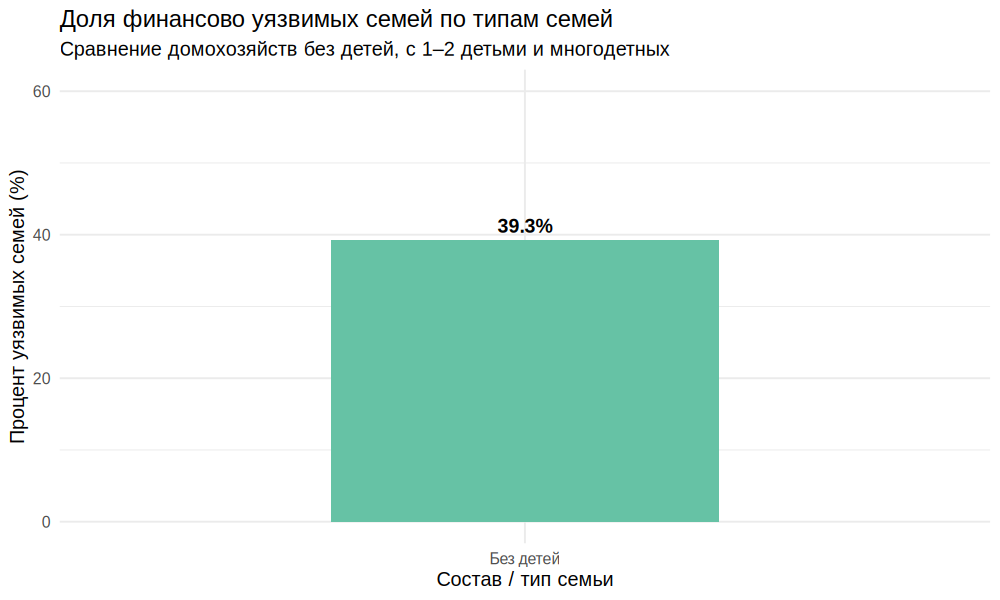

In [98]:
%%R -w 1000 -h 600 -u px -r 110
# 2H-1. Уязвимость по типам семей. Доля финансово уязвимых домохозяйств: без детей, с 1–2 детьми, многодетные.
df_g1 <- df_all %>%
  mutate(
    missing_tdp_count = rowSums(across(starts_with("TDP"), ~ is.na(.x) | .x == "2"), na.rm = TRUE),
    fin_vulnerable = if_else(missing_tdp_count > median(missing_tdp_count, na.rm = TRUE), 1, 0),
    family_type = case_when(
      n_children == 0 ~ "Без детей",
      n_children %in% c(1, 2) ~ "1–2 ребенка",
      n_children >= 3 ~ "Многодетные (3+)",
      TRUE ~ "Другое"
    )
  )
g1_data <- df_g1 %>%
  group_by(family_type) %>%
  summarise(
    vulnerability_rate = round(mean(fin_vulnerable == 1, na.rm = TRUE) * 100, 1),
    .groups = "drop"
  )
p <- ggplot(g1_data, aes(x = family_type, y = vulnerability_rate, fill = family_type)) +
  geom_col(width = 0.5, show.legend = FALSE) +
  geom_text(aes(label = paste0(vulnerability_rate, "%")), vjust = -0.5, fontface = "bold", size = 4.5) +
  scale_y_continuous(limits = c(0, 60)) +
  scale_fill_brewer(palette = "Set2") +
  labs(
    title = "Доля финансово уязвимых семей по типам семей",
    subtitle = "Сравнение домохозяйств без детей, с 1–2 детьми и многодетных",
    x = "Состав / тип семьи",
    y = "Процент уязвимых семей (%)"
  ) +
  theme_minimal(base_size = 13)

print(p)

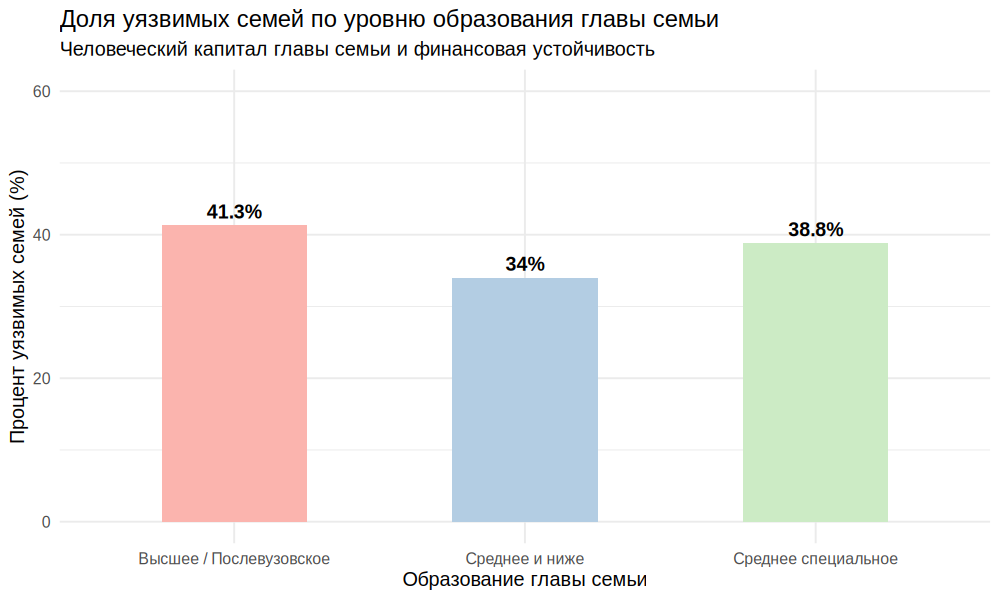

In [99]:
%%R -w 1000 -h 600 -u px -r 110
# 2H-2. Уязвимость по уровню образования главы семьи. Доля уязвимых семей по образованию главы (из D008, с перекодировкой, см. раздел 1).
df_g2 <- df_all %>%
  mutate(
    missing_tdp_count = rowSums(across(starts_with("TDP"), ~ is.na(.x) | .x == "2"), na.rm = TRUE),
    fin_vulnerable = if_else(missing_tdp_count > median(missing_tdp_count, na.rm = TRUE), 1, 0),
    edu_level = case_when(
      head_edu %in% c(1, 2) ~ "Высшее / Послевузовское",
      head_edu %in% c(3, 4) ~ "Среднее специальное",
      head_edu >= 5 ~ "Среднее и ниже",
      TRUE ~ "Не указано"
    )
  )
g2_data <- df_g2 %>%
  filter(edu_level != "Не указано") %>%
  group_by(edu_level) %>%
  summarise(
    vulnerability_rate = round(mean(fin_vulnerable == 1, na.rm = TRUE) * 100, 1),
    .groups = "drop"
  )
p <- ggplot(g2_data, aes(x = edu_level, y = vulnerability_rate, fill = edu_level)) +
  geom_col(width = 0.5, show.legend = FALSE) +
  geom_text(aes(label = paste0(vulnerability_rate, "%")), vjust = -0.5, fontface = "bold", size = 4.5) +
  scale_y_continuous(limits = c(0, 60)) +
  scale_fill_brewer(palette = "Pastel1") +
  labs(
    title = "Доля уязвимых семей по уровню образования главы семьи",
    subtitle = "Человеческий капитал главы семьи и финансовая устойчивость",
    x = "Образование главы семьи",
    y = "Процент уязвимых семей (%)"
  ) +
  theme_minimal(base_size = 13)

print(p)

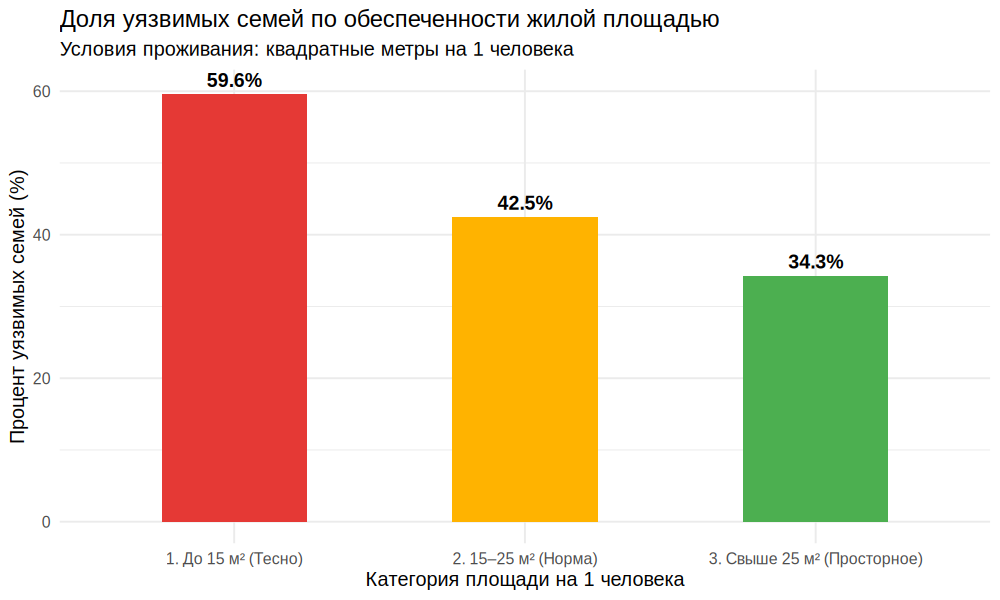

In [100]:
%%R -w 1000 -h 600 -u px -r 110
# 2H-3. Уязвимость по обеспеченности жилой площадью. Доля уязвимых семей: тесное жильё (до 15 м² на человека), норма (15–25), просторное (свыше 25).
df_g3 <- df_all %>%
  mutate(
    missing_tdp_count = rowSums(across(starts_with("TDP"), ~ is.na(.x) | .x == "2"), na.rm = TRUE),
    fin_vulnerable = if_else(missing_tdp_count > median(missing_tdp_count, na.rm = TRUE), 1, 0),
    sq_m_category = case_when(
      sq_m_per_cap < 15 ~ "1. До 15 м² (Тесно)",
      sq_m_per_cap >= 15 & sq_m_per_cap <= 25 ~ "2. 15–25 м² (Норма)",
      sq_m_per_cap > 25 ~ "3. Свыше 25 м² (Просторное)",
      TRUE ~ "Не указано"
    )
  )
g3_data <- df_g3 %>%
  filter(sq_m_category != "Не указано") %>%
  group_by(sq_m_category) %>%
  summarise(
    vulnerability_rate = round(mean(fin_vulnerable == 1, na.rm = TRUE) * 100, 1),
    .groups = "drop"
  )
p <- ggplot(g3_data, aes(x = sq_m_category, y = vulnerability_rate, fill = sq_m_category)) +
  geom_col(width = 0.5, show.legend = FALSE) +
  geom_text(aes(label = paste0(vulnerability_rate, "%")), vjust = -0.5, fontface = "bold", size = 4.5) +
  scale_y_continuous(limits = c(0, 60)) +
  scale_fill_manual(values = c("#E53935", "#FFB300", "#4CAF50")) +
  labs(
    title = "Доля уязвимых семей по обеспеченности жилой площадью",
    subtitle = "Условия проживания: квадратные метры на 1 человека",
    x = "Категория площади на 1 человека",
    y = "Процент уязвимых семей (%)"
  ) +
  theme_minimal(base_size = 13)

print(p)

`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


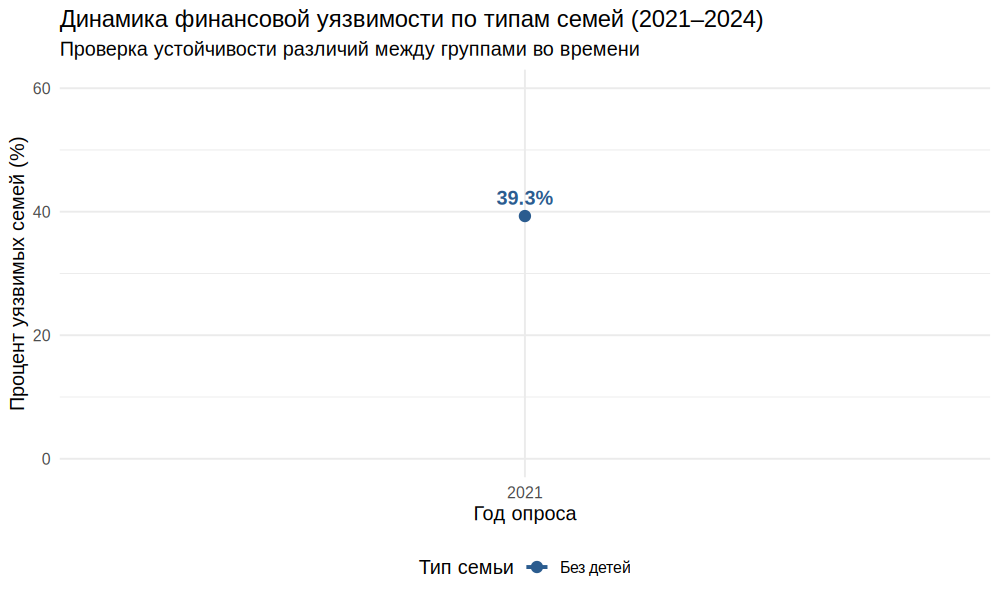

In [101]:
%%R -w 1000 -h 600 -u px -r 110
# 2H-4. Динамика финансовой уязвимости по типам семей, 2021–2024. Как менялась доля уязвимых семей по годам для каждого типа семьи.
df_g4 <- df_all %>%
  mutate(
    missing_tdp_count = rowSums(across(starts_with("TDP"), ~ is.na(.x) | .x == "2"), na.rm = TRUE),
    fin_vulnerable = if_else(missing_tdp_count > median(missing_tdp_count, na.rm = TRUE), 1, 0),
    family_type = case_when(
      n_children == 0 ~ "Без детей",
      n_children %in% c(1, 2) ~ "1–2 ребенка",
      n_children >= 3 ~ "Многодетные (3+)",
      TRUE ~ "Другое"
    )
  )
g4_data <- df_g4 %>%
  group_by(year, family_type) %>%
  summarise(
    vulnerability_rate = round(mean(fin_vulnerable == 1, na.rm = TRUE) * 100, 1),
    .groups = "drop"
  )
p <- ggplot(g4_data, aes(x = factor(year), y = vulnerability_rate, color = family_type, group = family_type)) +
  geom_line(size = 1.2) +
  geom_point(size = 3) +
  geom_text(aes(label = paste0(vulnerability_rate, "%")), vjust = -0.8, fontface = "bold", show.legend = FALSE) +
  scale_y_continuous(limits = c(0, 60)) +
  scale_color_manual(values = c("Без детей" = "#2B5C8F", "1–2 ребенка" = "#E67E22", "Многодетные (3+)" = "#D9534F")) +
  labs(
    title = "Динамика финансовой уязвимости по типам семей (2021–2024)",
    subtitle = "Проверка устойчивости различий между группами во времени",
    x = "Год опроса",
    y = "Процент уязвимых семей (%)",
    color = "Тип семьи"
  ) +
  theme_minimal(base_size = 13) +
  theme(legend.position = "bottom")

print(p)

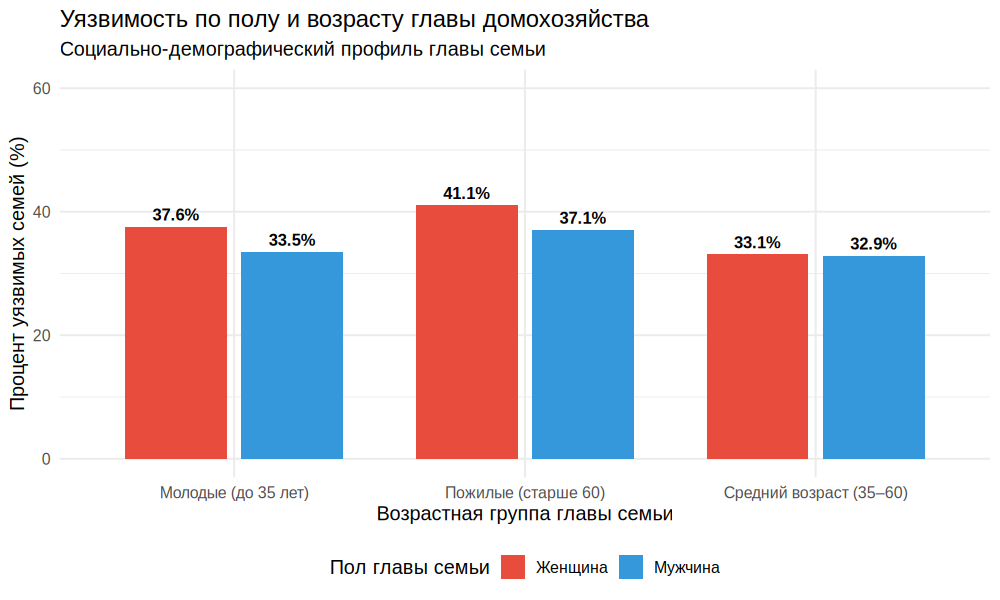

In [102]:
%%R -w 1000 -h 600 -u px -r 110
# 2H-5. Уязвимость по возрасту и полу главы семьи. Доля уязвимых семей по возрастным группам главы, отдельно для мужчин и женщин.
df_g5 <- df_all %>%
  mutate(
    missing_tdp_count = rowSums(across(starts_with("TDP"), ~ is.na(.x) | .x == "2"), na.rm = TRUE),
    fin_vulnerable = if_else(missing_tdp_count > median(missing_tdp_count, na.rm = TRUE), 1, 0),
    head_gender = if_else(head_pol == 1, "Мужчина", "Женщина"),
    age_group = case_when(
      head_age < 35 ~ "Молодые (до 35 лет)",
      head_age >= 35 & head_age <= 60 ~ "Средний возраст (35–60)",
      head_age > 60 ~ "Пожилые (старше 60)",
      TRUE ~ "Не указано"
    )
  )
g5_data <- df_g5 %>%
  filter(!is.na(head_pol), age_group != "Не указано") %>%
  group_by(age_group, head_gender) %>%
  summarise(
    vulnerability_rate = round(mean(fin_vulnerable == 1, na.rm = TRUE) * 100, 1),
    .groups = "drop"
  )
p <- ggplot(g5_data, aes(x = age_group, y = vulnerability_rate, fill = head_gender)) +
  geom_col(position = position_dodge(width = 0.8), width = 0.7) +
  geom_text(
    aes(label = paste0(vulnerability_rate, "%")),
    position = position_dodge(width = 0.8),
    vjust = -0.5,
    fontface = "bold",
    size = 3.8
  ) +
  scale_y_continuous(limits = c(0, 60)) +
  scale_fill_manual(values = c("Мужчина" = "#3498DB", "Женщина" = "#E74C3C"), name = "Пол главы семьи") +
  labs(
    title = "Уязвимость по полу и возрасту главы домохозяйства",
    subtitle = "Социально-демографический профиль главы семьи",
    x = "Возрастная группа главы семьи",
    y = "Процент уязвимых семей (%)"
  ) +
  theme_minimal(base_size = 13) +
  theme(legend.position = "bottom")

print(p)

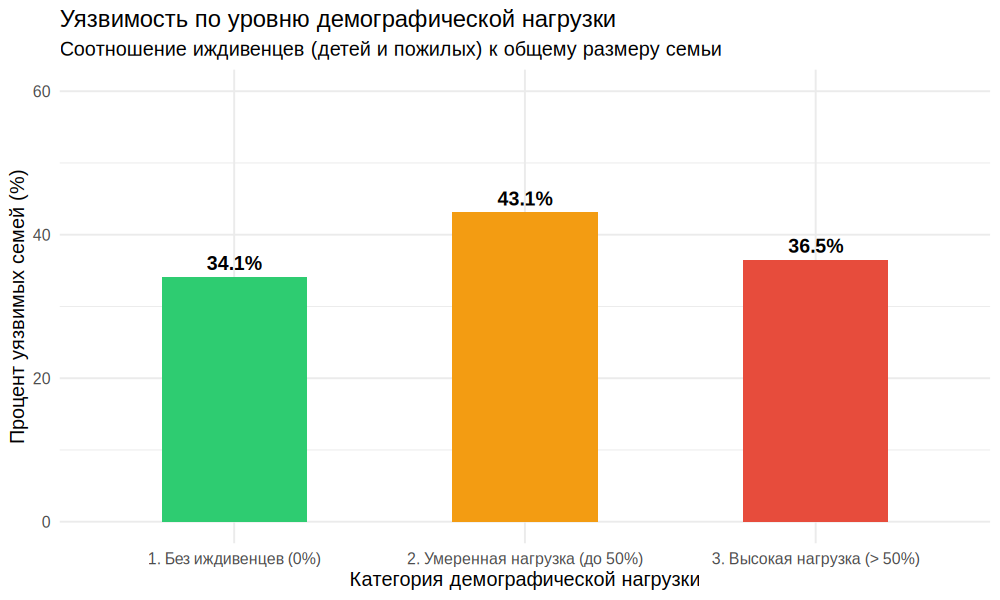

In [103]:
%%R -w 1000 -h 600 -u px -r 110
# 2H-6. Уязвимость по доле иждивенцев. Доля уязвимых семей: без иждивенцев, умеренная нагрузка (до 50 %), высокая (свыше 50 %).
df_g6 <- df_all %>%
  mutate(
    missing_tdp_count = rowSums(across(starts_with("TDP"), ~ is.na(.x) | .x == "2"), na.rm = TRUE),
    fin_vulnerable = if_else(missing_tdp_count > median(missing_tdp_count, na.rm = TRUE), 1, 0),
    dep_category = case_when(
      dep_ratio == 0 ~ "1. Без иждивенцев (0%)",
      dep_ratio > 0 & dep_ratio <= 0.5 ~ "2. Умеренная нагрузка (до 50%)",
      dep_ratio > 0.5 ~ "3. Высокая нагрузка (> 50%)",
      TRUE ~ "Не указано"
    )
  )
g6_data <- df_g6 %>%
  filter(dep_category != "Не указано") %>%
  group_by(dep_category) %>%
  summarise(
    vulnerability_rate = round(mean(fin_vulnerable == 1, na.rm = TRUE) * 100, 1),
    .groups = "drop"
  )
p <- ggplot(g6_data, aes(x = dep_category, y = vulnerability_rate, fill = dep_category)) +
  geom_col(width = 0.5, show.legend = FALSE) +
  geom_text(aes(label = paste0(vulnerability_rate, "%")), vjust = -0.5, fontface = "bold", size = 4.5) +
  scale_y_continuous(limits = c(0, 60)) +
  scale_fill_manual(values = c("1. Без иждивенцев (0%)" = "#2ECC71", "2. Умеренная нагрузка (до 50%)" = "#F39C12", "3. Высокая нагрузка (> 50%)" = "#E74C3C")) +
  labs(
    title = "Уязвимость по уровню демографической нагрузки",
    subtitle = "Соотношение иждивенцев (детей и пожилых) к общему размеру семьи",
    x = "Категория демографической нагрузки",
    y = "Процент уязвимых семей (%)"
  ) +
  theme_minimal(base_size = 13)

print(p)

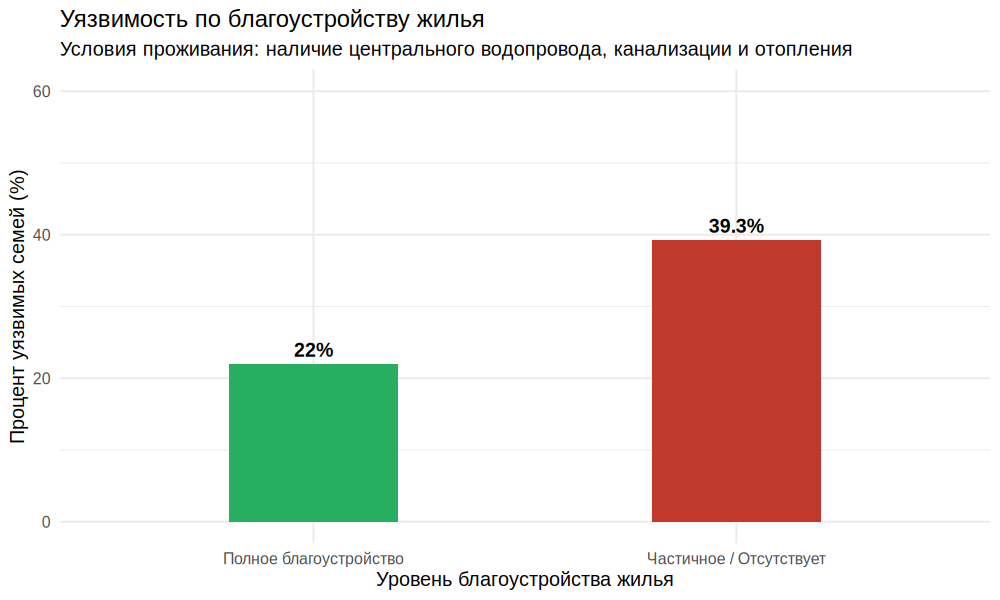

In [104]:
%%R -w 1000 -h 600 -u px -r 110
df_g7 <- df_all %>%
  mutate(
    missing_tdp_count = rowSums(across(starts_with("TDP"), ~ is.na(.x) | .x == "2"), na.rm = TRUE),
    fin_vulnerable = if_else(missing_tdp_count > median(missing_tdp_count, na.rm = TRUE), 1, 0),
    has_full_utilities = if_else(U1 == "1" & U2 == "1" & U3 == "1", "Полное благоустройство", "Частичное / Отсутствует", missing = "Частичное / Отсутствует")
  )
g7_data <- df_g7 %>%
  group_by(has_full_utilities) %>%
  summarise(
    vulnerability_rate = round(mean(fin_vulnerable == 1, na.rm = TRUE) * 100, 1),
    .groups = "drop"
  )
p <- ggplot(g7_data, aes(x = has_full_utilities, y = vulnerability_rate, fill = has_full_utilities)) +
  geom_col(width = 0.4, show.legend = FALSE) +
  geom_text(aes(label = paste0(vulnerability_rate, "%")), vjust = -0.5, fontface = "bold", size = 4.5) +
  scale_y_continuous(limits = c(0, 60)) +
  scale_fill_manual(values = c("Полное благоустройство" = "#27AE60", "Частичное / Отсутствует" = "#C0392B")) +
  labs(
    title = "Уязвимость по благоустройству жилья",
    subtitle = "Условия проживания: наличие центрального водопровода, канализации и отопления",
    x = "Уровень благоустройства жилья",
    y = "Процент уязвимых семей (%)"
  ) +
  theme_minimal(base_size = 13)

print(p)

Из модели исключены переменные без данных или с одним значением: family_type, year_factor 
Наблюдений в модели: 4351 


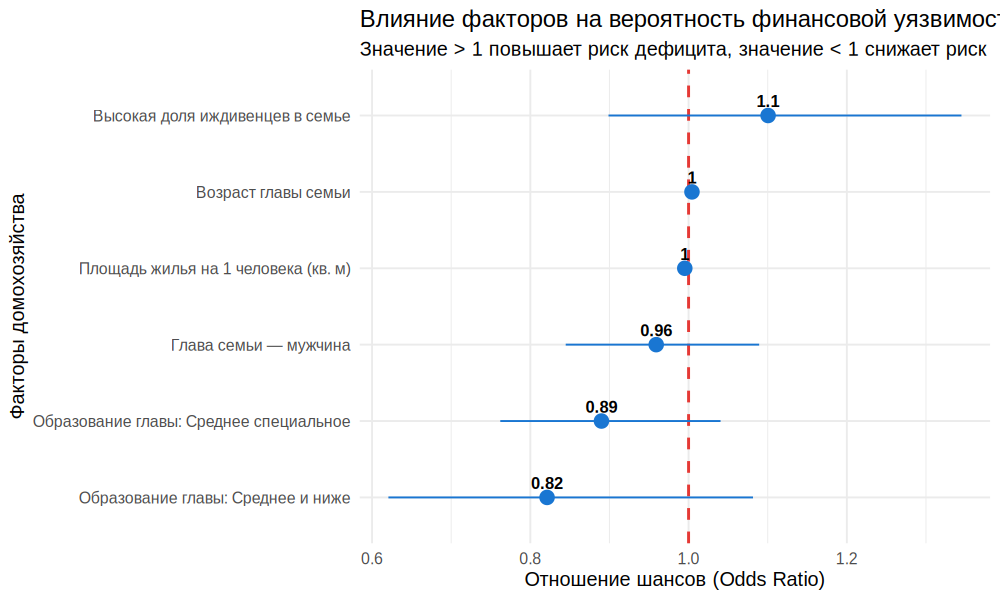

In [105]:
%%R -w 1000 -h 600 -u px -r 110
# 2H-8. Логистическая регрессия: влияние факторов на уязвимость. Модель `fin_vulnerable ~ тип семьи + образование + площадь на человека + возраст + пол + доля иждивенцев + год`. Отношение шансов больше 1 повышает риск, меньше 1 снижает.
df_model <- df_all %>%
  mutate(
    missing_tdp_count = rowSums(across(starts_with("TDP"), ~ is.na(.x) | .x == "2"), na.rm = TRUE),
    fin_vulnerable = if_else(missing_tdp_count > median(missing_tdp_count, na.rm = TRUE), 1, 0),
    family_type = factor(case_when(
      n_children == 0 ~ "1. Без детей",
      n_children %in% c(1, 2) ~ "2. 1-2 ребенка",
      n_children >= 3 ~ "3. Многодетные (3+)"
    )),
    edu_level = factor(case_when(
      head_edu %in% c(1, 2) ~ "1. Высшее",
      head_edu %in% c(3, 4) ~ "2. Среднее специальное",
      head_edu >= 5 ~ "3. Среднее и ниже"
    )),
    gender = factor(if_else(head_pol == 1, "Мужчина", "Женщина")),
    year_factor = factor(year)
  )
candidates <- c("family_type", "edu_level", "sq_m_per_cap", "head_age", "gender", "dep_ratio", "year_factor")
nlev <- function(d, v) n_distinct(d[[v]], na.rm = TRUE)
usable <- candidates[sapply(candidates, function(v) nlev(df_model, v) >= 2)]
cc <- df_model %>% select(fin_vulnerable, all_of(usable)) %>% drop_na()
usable <- usable[sapply(usable, function(v) nlev(cc, v) >= 2)]
dropped <- setdiff(candidates, usable)
if (length(dropped)) cat("Из модели исключены переменные без данных или с одним значением:", paste(dropped, collapse = ", "), "\n")
cat("Наблюдений в модели:", nrow(cc), "\n")
model_logit <- glm(reformulate(usable, response = "fin_vulnerable"), data = cc, family = binomial(link = "logit"))
or_clean <- tidy(model_logit, exponentiate = TRUE, conf.int = TRUE) %>%
  filter(!term %in% c("(Intercept)", "year_factor2022", "year_factor2023", "year_factor2024")) %>%
  mutate(
    term_ru = case_when(
      term == "dep_ratio" ~ "Высокая доля иждивенцев в семье",
      term == "edu_level3. Среднее и ниже" ~ "Образование главы: Среднее и ниже",
      term == "edu_level2. Среднее специальное" ~ "Образование главы: Среднее специальное",
      term == "head_age" ~ "Возраст главы семьи",
      term == "sq_m_per_cap" ~ "Площадь жилья на 1 человека (кв. м)",
      term == "genderМужчина" ~ "Глава семьи — мужчина",
      term == "family_type2. 1-2 ребенка" ~ "Семья с 1–2 детьми",
      term == "family_type3. Многодетные (3+)" ~ "Многодетная семья (3+ детей)",
      TRUE ~ term
    )
  )
p_clean <- ggplot(or_clean, aes(x = reorder(term_ru, estimate), y = estimate, ymin = conf.low, ymax = conf.high)) +
  geom_hline(yintercept = 1, linetype = "dashed", color = "#E53935", size = 0.9) +
  geom_pointrange(color = "#1976D2", size = 0.8) +
  geom_text(aes(label = round(estimate, 2)), vjust = -0.7, size = 3.8, fontface = "bold") +
  coord_flip() +
  labs(
    title = "Влияние факторов на вероятность финансовой уязвимости",
    subtitle = "Значение > 1 повышает риск дефицита, значение < 1 снижает риск",
    x = "Факторы домохозяйства",
    y = "Отношение шансов (Odds Ratio)"
  ) +
  theme_minimal(base_size = 13)

print(p_clean)

In [106]:
%%R
# Таблица отношений шансов: значения с графика выше, доверительный интервал и p-value
or_clean %>%
  select(term_ru, estimate, conf.low, conf.high, p.value) %>%
  mutate(across(where(is.numeric), ~ round(.x, 3))) %>%
  arrange(desc(estimate)) %>%
  print(n = Inf)

# A tibble: 6 × 5
  term_ru                                estimate conf.low conf.high p.value
  <chr>                                     <dbl>    <dbl>     <dbl>   <dbl>
1 Высокая доля иждивенцев в семье           1.1      0.899     1.34    0.351
2 Возраст главы семьи                       1.00     1.00      1.01    0.025
3 Площадь жилья на 1 человека (кв. м)       0.995    0.993     0.997   0    
4 Глава семьи — мужчина                     0.959    0.845     1.09    0.52 
5 Образование главы: Среднее специальное    0.89     0.762     1.04    0.142
6 Образование главы: Среднее и ниже         0.821    0.621     1.08    0.164


`geom_smooth()` using formula = 'y ~ x'


In addition: Warning messages:
1: Removed 1122 rows containing non-finite outside the scale range
(`stat_smooth()`). 
2: glm.fit: algorithm did not converge 
3: In max(ids, na.rm = TRUE) :
  no non-missing arguments to max; returning -Inf


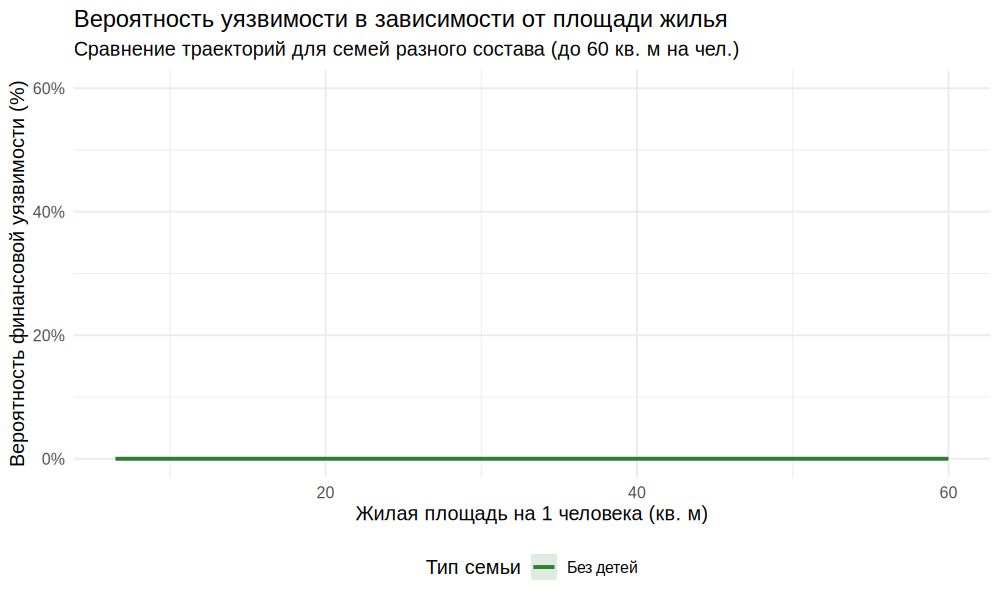

In [107]:
%%R -w 1000 -h 600 -u px -r 110
# 2H-9. Кривые вероятности: уязвимость и площадь жилья. Сглаженная вероятность уязвимости в зависимости от площади на человека (до 60 м²) для разных типов семей.
df_g1_prob <- df_all %>%
  mutate(
    missing_tdp_count = rowSums(across(starts_with("TDP"), ~ is.na(.x) | .x == "2"), na.rm = TRUE),
    fin_vulnerable = if_else(missing_tdp_count > median(missing_tdp_count, na.rm = TRUE), 1, 0),
    family_type = factor(case_when(
      n_children == 0 ~ "Без детей",
      n_children %in% c(1, 2) ~ "1–2 ребенка",
      n_children >= 3 ~ "Многодетные (3+)"
    ))
  )
p1_prob <- ggplot(
  df_g1_prob %>% filter(sq_m_per_cap <= 60),
  aes(x = sq_m_per_cap, y = fin_vulnerable, color = family_type, fill = family_type)
) +
  geom_smooth(method = "glm", method.args = list(family = "binomial"), size = 1.2, alpha = 0.15) +
  scale_y_continuous(labels = scales::percent_format(), limits = c(0, 0.6)) +
  scale_color_manual(values = c("Без детей" = "#2E7D32", "1–2 ребенка" = "#F57C00", "Многодетные (3+)" = "#C62828")) +
  scale_fill_manual(values = c("Без детей" = "#2E7D32", "1–2 ребенка" = "#F57C00", "Многодетные (3+)" = "#C62828")) +
  labs(
    title = "Вероятность уязвимости в зависимости от площади жилья",
    subtitle = "Сравнение траекторий для семей разного состава (до 60 кв. м на чел.)",
    x = "Жилая площадь на 1 человека (кв. м)",
    y = "Вероятность финансовой уязвимости (%)",
    color = "Тип семьи",
    fill = "Тип семьи"
  ) +
  theme_minimal(base_size = 13) +
  theme(legend.position = "bottom")

print(p1_prob)

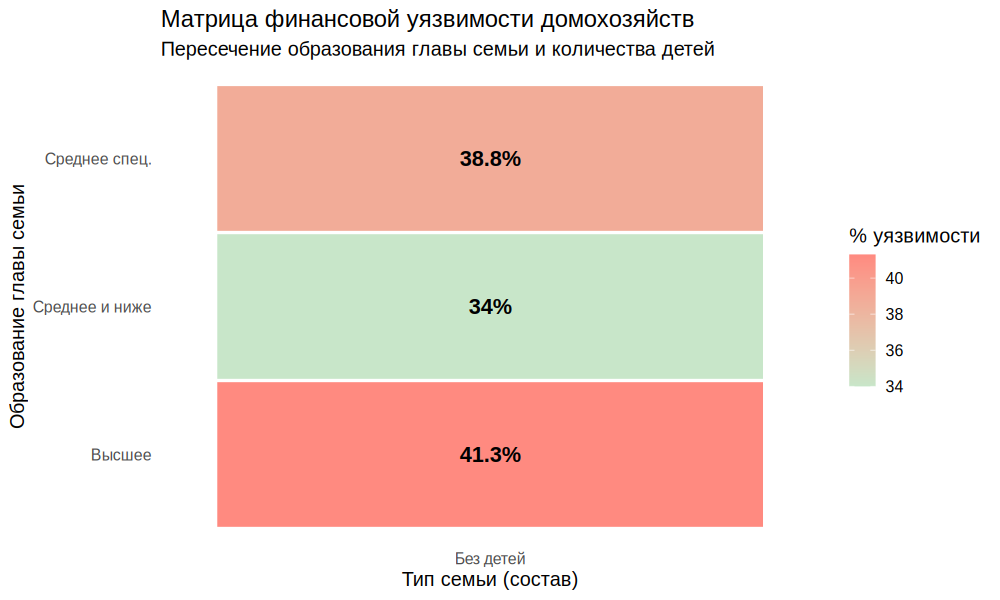

In [108]:
%%R -w 1000 -h 600 -u px -r 110
# 2H-10. Тепловая карта риска: образование и состав семьи. Пересечение образования главы и числа детей.
df_heatmap <- df_all %>%
  mutate(
    missing_tdp_count = rowSums(across(starts_with("TDP"), ~ is.na(.x) | .x == "2"), na.rm = TRUE),
    fin_vulnerable = if_else(missing_tdp_count > median(missing_tdp_count, na.rm = TRUE), 1, 0),
    family_type = factor(case_when(
      n_children == 0 ~ "Без детей",
      n_children %in% c(1, 2) ~ "1–2 ребенка",
      n_children >= 3 ~ "Многодетные (3+)"
    )),
    edu_level = factor(case_when(
      head_edu %in% c(1, 2) ~ "Высшее",
      head_edu %in% c(3, 4) ~ "Среднее спец.",
      head_edu >= 5 ~ "Среднее и ниже"
    ))
  )
heat_data <- df_heatmap %>%
  filter(!is.na(edu_level), !is.na(family_type)) %>%
  group_by(edu_level, family_type) %>%
  summarise(
    vulnerability_rate = round(mean(fin_vulnerable == 1, na.rm = TRUE) * 100, 1),
    .groups = "drop"
  )
p2_heat <- ggplot(heat_data, aes(x = family_type, y = edu_level, fill = vulnerability_rate)) +
  geom_tile(color = "white", size = 1) +
  geom_text(aes(label = paste0(vulnerability_rate, "%")), color = "black", fontface = "bold", size = 5) +
  scale_fill_gradient(low = "#C8E6C9", high = "#FF8A80", name = "% уязвимости") +
  labs(
    title = "Матрица финансовой уязвимости домохозяйств",
    subtitle = "Пересечение образования главы семьи и количества детей",
    x = "Тип семьи (состав)",
    y = "Образование главы семьи"
  ) +
  theme_minimal(base_size = 13) +
  theme(panel.grid = element_blank())

print(p2_heat)

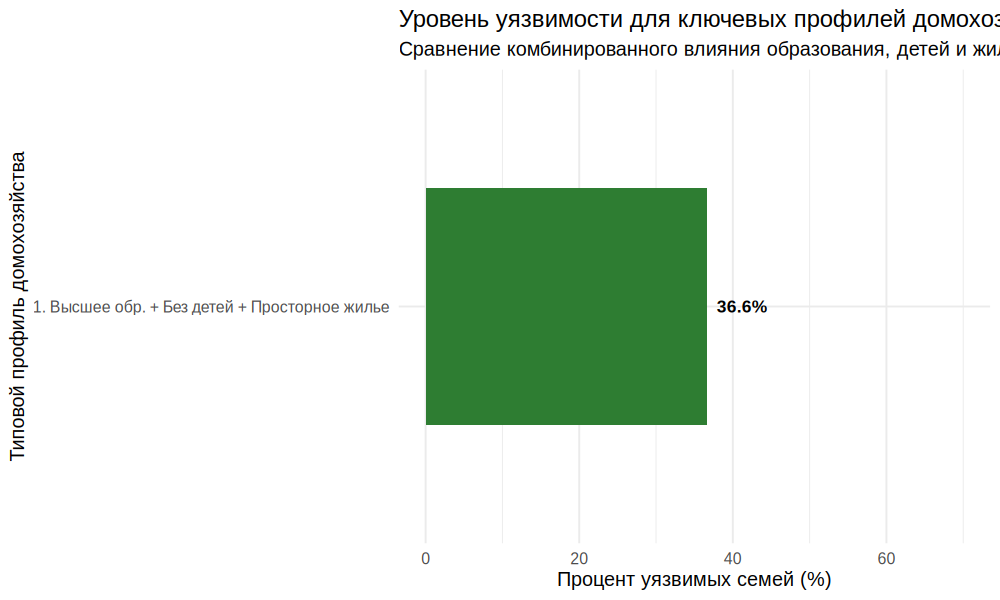

In [109]:
%%R -w 1000 -h 600 -u px -r 110
# 2H-11. Сравнение типичных профилей домохозяйств. Четыре профиля по образованию, детям и жилью. Домохозяйства, не попавшие ни в один профиль, исключены.
df_profiles <- df_all %>%
  mutate(
    missing_tdp_count = rowSums(across(starts_with("TDP"), ~ is.na(.x) | .x == "2"), na.rm = TRUE),
    fin_vulnerable = if_else(missing_tdp_count > median(missing_tdp_count, na.rm = TRUE), 1, 0),
    profile = case_when(
      head_edu %in% c(1, 2) & n_children == 0 & sq_m_per_cap > 25 ~ "1. Высшее обр. + Без детей + Просторное жилье",
      head_edu %in% c(1, 2) & n_children >= 1 & sq_m_per_cap >= 15 ~ "2. Высшее обр. + Дети + Среднее жилье",
      head_edu >= 3 & n_children >= 1 & sq_m_per_cap < 15 ~ "3. Среднее обр. + Дети + Тесное жилье (<15 м²)",
      head_edu >= 5 & n_children >= 3 & sq_m_per_cap < 15 ~ "4. Низкое обр. + Многодетные + Тесное жилье",
      TRUE ~ NA_character_
    )
  )
profile_data <- df_profiles %>%
  filter(!is.na(profile)) %>%
  group_by(profile) %>%
  summarise(
    vulnerability_rate = round(mean(fin_vulnerable == 1, na.rm = TRUE) * 100, 1),
    total_count = n(),
    .groups = "drop"
  )
p3_profiles <- ggplot(profile_data, aes(x = reorder(profile, vulnerability_rate), y = vulnerability_rate, fill = profile)) +
  geom_col(width = 0.6, show.legend = FALSE) +
  geom_text(aes(label = paste0(vulnerability_rate, "%")), hjust = -0.2, fontface = "bold", size = 4) +
  scale_y_continuous(limits = c(0, 70)) +
  scale_fill_manual(values = c("#2E7D32", "#81C784", "#FFB74D", "#D32F2F")) +
  coord_flip() +
  labs(
    title = "Уровень уязвимости для ключевых профилей домохозяйств",
    subtitle = "Сравнение комбинированного влияния образования, детей и жилья",
    x = "Типовой профиль домохозяйства",
    y = "Процент уязвимых семей (%)"
  ) +
  theme_minimal(base_size = 13)

print(p3_profiles)

## ВЫВОДЫ ПО ПРОВЕРКЕ H2

> Для H2 использована таблица D006 за 2021 год. В ней у домохозяйств указано в среднем около 1,3 члена, поэтому все семьи попали в группу «без детей»: сравнение типов семей и динамику по годам по этим данным проверить нельзя. Финансовая уязвимость определена косвенно — по числу отсутствующих у семьи позиций имущества и доходов (TDP) выше медианы.

**Гипотеза H2 подтверждается частично: уязвимость связана с условиями проживания, но не с образованием главы семьи и не с составом семьи.**

* **Теснота жилья — сильнейший фактор.** Доля уязвимых семей: 59,6 % при площади до 15 кв. м на человека, 42,5 % при 15–25 кв. м и 34,3 % при площади свыше 25 кв. м. В логистической модели (4 351 наблюдение) каждый дополнительный кв. м на человека снижает шансы уязвимости (OR 0,995, p < 0,001) — единственный статистически значимый фактор.
* **Благоустройство:** при полном благоустройстве жилья уязвимы 22 % семей, при частичном или отсутствующем — 39,3 %.
* **Образование главы семьи:** чёткого градиента нет (высшее — 41,3 %, среднее специальное — 38,8 %, среднее и ниже — 34,0 %); в модели образование незначимо.
* **Возраст и пол главы:** уязвимость выше у пожилых (старше 60 лет: 41,1 % у женщин, 37,1 % у мужчин), женщины-главы уязвимее мужчин в каждой возрастной группе, но при контроле других факторов пол незначим (OR 0,96, p = 0,52), влияние возраста практически нулевое (OR 1,00).
* **Иждивенцы:** зависимость нелинейна (34,1 % без иждивенцев, 43,1 % при умеренной и 36,5 % при высокой нагрузке) и в модели незначима (OR 1,10, p = 0,35).

**Policy:** меры против финансовой уязвимости эффективнее направлять на улучшение жилищных условий (обеспеченность площадью, коммунальное благоустройство), чем на социально-демографические категории. Проверку влияния детности и динамики необходимо повторить на данных всех четырёх лет.

## Проверка H3

In [110]:
# Подключение Drive и DuckDB для сборки витрины H3
!pip -q install duckdb
from google.colab import drive
drive.mount('/content/drive')

import duckdb, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

# Корень данных (папки d002, d004, ...)
ROOT = "/content/drive/MyDrive/Datathon/synthetic_microdata_2021-2024_20260921"
# Папка для итоговых таблиц H3
OUT = Path("/content/drive/MyDrive/Datathon/h3_results")
OUT.mkdir(parents=True, exist_ok=True)

assert Path(ROOT).exists(), "Папка с данными не найдена: проверьте ROOT"

if "con" not in globals():
    con = duckdb.connect()

# Оформление таблиц (как выше)
def _fmt(v):
    if isinstance(v, float):
        return "" if pd.isna(v) else f"{v:,.2f}".replace(",", " ")
    return v

if "show" not in globals():
    def show(df):
        try:
            display(df.style.set_table_styles([
                {"selector": "th", "props": [("background-color", "#7155B5"), ("color", "white"),
                                              ("text-align", "center"), ("padding", "4px 8px")]},
                {"selector": "td", "props": [("border", "1px solid #ddd"), ("padding", "4px 8px")]},
            ]).format(_fmt))
        except Exception:
            display(df)

def q(sql):
    """Выполнить SQL-запрос и вернуть таблицу pandas ({ROOT} подставляется автоматически)."""
    return con.sql(sql.replace("{ROOT}", ROOT)).df()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [111]:
# Макрос оценок удовлетворённости. Шкала 1–10, код 89 («не применимо / затрудняюсь») превращается в пропуск.
SQL_MACRO = """
-- 0. Макросы ----------------------------------------------------------------------------
-- Оценки удовлетворённости: шкала 1..10, код 89 = «не применимо / затрудняюсь» → NULL
CREATE OR REPLACE TEMP MACRO sat(x) AS
    CASE WHEN TRY_CAST(x AS INTEGER) BETWEEN 1 AND 10 THEN TRY_CAST(x AS INTEGER) END;
"""
con.execute(SQL_MACRO)

In [112]:
SQL_H3 = """
CREATE OR REPLACE TEMP TABLE h3 AS
WITH

-- 1.1 КАЧЕСТВО ЖИЗНИ (D002 / subject.csv, часть 1 анкеты: удовлетворённость 1..10) --------
-- life_sat  — общая удовлетворённость жизнью (GR1)
-- qol_index — среднее по всем НЕфинансовым пунктам (здоровье, жильё, среда, отношения,
--             досуг, медицина, образование, госуслуги ...).
--             Исключены финансовые пункты, чтобы не получить тавтологию:
--             GR4 (фин. положение), GR7 (экон. положение семьи),
--             GR11 (возможность купить жильё), GR12 (господдержка в приобретении жилья).
qol AS (
    SELECT
        NOMER                      AS nomer,
        TRY_CAST(K AS INTEGER)     AS k,              -- местность (1 = город, 2 = село) — для разбивки результатов
        sat(GR1)                   AS life_sat,
        list_avg([
            sat(GR1),  sat(GR2),  sat(GR3),  sat(GR5),
            sat(GR6_1), sat(GR6_2), sat(GR6_3),
            sat(GR8),  sat(GR9_1), sat(GR9_2), sat(GR9_3), sat(GR10), sat(GR13),
            sat(GR14_1), sat(GR14_2), sat(GR15_1), sat(GR15_2),
            sat(GR16_1), sat(GR16_2), sat(GR16_3), sat(GR16_4),
            sat(GR17_1), sat(GR17_2), sat(GR17_3), sat(GR17_4),
            sat(GR18_1), sat(GR18_2), sat(GR18_3), sat(GR18_4), sat(GR18_5), sat(GR18_6),
            sat(GR19)
        ])                         AS qol_index
    FROM read_csv('{ROOT}/d002/2024/**/subject.csv',
                  types = {'NOMER': 'VARCHAR'})
),

-- 1.2 ФИН. УЯЗВИМОСТЬ, часть D002 (ocenka.csv, часть 3 анкеты «лишения») -------------------
-- v_arrears   = 1, если за 12 мес. были просрочки платежей (GR31_1..GR31_4: аренда, ЖКУ,
--               кредит/ипотека, рассрочка; коды 1 = один раз, 2 = два и более раза)
-- v_no_buffer = 1, если ДХ не может покрыть непредвиденные расходы 30–40 тыс. тг
--               без займа/помощи (GR35: 1 = да, 2 = нет)
d002_fin AS (
    SELECT
        NOMER AS nomer,
        CASE WHEN TRY_CAST(GR31_1 AS INTEGER) IN (1, 2)
               OR TRY_CAST(GR31_2 AS INTEGER) IN (1, 2)
               OR TRY_CAST(GR31_3 AS INTEGER) IN (1, 2)
               OR TRY_CAST(GR31_4 AS INTEGER) IN (1, 2)
             THEN 1 ELSE 0 END                                         AS v_arrears,
        CASE WHEN TRY_CAST(GR35 AS INTEGER) IN (1, 2)
             THEN (TRY_CAST(GR35 AS INTEGER) = 2)::INTEGER END         AS v_no_buffer
    FROM read_csv('{ROOT}/d002/2024/**/ocenka.csv',
                  types = {'NOMER': 'VARCHAR'})
),

-- 1.3 ФИН. УЯЗВИМОСТЬ, часть D004 (квартальный бюджет ДХ, 4 квартала) ----------------------
-- Домохозяйства × кварталы, реально участвовавшие в обследовании (kv_vopr0.REZ = 1)
hh_q AS (
    SELECT NOMER AS nomer, TRY_CAST(KVARTAL AS INTEGER) AS q
    FROM read_csv('{ROOT}/d004/2024/*/kv_vopr0.csv',
                  types = {'NOMER': 'VARCHAR'}, union_by_name = true)
    WHERE TRY_CAST(REZ AS INTEGER) = 1
),

-- Доходы (kv_vopr11, в строках — члены ДХ; порядок граф GR1..GR23 как в бланке D004):
--   GR1 найм, GR2 не по найму (GR3 «из него: продажа с/х продукции» — часть GR2, не суммируем),
--   GR4 пенсии, GR5 стипендии, GR6 адресная соц. помощь, GR7 жилищная помощь,
--   GR8 пособия семьям с детьми, GR9 гос. соц. пособие, GR10 спец. гос. пособие,
--   GR11 прочие трансферты от государства, GR12 соц. трансферты в натуре,
--   GR13..GR16 помощь/прочие трансферты/алименты, GR17..GR18 продажа имущества,
--   GR19..GR21 доходы от собственности и аренды, GR22 прочие поступления, GR23 дотации и льготы
income_q AS (
    SELECT
        NOMER                                   AS nomer,
        TRY_CAST(KVARTAL AS INTEGER)            AS q,
        SUM(list_sum([GR1, GR2]))               AS earned,
        SUM(list_sum([GR1, GR2, GR4, GR5, GR6, GR7, GR8, GR9, GR10, GR11, GR12,
                      GR13, GR14, GR15, GR16, GR17, GR18, GR19, GR20, GR21, GR22, GR23]))
                                                AS income
    FROM read_csv('{ROOT}/d004/2024/*/kv_vopr11.csv',
                  types = {'NOMER': 'VARCHAR'}, union_by_name = true)
    GROUP BY 1, 2
),

-- Расходы (kv_vopr1..7: непродовольств. товары, ЖКУ/топливо, связь, образование,
-- здравоохранение, отдых/культура/прочие услуги + прочие фин. расходы, транспорт).
-- ВАЖНО: продовольственных расходов в D004 нет → это расходы БЕЗ еды.
expenses_q AS (
    SELECT
        NOMER                          AS nomer,
        TRY_CAST(KVARTAL AS INTEGER)   AS q,
        SUM(TRY_CAST(STOIMK AS DOUBLE)) AS expenses
    FROM read_csv('{ROOT}/d004/2024/*/kv_vopr[1-7].csv',
                  all_varchar = true, union_by_name = true)
    GROUP BY 1, 2
),

-- Среднее за квартал по каждому ДХ (ДХ может быть не во всех кварталах)
hh AS (
    SELECT
        b.nomer,
        COUNT(*)                         AS n_quarters,
        AVG(COALESCE(i.income,   0))     AS income_q,
        AVG(COALESCE(i.earned,   0))     AS earned_q,
        AVG(COALESCE(e.expenses, 0))     AS expenses_q
    FROM hh_q b
    LEFT JOIN income_q   i ON i.nomer = b.nomer AND i.q = b.q
    LEFT JOIN expenses_q e ON e.nomer = b.nomer AND e.q = b.q
    GROUP BY b.nomer
),

fin AS (
    SELECT *, NTILE(5) OVER (ORDER BY income_q) AS income_quintile
    FROM hh
)

-- 1.4 Сборка: флаги уязвимости (1 = уязвим) + интегральный индекс fvi (0..5) -------------
SELECT
    q.nomer,
    q.k,
    q.life_sat,
    q.qol_index,
    f.income_q,
    f.expenses_q,
    f.income_quintile,
    -- D004
    (f.income_quintile = 1)::INTEGER                          AS v_low_income,   -- нижний квинтиль дохода
    (f.earned_q = 0)::INTEGER                                 AS v_no_earned,    -- нет дохода от работы
    (f.expenses_q > f.income_q)::INTEGER                      AS v_deficit,      -- расходы (без еды) > доходов
    -- D002
    d.v_arrears,
    d.v_no_buffer,
    (f.income_quintile = 1)::INTEGER
      + (f.earned_q = 0)::INTEGER
      + (f.expenses_q > f.income_q)::INTEGER
      + COALESCE(d.v_arrears, 0)
      + COALESCE(d.v_no_buffer, 0)                            AS fvi
FROM qol q
JOIN fin f              ON f.nomer = q.nomer          -- D002 ⋈ D004 по NOMER
LEFT JOIN d002_fin d    ON d.nomer = q.nomer;
"""
con.execute(SQL_H3.replace("{ROOT}", ROOT))
print("Витрина h3 создана")

Витрина h3 создана


In [113]:
# Проверка витрины. Число строк должно совпадать с числом уникальных `nomer`. `with_qol` и `with_d002_fin` показывают, сколько домохозяйств нашлось в D002.
SQL_DIAG = """
SELECT COUNT(*) AS n_rows, COUNT(DISTINCT nomer) AS n_unique,
       COUNT(qol_index) AS with_qol, COUNT(v_arrears) AS with_d002_fin,
       COUNT(*) FILTER (WHERE k = 1) AS city, COUNT(*) FILTER (WHERE k = 2) AS village
FROM h3;
"""
show(q(SQL_DIAG))

,n_rows,n_unique,with_qol,with_d002_fin,city,village
0,11897,11897,11897,11897,6524,5373


In [114]:
# Индикаторы уязвимости: уязвимые и остальные (результат 2.1). Для каждого из пяти индикаторов сравниваем средний `qol_index` у уязвимых и остальных. Ожидаем `qol_diff < 0`. Строки: всего, город, село.
SQL_21 = """
-- 2.1 По каждому индикатору: уязвимые vs остальные (ожидаем diff < 0)
--     Дополнительно: разбивка по местности (Всего / Город / Село)
SELECT
    CASE WHEN GROUPING(k) = 1 THEN 'Всего'
         WHEN k = 1 THEN 'Город' ELSE 'Село' END                             AS "Местность",
    indicator,
    COUNT(*) FILTER (WHERE flag = 1)                                         AS n_vulnerable,
    COUNT(*) FILTER (WHERE flag = 0)                                         AS n_other,
    ROUND(AVG(qol_index) FILTER (WHERE flag = 1), 2)                         AS qol_vulnerable,
    ROUND(AVG(qol_index) FILTER (WHERE flag = 0), 2)                         AS qol_other,
    ROUND(AVG(qol_index) FILTER (WHERE flag = 1)
        - AVG(qol_index) FILTER (WHERE flag = 0), 2)                         AS qol_diff,
    ROUND(AVG(life_sat)  FILTER (WHERE flag = 1)
        - AVG(life_sat)  FILTER (WHERE flag = 0), 2)                         AS life_sat_diff
FROM (UNPIVOT h3
      ON v_low_income, v_no_earned, v_deficit, v_arrears, v_no_buffer
      INTO NAME indicator VALUE flag)
GROUP BY GROUPING SETS ((indicator), (indicator, k))
ORDER BY CASE WHEN GROUPING(k) = 1 THEN 0 WHEN k = 1 THEN 1 ELSE 2 END, qol_diff;
"""
h3_1 = q(SQL_21)
show(h3_1)

,Местность,indicator,n_vulnerable,n_other,qol_vulnerable,qol_other,qol_diff,life_sat_diff
0,Всего,v_no_buffer,2230,9667,7.59,7.76,-0.17,-0.18
1,Всего,v_no_earned,984,10913,7.64,7.73,-0.10,-0.18
2,Всего,v_low_income,2379,9518,7.69,7.74,-0.04,-0.08
3,Всего,v_arrears,1318,10579,7.71,7.73,-0.02,-0.02
4,Всего,v_deficit,485,11412,7.76,7.73,0.03,0.05
5,Город,v_no_buffer,1297,5227,7.50,7.65,-0.15,-0.15
6,Город,v_no_earned,639,5885,7.53,7.63,-0.10,-0.20
7,Город,v_arrears,764,5760,7.61,7.62,-0.01,-0.01
8,Город,v_low_income,1491,5033,7.62,7.62,-0.01,0.02
9,Город,v_deficit,333,6191,7.67,7.62,0.05,0.09


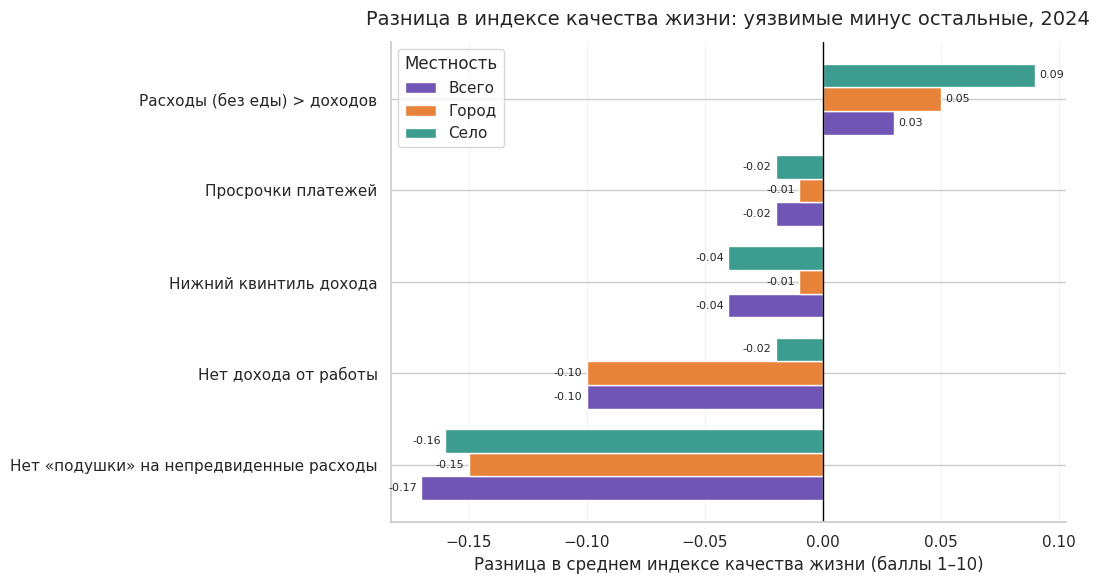

In [115]:
# График 1. Разница в качестве жизни по индикаторам
labels = {
    "v_low_income": "Нижний квинтиль дохода",
    "v_no_earned":  "Нет дохода от работы",
    "v_deficit":    "Расходы (без еды) > доходов",
    "v_arrears":    "Просрочки платежей",
    "v_no_buffer":  "Нет «подушки» на непредвиденные расходы",
}
plot = h3_1.copy()
plot["Индикатор"] = plot["indicator"].map(labels)
order = plot[plot["Местность"] == "Всего"].sort_values("qol_diff")["Индикатор"].tolist()
colors = {"Всего": "#7155B5", "Город": "#E8833A", "Село": "#3B9C8F"}

fig, ax = plt.subplots(figsize=(11, 6))
h = 0.26
for k, loc in enumerate(["Всего", "Город", "Село"]):
    d = plot[plot["Местность"] == loc].set_index("Индикатор").reindex(order)
    ypos = [i + (k - 1) * h for i in range(len(order))]
    bars = ax.barh(ypos, d["qol_diff"], height=h, color=colors[loc], label=loc)
    ax.bar_label(bars, labels=[f"{v:.2f}" for v in d["qol_diff"]], padding=3, fontsize=8)
ax.axvline(0, color="black", linewidth=1)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
ax.set_title("Разница в индексе качества жизни: уязвимые минус остальные, 2024", fontsize=14, pad=12)
ax.set_xlabel("Разница в среднем индексе качества жизни (баллы 1–10)")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.legend(title="Местность")
plt.tight_layout()
plt.show()

In [116]:
# Градиент: индекс уязвимости и качество жизни (результат 2.2). Чем выше индекс `fvi` (число флагов уязвимости), тем ниже качество жизни? Группа 4 включает 4 и более флагов.
SQL_22 = """
-- 2.2 Градиент: чем выше индекс уязвимости, тем ниже качество жизни?
SELECT
    LEAST(fvi, 4)                    AS fvi_group,        -- 4 = «4 и более» флагов
    COUNT(*)                         AS n_households,
    ROUND(AVG(qol_index), 2)         AS avg_qol_index,
    ROUND(AVG(life_sat),  2)         AS avg_life_satisfaction
FROM h3
GROUP BY 1
ORDER BY 1;
"""
h3_2 = q(SQL_22)
show(h3_2)

,fvi_group,n_households,avg_qol_index,avg_life_satisfaction
0,0,6860,7.77,7.66
1,1,3210,7.69,7.56
2,2,1375,7.65,7.51
3,3,377,7.58,7.46
4,4,75,7.82,7.50


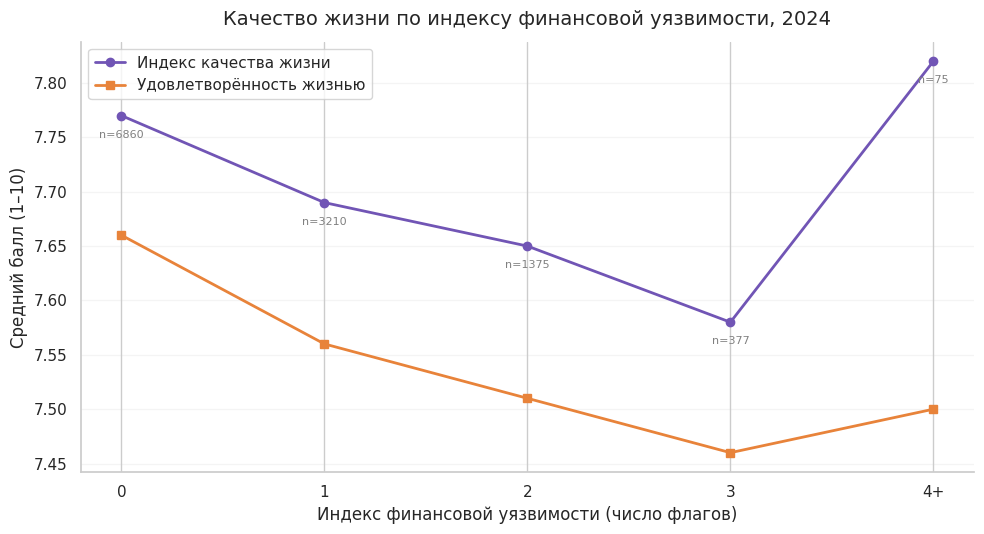

In [117]:
# График 2. Качество жизни по числу флагов уязвимости
fig, ax = plt.subplots(figsize=(10, 5.5))
x = h3_2["fvi_group"].astype(int)
ax.plot(x, h3_2["avg_qol_index"], marker="o", linewidth=2, color="#7155B5", label="Индекс качества жизни")
ax.plot(x, h3_2["avg_life_satisfaction"], marker="s", linewidth=2, color="#E8833A", label="Удовлетворённость жизнью")
for xi, yi, n in zip(x, h3_2["avg_qol_index"], h3_2["n_households"]):
    ax.annotate(f"n={n}", (xi, yi), textcoords="offset points", xytext=(0, -16), ha="center", fontsize=8, color="gray")
ax.set_xticks(list(x))
ax.set_xticklabels([str(v) if v < 4 else "4+" for v in x])
ax.set_title("Качество жизни по индексу финансовой уязвимости, 2024", fontsize=14, pad=12)
ax.set_xlabel("Индекс финансовой уязвимости (число флагов)")
ax.set_ylabel("Средний балл (1–10)")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.legend()
plt.tight_layout()
plt.show()

In [118]:
# Сила связи (результат 2.3). Корреляции Пирсона и Спирмена между индексом уязвимости `fvi` и качеством жизни. Для Спирмена считается t-статистика: при n порядка 10 тысяч значение |t| > 1,96 означает значимую связь на уровне 5 %.
SQL_23 = """
-- 2.3 Сила связи: Пирсон, Спирмен (по средним рангам) и t-статистика для Спирмена
--     При n ~ 10 тыс. |t| > 1.96 ⇒ связь значима на уровне 5 %.
WITH pairs AS (
    SELECT 'qol_index' AS outcome, fvi AS x, qol_index AS y FROM h3 WHERE qol_index IS NOT NULL
    UNION ALL
    SELECT 'life_sat',             fvi,      life_sat        FROM h3 WHERE life_sat  IS NOT NULL
),
ranked AS (
    SELECT outcome, x, y,
        RANK() OVER (PARTITION BY outcome ORDER BY x)
          + (COUNT(*) OVER (PARTITION BY outcome, x) - 1) / 2.0 AS rx,
        RANK() OVER (PARTITION BY outcome ORDER BY y)
          + (COUNT(*) OVER (PARTITION BY outcome, y) - 1) / 2.0 AS ry
    FROM pairs
)
SELECT
    outcome,
    COUNT(*)                                                                AS n,
    ROUND(CORR(x, y), 3)                                                    AS pearson_r,
    ROUND(CORR(rx, ry), 3)                                                  AS spearman_rho,
    ROUND(CORR(rx, ry) * SQRT((COUNT(*) - 2) / (1 - POW(CORR(rx, ry), 2))), 1) AS t_stat
FROM ranked
GROUP BY outcome;
"""
h3_3 = q(SQL_23)
show(h3_3)

,outcome,n,pearson_r,spearman_rho,t_stat
0,life_sat,11884,-0.04,-0.05,-5.30
1,qol_index,11897,-0.05,-0.05,-5.90


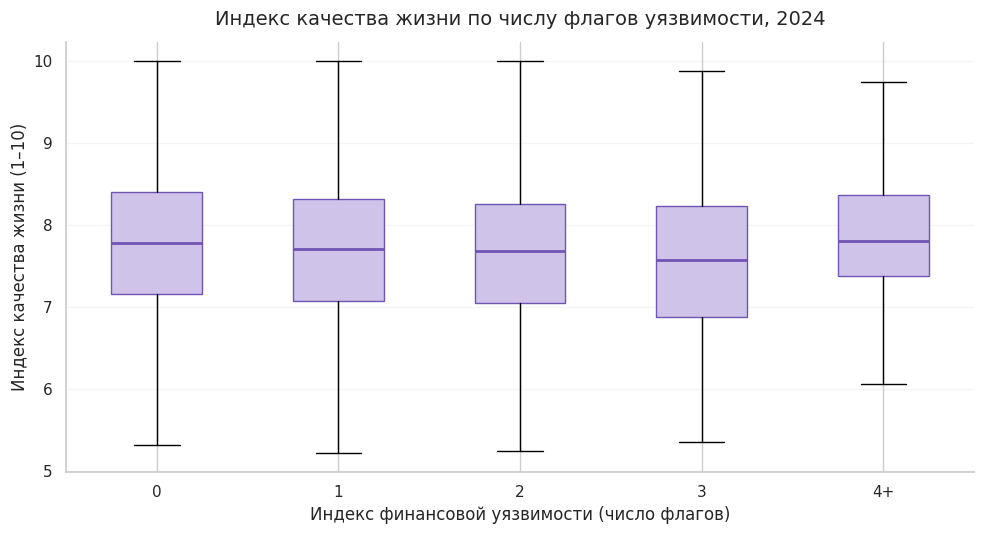

In [119]:
# График 3. Распределение индекса качества жизни по числу флагов
df_h3 = q("SELECT * FROM h3")
df_h3["fvi_group"] = df_h3["fvi"].clip(upper=4).astype(int)
groups = sorted(df_h3["fvi_group"].unique())
data = [df_h3.loc[df_h3["fvi_group"] == g, "qol_index"].dropna() for g in groups]

fig, ax = plt.subplots(figsize=(10, 5.5))
bp = ax.boxplot(data, patch_artist=True, showfliers=False)
ax.set_xticklabels([str(g) if g < 4 else "4+" for g in groups])
for box in bp["boxes"]:
    box.set(facecolor="#CFC3EA", edgecolor="#7155B5")
for med in bp["medians"]:
    med.set(color="#7155B5", linewidth=2)
ax.set_title("Индекс качества жизни по числу флагов уязвимости, 2024", fontsize=14, pad=12)
ax.set_xlabel("Индекс финансовой уязвимости (число флагов)")
ax.set_ylabel("Индекс качества жизни (1–10)")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

## ВЫВОДЫ ПО ПРОВЕРКЕ H3

**Гипотеза H3 подтверждается: связь отрицательная и статистически значимая, но практически малая.**

* **Выборка:** витрина 2024 года — 11 897 домохозяйств (6 524 городских, 5 373 сельских).
* **Сила связи:** корреляция индекса финансовой уязвимости (fvi) с индексом качества жизни: Пирсон −0,05, Спирмен −0,05 (t = −5,9); с общей удовлетворённостью жизнью — Пирсон −0,04, Спирмен −0,05 (t = −5,3). При n ≈ 12 тыс. связь значима, но по величине близка к нулю. Это обусловлено тем, что удовлетворенность жизнью является комплексным показателем, включающим в себя множество факторов помимо финансовых.
* **Градиент:** средний индекс качества жизни снижается с 7,77 у семей без флагов уязвимости до 7,69 (1 флаг), 7,65 (2) и 7,58 (3). Группа с 4+ флагами (75 семей) слишком мала для выводов.
* **Какие индикаторы «весят» больше:** сильнее всего снижает оценки отсутствие «подушки безопасности» на непредвиденные расходы (−0,17 по индексу качества жизни, −0,18 по удовлетворённости жизнью; в городе и на селе практически одинаково: −0,15 и −0,16), затем отсутствие дохода от работы (−0,10). Нижний квинтиль дохода и просрочки платежей дают разницу не более −0,04, а дефицит бюджета (расходы без еды > доходов) не снижает оценки вовсе (+0,03).

**Policy:** субъективное благополучие домохозяйств остаётся высоким (7,6–7,8 из 10) даже при финансовой уязвимости. Это согласуется с выводом анализа D002 о социальном капитале как «амортизаторе», но означает, что опросы удовлетворённости плохо выявляют скрытую уязвимость: для адресной политики нужны объективные индикаторы — наличие финансовой «подушки» и доход от работы.

## ФОРМИРОВАНИЕ РЕШЕНИЙ
**1. Снижать риск финансового дефицита**
Фокусировать поддержку на низкодоходных группах и учитывать соотношение доходов и расходов, а не только уровень дохода.

**2. Формировать финансовую подушку**
Развивать механизмы стимулируемых накоплений, финансовой грамотности и профилактики долговой нагрузки.

**3. Укреплять устойчивые источники дохода**
Адресные программы занятости и доходов, особенно для территорий и групп с повышенным профилем уязвимости.

**4. Таргетировать по профилю риска**
Комбинировать доход, финансовый дефицит, наличие подушки, просрочки и место проживания.
